In [2]:
import os
import sys
from pathlib import Path

# Where the notebook actually lives
NOTEBOOK_DIR = Path(os.getcwd())

# Repo root = parent of notebooks
REPO_DIR = NOTEBOOK_DIR.parent

print("Notebook directory:", NOTEBOOK_DIR)
print("Repo directory:", REPO_DIR)

# Force CityLearn from cloned repo (optional, see note below)
sys.path.insert(0, str(REPO_DIR))

import citylearn
print("✅ citylearn loaded from:", citylearn.__file__)

# Choose climate: TX or VT
CLIMATE = "VT"  # or "VT"

DATASET_DIR = REPO_DIR / "data" / "datasets" / f"annex96_ce1_{CLIMATE.lower()}_neighborhood"
SCHEMA_PATH = DATASET_DIR / "schema.json"

print("\nClimate:", CLIMATE)
print("Dataset directory:", DATASET_DIR, "| exists:", DATASET_DIR.exists())
print("Schema path:", SCHEMA_PATH, "| exists:", SCHEMA_PATH.exists())


Notebook directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks
Repo directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1
✅ citylearn loaded from: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/__init__.py

Climate: VT
Dataset directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood | exists: True
Schema path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/schema.json | exists: True


In [3]:
import pandas as pd

district_target_df = pd.read_csv(DATASET_DIR / "district_target.csv")
district_target = district_target_df["district_load_target"].values

In [4]:
# system operations
import inspect
import os
import sys
import uuid
import warnings

# date and time
import datetime

# type hinting
from typing import Any

# User interaction
from ipywidgets import Button, HTML
from ipywidgets import Text, HBox, VBox

# data visualization
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from tqdm import tqdm

# data manipulation
from bs4 import BeautifulSoup
import math
import numpy as np
import pandas as pd
import random
import re
import requests
import simplejson as json

# cityLearn
from citylearn.agents.base import (
    BaselineAgent,
    Agent as RandomAgent
)
from citylearn.agents.rbc import HourRBC
from citylearn.agents.q_learning import TabularQLearning
from citylearn.citylearn import CityLearnEnv
from citylearn.data import DataSet
from citylearn.reward_function import RewardFunction, ComfortReward
from citylearn.wrappers import (
    NormalizedObservationWrapper,
    StableBaselines3Wrapper,
    TabularQLearningWrapper
)
from citylearn.agents.rbc import TemperatureBasedRBC
from citylearn.agents.rbc import PITemperatureController, PIDTemperatureController

# RL algorithms
from stable_baselines3 import SAC, PPO
import do_mpc

/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/sysid/__init__.py:15: UserWarning: The ONNX feature is not available. Please install the full version of do-mpc to access this feature.
  warnings.warn('The ONNX feature is not available. Please install the full version of do-mpc to access this feature.')
/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/opcua/__init__.py:14: UserWarning: The opcua feature is not available. Please install the full version of do-mpc to access this feature.
  warnings.warn('The opcua feature is not available. Please install the full version of do-mpc to access this feature.')


In [5]:
# set all plotted figures without margins
plt.rcParams['axes.xmargin'] = 0
plt.rcParams['axes.ymargin'] = 0
%matplotlib inline

# ignore deprecation warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [6]:
import json
import pandas as pd

# Load schema.json
with open(SCHEMA_PATH, "r") as f:
    schema = json.load(f)
root_directory = DATASET_DIR
print("Root directory:", root_directory)

Root directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood


In [7]:
building_name = 'resstock-amy2018-2021-release-1-247942'

filename = schema["buildings"][building_name]["energy_simulation"]
filepath = root_directory / filename

print("CSV file:", filepath, "| exists:", filepath.exists())

CSV file: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/resstock-amy2018-2021-release-1-247942.csv | exists: True


In [8]:
import importlib, helpers
importlib.reload(helpers)
from helpers import select_buildings, select_simulation_period, get_kpis, plot_building_kpis, plot_district_kpis, plot_building_load_profiles, plot_district_load_profiles, plot_battery_soc_profiles, plot_comfort, plot_comfort_with_lstm_1step, make_env, run_env, plot_simulation_summary





In [9]:
BUILDING_SELECTION_SEED = 42
BUILDING_COUNT = 1

# Keep the clean January -> February pipeline pinned to one known Vermont house.
BUILDINGS = [building_name]

print("Selected building(s):", BUILDINGS)


Selected building(s): ['resstock-amy2018-2021-release-1-247942']


In [10]:
PERIOD_SELECTION_SEED = 42
SIM_DAYS = 14  # two weeks

SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP = select_simulation_period(
    schema=schema,
    dataset_dir=DATASET_DIR,
    count=SIM_DAYS,
    seed=PERIOD_SELECTION_SEED
)

CENTRAL_AGENT = True

print("Simulation start:", SIMULATION_START_TIME_STEP)
print("Simulation end:", SIMULATION_END_TIME_STEP)
print("Duration (hours):", SIMULATION_END_TIME_STEP - SIMULATION_START_TIME_STEP + 1)


Simulation start: 0
Simulation end: 335
Duration (hours): 336


In [11]:
def make_env(
    reward_function=None,
    simulation_start_time_step=None,
    simulation_end_time_step=None,
    **kwargs
):
    """
    Create a CityLearn environment with optional reward function override.
    """

    base_kwargs = dict(
        schema=str(SCHEMA_PATH),
        root_directory=str(DATASET_DIR),
        central_agent=CENTRAL_AGENT,
        buildings=BUILDINGS,
        simulation_start_time_step=simulation_start_time_step
            if simulation_start_time_step is not None
            else SIMULATION_START_TIME_STEP,
        simulation_end_time_step=simulation_end_time_step
            if simulation_end_time_step is not None
            else SIMULATION_END_TIME_STEP,
        random_seed=RANDOM_SEED,
        active_actions=[
            'heating_device',
        ],
    )

    # Inject reward function if provided
    if reward_function is not None:
        base_kwargs["reward_function"] = reward_function

    # Allow further overrides
    base_kwargs.update(kwargs)

    return CityLearnEnv(**base_kwargs)

In [12]:
def run_env(env, agent):
    obs, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):
        actions = agent.predict(obs)
        obs, reward, terminated, truncated, info = env.step(actions)

    return env

In [13]:
import numpy as np

def collect_trajectories(env, agent, save_path=None, seed=None):
    """
    Run controller in CityLearn and collect RL transitions:
    (state, action, reward, next_state, done)
    """

    states, actions, rewards, next_states, dones = [], [], [], [], []

    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, info = env.reset(seed=seed)
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action = agent.predict(obs)

        next_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # store transition
        states.append(obs)
        actions.append(action)
        rewards.append(reward)
        next_states.append(next_obs)
        dones.append(done)

        obs = next_obs

    dataset = {
        "states": np.array(states, dtype=np.float32),
        "actions": np.array(actions, dtype=np.float32),
        "rewards": np.array(rewards, dtype=np.float32),
        "next_states": np.array(next_states, dtype=np.float32),
        "dones": np.array(dones, dtype=np.float32),
    }

    # optional save
    if save_path is not None:
        np.savez_compressed(save_path, **dataset)
        print(f"Dataset saved to: {save_path}")

    return env, dataset


In [14]:
from collections import deque
import numpy as np
from citylearn.reward_function import RewardFunction


class OccupantFeedbackReward(RewardFunction):
    """
    Paper-aligned reward:

        C_t^total = beta * C_t^discomfort + (1 - beta) * C_t^energy
        r_t = - C_t^total

    Discomfort cost:
        - if occupied and current feedback != 0:
              weighted sum of recent |feedback| values
        - if occupied and current feedback == 0:
              -epsilon
        - if unoccupied:
              0

    Notes:
    - The current feedback is appended BEFORE computing discomfort,
      so a fresh override is penalized immediately.
    - Energy cost is implemented using HVAC electricity consumption,
      normalized by nominal power, since that is what is directly
      available in CityLearn observations.
    """

    def __init__(
        self,
        env_metadata,
        beta=0.75,
        epsilon=0.05,
        feedback_horizon=4,
    ):
        super().__init__(env_metadata)
        self.beta = float(beta)
        self.epsilon = float(epsilon)
        self.feedback_horizon = int(feedback_horizon)

        self.feedback_buffers = []
        self.energy_scales = []

        if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])

        self.feedback_buffers = [
            deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
            for _ in range(n_buildings)
        ]

        self.energy_scales = []
        for i in range(n_buildings):
            building_metadata = self.env_metadata['buildings'][i]
            nominal_power = float(
                building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0
            )
            self.energy_scales.append(max(nominal_power, 1.0))

    def _discomfort_from_buffer(self, feedback_buffer):
        """
        Paper weighting:
            w_i = e - exp(i / h_f)

        We apply it from most recent to oldest.
        If h_f = H and the buffer contains:
            [oldest, ..., newest]
        then newest gets lag = 0, next lag = 1, etc.
        """
        discomfort = 0.0
        H = max(1, self.feedback_horizon)

        for lag, feedback in enumerate(reversed(feedback_buffer)):
            weight = np.e - np.exp((lag + 1) / H)
            discomfort += weight * abs(float(feedback))

        return float(discomfort)

    def calculate(self, observations):
        if len(self.feedback_buffers) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            feedback = float(o.get('occupant_feedback_signal', 0.0))
            occupied = float(o.get('occupant_count', 0.0)) > 0.0

            # Append first so current override is penalized immediately.
            self.feedback_buffers[i].append(feedback)

            if occupied and abs(feedback) > 0.0:
                discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
            elif occupied:
                discomfort_cost = -self.epsilon
            else:
                discomfort_cost = 0.0

            hvac_electricity = max(
                float(
                    o.get(
                        'heating_electricity_consumption',
                        o.get('net_electricity_consumption', 0.0)
                    )
                ),
                0.0,
            )

            energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
            energy_cost = hvac_electricity / max(energy_scale, 1.0)

            total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
            reward_list.append(-total_cost)

        if self.central_agent:
            return [sum(reward_list)]

        return reward_list

In [15]:
RANDOM_SEED = 49

HEATING_MONTHS = [1, 2, 3, 4, 10, 11, 12]
JAN_MONTH = 1
FEB_MONTH = 2
TRAINING_MONTHS = [JAN_MONTH]  # clean pipeline for now: January offline only

selected_building_name = BUILDINGS[0]
selected_filename = schema["buildings"][selected_building_name]["energy_simulation"]
selected_filepath = root_directory / selected_filename
selected_month_index = pd.read_csv(selected_filepath, usecols=["month"])

MONTH_TO_RANGE = {}
for month in sorted(selected_month_index["month"].unique()):
    month_rows = selected_month_index.index[selected_month_index["month"] == month]
    MONTH_TO_RANGE[int(month)] = (int(month_rows.min()), int(month_rows.max()))

missing_heating_months = [m for m in TRAINING_MONTHS if m not in HEATING_MONTHS]
if len(missing_heating_months) > 0:
    raise ValueError(f"Training months must stay within heating season: {missing_heating_months}")

JAN_START, JAN_END = MONTH_TO_RANGE[JAN_MONTH]
FEB_START, FEB_END = MONTH_TO_RANGE[FEB_MONTH]
SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP = JAN_START, JAN_END
CENTRAL_AGENT = True

# JAN_PI_DATASET_PATH = NOTEBOOK_DIR / "january_pi_dataset_comfort_raw.npz"
JAN_MPC_DATASET_PATH = NOTEBOOK_DIR / "january_mpc_dataset_comfort_raw.npz"
JAN_PI_DATASET_PATH = JAN_MPC_DATASET_PATH
# OFFLINE_CHECKPOINT_PATH = NOTEBOOK_DIR / "sac_jumpstart_offline_jan"
OFFLINE_CHECKPOINT_PATH = NOTEBOOK_DIR / "sac_jumpstart_offline_jan_mpc"
# OFFLINE_REPLAY_PATH = NOTEBOOK_DIR / "sac_jumpstart_offline_jan_replay.pkl"
OFFLINE_REPLAY_PATH = NOTEBOOK_DIR / "sac_jumpstart_offline_jan_mpc_replay.pkl"
# ONLINE_CHECKPOINT_PATH = NOTEBOOK_DIR / "sac_jumpstart_plus_feb_online"
ONLINE_CHECKPOINT_PATH = NOTEBOOK_DIR / "sac_jumpstart_plus_feb_online_from_mpc"

print("Selected building:", selected_building_name)
print("Heating months:", HEATING_MONTHS)
print("January window:", (JAN_START, JAN_END), "| steps=", JAN_END - JAN_START + 1)
print("February window:", (FEB_START, FEB_END), "| steps=", FEB_END - FEB_START + 1)
print("January jump-start dataset path:", JAN_PI_DATASET_PATH)


Selected building: resstock-amy2018-2021-release-1-247942
Heating months: [1, 2, 3, 4, 10, 11, 12]
January window: (0, 743) | steps= 744
February window: (744, 1415) | steps= 672
January jump-start dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/january_mpc_dataset_comfort_raw.npz


In [16]:
# env_pi_rbc = make_env(
#     reward_function=ComfortReward,
#     simulation_start_time_step=JAN_START,
#     simulation_end_time_step=JAN_END,
# )
#
# pi_rbc = PITemperatureController(env_pi_rbc)
#
# env_pi, january_dataset = collect_trajectories(
#     env_pi_rbc,
#     pi_rbc,
#     save_path=str(JAN_PI_DATASET_PATH)
# )
#
# plot_comfort(env_pi, title='January PI rollout (ComfortReward, no occupant)')

if not JAN_PI_DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Missing MPC jump-start dataset at {JAN_PI_DATASET_PATH}. Run the January MPC dataset cell in my_mpc.ipynb first."
    )

jumpstart_npz = np.load(JAN_PI_DATASET_PATH)
january_dataset = {key: np.asarray(jumpstart_npz[key]) for key in jumpstart_npz.files}
print("Loaded January jump-start dataset:", JAN_PI_DATASET_PATH)
print("Transitions:", len(january_dataset["states"]))
print("Keys:", list(january_dataset.keys()))


Loaded January jump-start dataset: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/january_mpc_dataset_comfort_raw.npz
Transitions: 743
Keys: ['states', 'actions', 'rewards', 'next_states', 'dones']


In [17]:
print(env_pi.unwrapped.evaluate())

NameError: name 'env_pi' is not defined

In [17]:
env_baseline = make_env(
    reward_function=ComfortReward,
    simulation_start_time_step=SIMULATION_START_TIME_STEP,
    simulation_end_time_step=SIMULATION_END_TIME_STEP,
)
baseline_model = BaselineAgent(env_baseline)
baseline_temp = run_env(env_baseline, baseline_model)

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [18]:
print(env_baseline.unwrapped.evaluate())

                                    cost_function     value  \
0                           all_time_peak_average  1.000000   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.000000   
5                              daily_peak_average  1.000000   
6                   discomfort_cold_delta_average  0.354771   
7                   discomfort_cold_delta_maximum  1.681904   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  0.154020   
11                   discomfort_hot_delta_maximum  1.588217   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.000000   
14                          discomfort_proportion  0.00

In [19]:
plot_simulation_summary({
    'Baseline': env_baseline,
    'PI': env_pi,
})

NameError: name 'env_pi' is not defined

In [ ]:
for k, v in january_dataset.items():
    print(k, v.shape, v.dtype)


states (743, 1, 28) float32
actions (743, 1, 1) float32
rewards (743, 1) float32
next_states (743, 1, 28) float32
dones (743,) float32


In [ ]:
# 1b) January PI datasets with occupant overrides
from copy import deepcopy
import gymnasium as gym

class Occupant:
    def __init__(self, T_pref, b, max_prob=0.4, duration=3):
        self.T_pref = T_pref
        self.b = b
        self.max_prob = max_prob
        self.duration = duration

        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False

    def prob_increase(self, Tin):
        delta = max(0.0, self.T_pref - Tin)
        return min(0.002 * np.exp(self.b * delta), self.max_prob)

    def prob_decrease(self, Tin):
        delta = max(0.0, Tin - self.T_pref)
        return min(0.002 * np.exp(self.b * delta), self.max_prob)

    def override_delta(self, p_override):
        if p_override < 0.2:
            return 0.5
        if p_override < 0.4:
            return 1.0
        return 2.0

    def step(self, Tin, scheduled_Tsp):
        self.last_override_started = False

        if self.override_timer > 0:
            self.override_timer -= 1
            return self.override_setpoint

        p_inc = self.prob_increase(Tin)
        p_dec = self.prob_decrease(Tin)
        r = np.random.rand()

        if r < p_inc:
            new_sp = scheduled_Tsp + self.override_delta(p_inc)
        elif r < p_inc + p_dec:
            new_sp = scheduled_Tsp - self.override_delta(p_dec)
        else:
            self.override_setpoint = None
            return scheduled_Tsp

        self.override_setpoint = new_sp
        self.override_timer = max(self.duration - 1, 0)
        self.last_override_started = True
        return new_sp

class OccupantWrapper(gym.Wrapper):
    def __init__(self, env, occupant):
        super().__init__(env)
        self.observation_names = env.observation_names
        self.occupant = occupant

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0

        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation._indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step
        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])

        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1,
        )
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp)
        else:
            self.occupant.override_timer = 0
            self.occupant.override_setpoint = None
            self.occupant.last_override_started = False
            new_Tsp = scheduled_next_Tsp

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0

        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        return self.env.step(action)

january_occupant_specs = {
    'occ1': Occupant(T_pref=22, b=1.2, max_prob=0.4),
    'occ2': Occupant(T_pref=23, b=3.5, max_prob=0.4),
    'occ3': Occupant(T_pref=20, b=2.5, max_prob=0.4),
    'occ4': Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

january_occ_envs = {}
january_occ_datasets = {}
january_occ_summary_rows = []

def district_metric(kpis, cost_name):
    rows = kpis[(kpis['level'] == 'district') & (kpis['cost_function'] == cost_name)]['value']
    return float(rows.iloc[0]) if len(rows) > 0 else np.nan

for occ_idx, (short_name, occupant) in enumerate(january_occupant_specs.items(), start=1):
    print(f"\n🔥 January PI rollout with {short_name}")
    seed_local = int(RANDOM_SEED + occ_idx)
    np.random.seed(seed_local)
    random.seed(seed_local)

    env_pi_occ = make_env(
        reward_function=OccupantFeedbackReward,
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        random_seed=seed_local,
    )
    env_pi_occ = OccupantWrapper(env_pi_occ, deepcopy(occupant))
    pi_controller_occ = PITemperatureController(env_pi_occ)

    save_path = f"january_pi_dataset_{short_name}.npz"
    env_pi_occ, dataset_occ = collect_trajectories(
        env_pi_occ,
        pi_controller_occ,
        save_path=save_path,
        seed=seed_local,
    )

    january_occ_envs[short_name] = env_pi_occ
    january_occ_datasets[short_name] = dataset_occ

    kpis_occ = env_pi_occ.unwrapped.evaluate().copy()
    january_occ_summary_rows.append({
        'occupant': short_name,
        'save_path': save_path,
        'steps': int(dataset_occ['states'].shape[0]),
        'reward_sum': float(np.asarray(dataset_occ['rewards'], dtype=np.float32).sum()),
        'override_count': int(getattr(env_pi_occ, 'override_count', 0)),
        'electricity_consumption_total': district_metric(kpis_occ, 'electricity_consumption_total'),
        'discomfort_proportion': district_metric(kpis_occ, 'discomfort_proportion'),
        'discomfort_cold_proportion': district_metric(kpis_occ, 'discomfort_cold_proportion'),
        'discomfort_hot_proportion': district_metric(kpis_occ, 'discomfort_hot_proportion'),
    })

january_occ_summary = pd.DataFrame(january_occ_summary_rows)
display(january_occ_summary)



🔥 January PI rollout with occ1


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: january_pi_dataset_occ1.npz

🔥 January PI rollout with occ2


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: january_pi_dataset_occ2.npz

🔥 January PI rollout with occ3


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: january_pi_dataset_occ3.npz

🔥 January PI rollout with occ4


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: january_pi_dataset_occ4.npz


,occupant,save_path,steps,reward_sum,override_count,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion
0,occ1,january_pi_dataset_occ1.npz,743,-115.031296,92,0.772268,0.380753,0.206416,0.174338
1,occ2,january_pi_dataset_occ2.npz,743,-188.585449,157,0.781468,0.506276,0.232915,0.273361
2,occ3,january_pi_dataset_occ3.npz,743,-149.790314,123,0.774390,0.396095,0.206416,0.189679
3,occ4,january_pi_dataset_occ4.npz,743,-175.909119,146,0.778026,0.514644,0.234310,0.280335


In [20]:
# 1c) Inspect January PI overrides
OCCUPANT_TO_PLOT = 'occ4'  # change to occ2 / occ3 / occ4

env_plot = january_occ_envs[OCCUPANT_TO_PLOT]
b_plot = env_plot.unwrapped.buildings[0]

timesteps = np.arange(len(b_plot.energy_simulation.indoor_dry_bulb_temperature))
T_in = np.asarray(b_plot.energy_simulation.indoor_dry_bulb_temperature, dtype=np.float32)
T_sp_original = np.asarray(
    b_plot.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control,
    dtype=np.float32,
)
T_sp_override = np.asarray(
    b_plot.energy_simulation.indoor_dry_bulb_temperature_heating_set_point,
    dtype=np.float32,
)
feedback_signal = np.asarray(b_plot.energy_simulation.occupant_feedback_signal, dtype=np.float32)
override_idx = np.where(np.abs(feedback_signal) > 0)[0]

fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axs[0].plot(timesteps, T_in, label='Indoor temperature', linewidth=2)
axs[0].plot(timesteps, T_sp_original, '--', label='Original PI setpoint', linewidth=2, alpha=0.9)
axs[0].plot(timesteps, T_sp_override, label='Overridden setpoint', linewidth=2)
if len(override_idx) > 0:
    axs[0].scatter(
        override_idx,
        T_sp_override[override_idx],
        color='red',
        s=28,
        label='Override start',
        zorder=4,
    )

axs[0].fill_between(
    timesteps,
    20.0,
    24.0,
    color='gray',
    alpha=0.15,
    label='Comfort band (20-24 C)',
)
axs[0].set_ylabel('Temperature [C]')
axs[0].set_title(f'January PI rollout with occupant overrides: {OCCUPANT_TO_PLOT}')
axs[0].legend(loc='best')
axs[0].grid(True)

axs[1].step(timesteps, feedback_signal, where='post', label='occupant_feedback_signal', linewidth=2)
axs[1].axhline(0.0, color='black', linewidth=1)
axs[1].set_xlabel('Time step')
axs[1].set_ylabel('Feedback')
axs[1].legend(loc='best')
axs[1].grid(True)

plt.tight_layout()
plt.show()

print('Override count:', int(getattr(env_plot, 'override_count', 0)))
print('Override start indices (first 30):', override_idx[:30].tolist())
print('Total changed setpoints:', int(np.sum(np.abs(T_sp_override - T_sp_original) > 1e-6)))

override_preview = pd.DataFrame({
    'timestep': override_idx,
    'Tin': T_in[override_idx] if len(override_idx) > 0 else np.array([], dtype=np.float32),
    'original_setpoint': T_sp_original[override_idx] if len(override_idx) > 0 else np.array([], dtype=np.float32),
    'overridden_setpoint': T_sp_override[override_idx] if len(override_idx) > 0 else np.array([], dtype=np.float32),
    'feedback_signal': feedback_signal[override_idx] if len(override_idx) > 0 else np.array([], dtype=np.float32),
})
display(override_preview.head(20))


NameError: name 'january_occ_envs' is not defined

In [21]:
sac_env = make_env(reward_function=ComfortReward)
sac_env = NormalizedObservationWrapper(sac_env)
sac_env = StableBaselines3Wrapper(sac_env)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [22]:
from stable_baselines3 import SAC

sac_model = SAC(
    policy="MlpPolicy",
    env=sac_env,
    learning_starts=0,
    seed=RANDOM_SEED,
    verbose=1,
)


Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [23]:
import numpy as np

data = np.load("january_pi_dataset.npz")

states      = data["states"]        # (T, 1, 28)
actions     = data["actions"]       # (T, 1, 1)
rewards     = data["rewards"]       # (T, 1)
next_states = data["next_states"]   # (T, 1, 28)
dones       = data["dones"]         # (T,)


In [24]:
obs_dim_sac = sac_env.observation_space.shape[-1]   # 30
obs_dim_data = states.shape[-1]                     # 28
pad = obs_dim_sac - obs_dim_data                    # 2

def pad_obs(x):
    return np.pad(x, ((0,0),(0,0),(0,pad)), mode="constant")


In [25]:
states      = pad_obs(states)
next_states = pad_obs(next_states)


In [26]:
rb = sac_model.replay_buffer

for i in range(len(states)):
    rb.add(
        states[i],
        next_states[i],
        actions[i],
        float(rewards[i]),
        bool(dones[i]),
        infos={}
    )

print("Replay buffer size:", rb.size())


ValueError: could not broadcast input array from shape (0,) into shape (1,)

In [27]:
obs, _ = sac_env.reset()
print(obs.shape)


(30,)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [28]:
from stable_baselines3 import SAC
import numpy as np

# --- env (28-dim, no normalization wrapper) ---
sac_env = make_env(reward_function=ComfortReward)
sac_env = StableBaselines3Wrapper(sac_env)

# --- model ---
sac_model = SAC(
    policy="MlpPolicy",
    env=sac_env,
    learning_starts=0,
    seed=RANDOM_SEED,
    verbose=1,
)

# 🔴 REQUIRED for offline training
sac_model._setup_learn(total_timesteps=1)

# --- load PI dataset ---
data = np.load("january_pi_dataset.npz")

states      = data["states"]
actions     = data["actions"]
rewards     = data["rewards"]
next_states = data["next_states"]
dones       = data["dones"]

# --- fill replay buffer ---
rb = sac_model.replay_buffer

for i in range(len(states)):
    rb.add(
        states[i],
        next_states[i],
        actions[i],
        float(rewards[i].squeeze()),
        bool(dones[i]),
        infos=[{}],
    )

print("Replay buffer size:", rb.size())

# --- offline gradient training ---
GRADIENT_STEPS = 2_000
BATCH_SIZE = 256

for _ in range(GRADIENT_STEPS):
    sac_model.train(batch_size=BATCH_SIZE, gradient_steps=1)

# --- save ---
sac_model.save("sac_offline_from_PI_28dim")
print("✅ Offline SAC finished and saved.")


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Replay buffer size: 743


KeyboardInterrupt: 

# Check what RL has learnt in January

In [58]:
eval_env = make_env(
    simulation_start_time_step=SIMULATION_START_TIME_STEP,
    simulation_end_time_step=SIMULATION_END_TIME_STEP,
    reward_function=ComfortReward,
)

eval_env = StableBaselines3Wrapper(eval_env)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [59]:
from stable_baselines3 import SAC

sac_model = SAC.load("sac_offline_from_PI_28dim", env=eval_env)


Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [60]:
obs, _ = eval_env.reset()
done = False

while not done:
    action, _ = sac_model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = eval_env.step(action)
    done = terminated or truncated


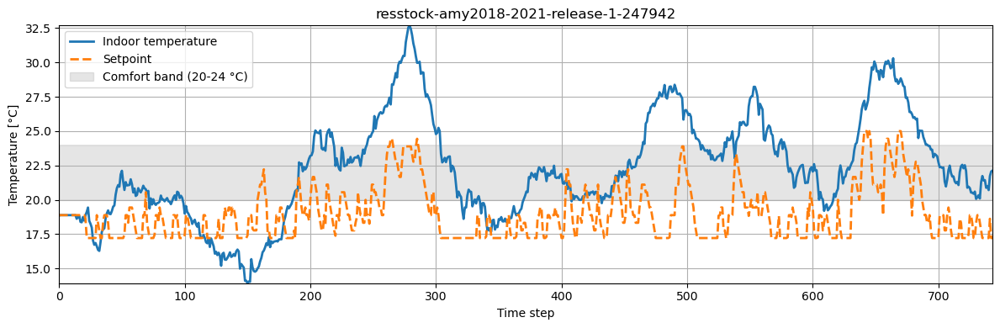

In [61]:
plot_comfort(eval_env)


In [62]:
print(eval_env.unwrapped.evaluate())

                                    cost_function      value  \
0                           all_time_peak_average   0.973725   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   0.853864   
5                              daily_peak_average   1.094782   
6                   discomfort_cold_delta_average   0.195722   
7                   discomfort_cold_delta_maximum   5.908653   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.043236   
10                   discomfort_hot_delta_average   3.346210   
11                   discomfort_hot_delta_maximum  11.135862   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.673640   
14                          discomfort_p

# Check what RL has learnt in February

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

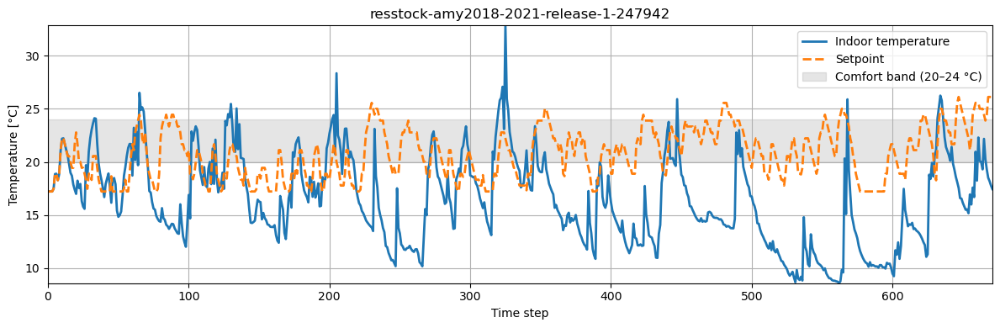

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (672,) + inhomogeneous part.

In [ ]:
FEB_START = SIMULATION_END_TIME_STEP + 1
FEB_END = FEB_START + (28)*24 - 1  # example

feb_env = make_env(
    simulation_start_time_step=FEB_START,
    simulation_end_time_step=FEB_END,
    reward_function=ComfortReward,
)
feb_env = StableBaselines3Wrapper(feb_env)

# load WITHOUT env
model = SAC.load("sac_offline_from_PI_28dim", env=None)

# 🔴 MANUAL attach (bypass SB3 checks completely)
model.env = feb_env
model.n_envs = 1
model._vec_normalize_env = None

# rollout February
obs, _ = feb_env.reset()
done = False

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = feb_env.step(action)
    done = terminated or truncated

plot_comfort(feb_env)


# total_reward = float(np.sum(feb_env.unwrapped.rewards))
print("February total reward:", total_reward)





In [34]:
print(feb_env.unwrapped.evaluate())


                                    cost_function      value  \
0                           all_time_peak_average   0.967581   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.225451   
5                              daily_peak_average   1.062499   
6                   discomfort_cold_delta_average   4.625309   
7                   discomfort_cold_delta_maximum  15.669895   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.647328   
10                   discomfort_hot_delta_average   0.467457   
11                   discomfort_hot_delta_maximum  10.607216   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.108397   
14                          discomfort_p

# RUN PI on February

In [35]:
# --- February window ---
FEB_START = SIMULATION_END_TIME_STEP + 1
FEB_END   = FEB_START + 28*24 - 1   # 28 days

# --- build February env ---
feb_pi_env = make_env(
    simulation_start_time_step=FEB_START,
    simulation_end_time_step=FEB_END,
    reward_function=ComfortReward,
)

# PI works on raw CityLearn env (NO SB3 wrapper)
pi_controller = PITemperatureController(feb_pi_env)

# --- rollout full February episode ---
obs, _ = feb_pi_env.reset()
done = False

while not done:
    action = pi_controller.predict(obs)
    obs, reward, terminated, truncated, _ = feb_pi_env.step(action)
    done = terminated or truncated


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

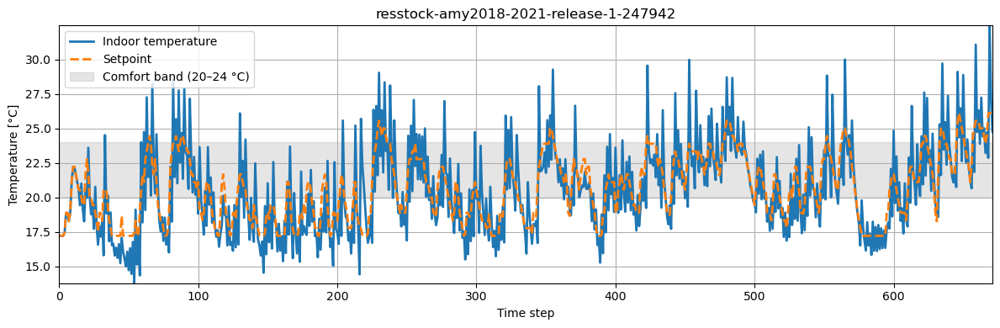

In [36]:
plot_comfort(feb_pi_env)


In [37]:
pi_kpis = feb_pi_env.evaluate()
print(pi_kpis)


                                    cost_function     value  \
0                           all_time_peak_average  0.941282   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.190129   
5                              daily_peak_average  0.998428   
6                   discomfort_cold_delta_average  0.851214   
7                   discomfort_cold_delta_maximum  5.089184   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.161832   
10                   discomfort_hot_delta_average  0.717768   
11                   discomfort_hot_delta_maximum  7.912468   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.145038   
14                          discomfort_proportion  0.30

# Train untrained RL online on February

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


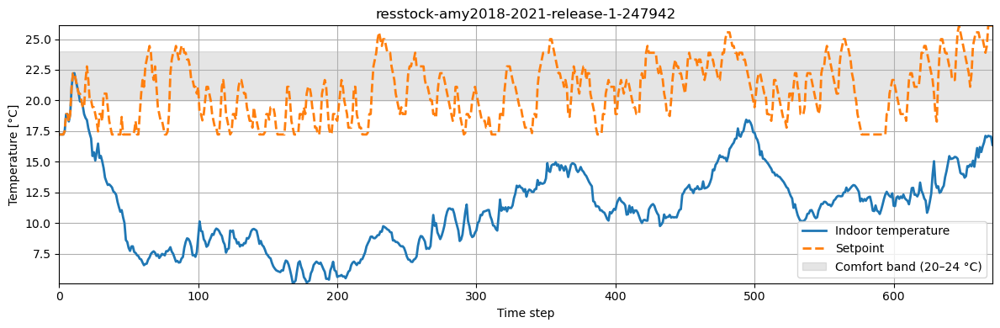

Fresh February KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   0.805708   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.209979   
5                              daily_peak_average   0.871984   
6                   discomfort_cold_delta_average   9.199513   
7                   discomfort_cold_delta_maximum  17.345757   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.969466   
10                   discomfort_hot_delta_average   0.000300   
11                   discomfort_hot_delta_maximum   0.109802   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.000000   
14                 

In [31]:
from stable_baselines3 import SAC

# --- February env ---
feb_env = make_env(
    simulation_start_time_step=FEB_START,
    simulation_end_time_step=FEB_END,
    reward_function=ComfortReward,
)
feb_env = StableBaselines3Wrapper(feb_env)

# --- brand-new SAC (no pretraining) ---
fresh_model = SAC(
    policy="MlpPolicy",
    env=feb_env,
    seed=RANDOM_SEED,
    verbose=1,
)

# --- train for ONE February episode ---
FEB_TIMESTEPS = feb_env.unwrapped.time_steps - 1
fresh_model.learn(total_timesteps=FEB_TIMESTEPS)

# --- rollout again for visualization ---
obs, _ = feb_env.reset()
done = False

while not done:
    action, _ = fresh_model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = feb_env.step(action)
    done = terminated or truncated

plot_comfort(feb_env)

print("Fresh February KPIs:")
print(feb_env.unwrapped.evaluate())


# Train pre-trained RL on February (1 episode)

In [63]:
jan_env = StableBaselines3Wrapper(make_env(reward_function=ComfortReward))
JAN_OBS_SPACE = jan_env.observation_space


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [64]:
feb_env = make_env(
    simulation_start_time_step=FEB_START,
    simulation_end_time_step=FEB_END,
    reward_function=ComfortReward,
)
feb_env = StableBaselines3Wrapper(feb_env)

# 🔴 override Box to January bounds
feb_env.observation_space = JAN_OBS_SPACE


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [65]:
from stable_baselines3 import SAC
from stable_baselines3.common.vec_env import DummyVecEnv

feb_vec_env = DummyVecEnv([lambda: feb_env])

warm_model = SAC.load("sac_offline_from_PI_28dim", env=feb_vec_env)

FEB_TIMESTEPS = feb_vec_env.envs[0].unwrapped.time_steps - 1
warm_model.learn(total_timesteps=FEB_TIMESTEPS, reset_num_timesteps=False)


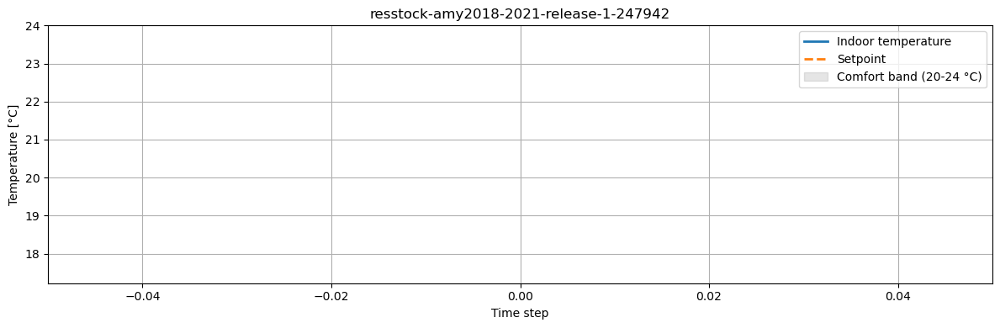

In [66]:
plot_comfort(feb_env)

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

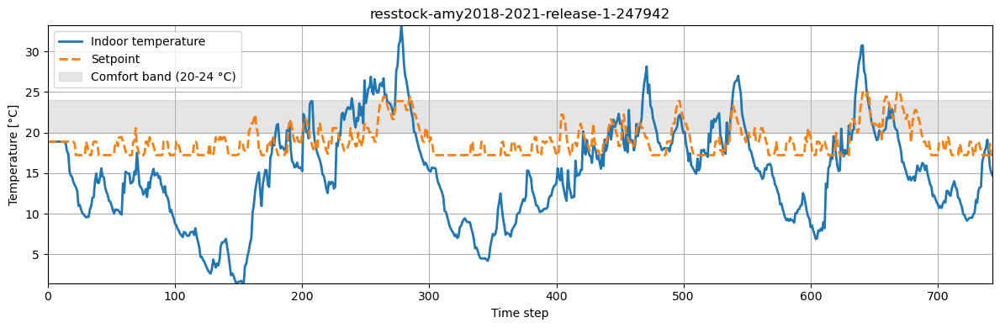

Warm-start February KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   1.166504   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.136971   
5                              daily_peak_average   0.970223   
6                   discomfort_cold_delta_average   4.294783   
7                   discomfort_cold_delta_maximum  17.368242   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.622036   
10                   discomfort_hot_delta_average   0.616826   
11                   discomfort_hot_delta_maximum   9.309425   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.128312   
14            

In [67]:
# --- rollout again for visualization (new env for clean history) ---
feb_eval_env = make_env()

obs, _ = feb_eval_env.reset()
done = False

while not done:
    action, _ = warm_model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = feb_eval_env.step(action)
    done = terminated or truncated

plot_comfort(feb_eval_env)

print("Warm-start February KPIs:")
print(feb_eval_env.unwrapped.evaluate())

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

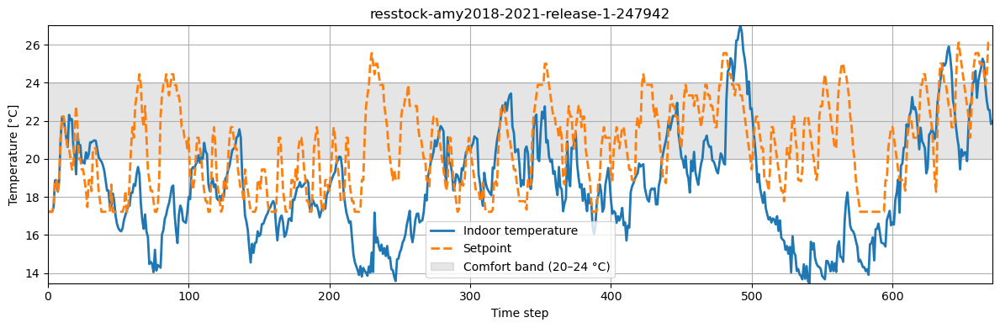

                                    cost_function      value  \
0                           all_time_peak_average   0.884271   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.035626   
5                              daily_peak_average   0.958983   
6                   discomfort_cold_delta_average   2.353055   
7                   discomfort_cold_delta_maximum  10.971587   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.470229   
10                   discomfort_hot_delta_average   0.356845   
11                   discomfort_hot_delta_maximum   3.673580   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.071756   
14                          discomfort_p

In [50]:
from stable_baselines3 import SAC
from stable_baselines3.common.vec_env import DummyVecEnv

# ---------- February VecEnv ----------
def make_feb_env():
    env = make_env(
        simulation_start_time_step=FEB_START,
        simulation_end_time_step=FEB_END,
        reward_function=ComfortReward,
    )
    return StableBaselines3Wrapper(env)

feb_vec = DummyVecEnv([make_feb_env])

# ---------- Fresh SAC on February ----------
model = SAC(
    "MlpPolicy",
    env=feb_vec,
    seed=RANDOM_SEED,
    verbose=1,
    ent_coef=10,   
    train_freq=1,
    # learning_rate=0.0003,
    # gradient_steps=,
)

# ---------- Load ONLY neural network weights from January ----------
jan_model = SAC.load("sac_offline_from_PI_28dim", env=None)

model.policy.load_state_dict(jan_model.policy.state_dict())

# ---------- Train for ONE February episode ----------
FEB_STEPS = feb_vec.envs[0].unwrapped.time_steps - 1
model.learn(total_timesteps=FEB_STEPS)

# ---------- Deterministic rollout for plotting ----------
feb_eval = make_feb_env()

obs, _ = feb_eval.reset()
done = False
while not done:
    act, _ = model.predict(obs, deterministic=True)
    obs, r, term, trunc, _ = feb_eval.step(act)
    done = term or trunc

plot_comfort(feb_eval)
print(feb_eval.unwrapped.evaluate())


In [28]:
print("model obs space:", model.observation_space)
print("feb vec obs space:", feb_vec.observation_space)


model obs space: Box([  1.           1.         -28.3          0.         -28.553085
 -28.357162   -28.898855     0.           0.           0.
  -2.7777786    0.38025025   0.           0.           0.
   0.          17.222221    17.222221     0.         -20.
 -20.           3.           0.          -4.4629707    0.
   0.           0.          -3.3       ], [  1.         24.         16.1       919.5        16.389288   16.424475
  16.613678  915.9976    905.3604    995.7681     44.999996    5.365362
  12.42885     0.         22.055605    1.6532834  25.         25.
   2.         20.         20.          3.          1.         23.21316
   0.          7.6920233   6.8557744   3.3      ], (28,), float32)
feb vec obs space: Box([  2.           1.         -18.3          0.         -18.51426
 -18.589092   -19.084635     0.           0.           0.
  -2.7777786    0.38001665   0.           0.           0.
   0.          17.222221    17.222221     0.         -20.
 -20.           3.           0.  

In [25]:
from stable_baselines3 import SAC

model = SAC.load("sac_offline_from_PI_28dim", env=None)


In [26]:
model.set_env(feb_vec, force_reset=False)

# Disable VecNormalize mismatch just in case
model._vec_normalize_env = None


ValueError: Observation spaces do not match: Box([  1.           1.         -28.3          0.         -28.553085
 -28.357162   -28.898855     0.           0.           0.
  -2.7777786    0.38025025   0.           0.           0.
   0.          17.222221    17.222221     0.         -20.
 -20.           3.           0.          -4.4629707    0.
   0.           0.          -3.3       ], [  1.         24.         16.1       919.5        16.389288   16.424475
  16.613678  915.9976    905.3604    995.7681     44.999996    5.365362
  12.42885     0.         22.055605    1.6532834  25.         25.
   2.         20.         20.          3.          1.         23.21316
   0.          7.6920233   6.8557744   3.3      ], (28,), float32) != Box([  2.           1.         -18.3          0.         -18.51426
 -18.589092   -19.084635     0.           0.           0.
  -2.7777786    0.38001665   0.           0.           0.
   0.          17.222221    17.222221     0.         -20.
 -20.           3.   

# Run Fully untrained RL on January

In [45]:
def rollout_episode(env, model):
    obs, _ = env.reset()
    done = False
    total_reward = 0.0

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        total_reward += float(reward)

    return env, total_reward


In [46]:
def make_january_eval_env():
    env = make_env(reward_function=ComfortReward)
    env = StableBaselines3Wrapper(env)
    return env


In [150]:
from stable_baselines3 import SAC

env_untrained = make_january_eval_env()

untrained_sac = SAC(
    policy="MlpPolicy",
    env=env_untrained,
    seed=RANDOM_SEED,
    verbose=0,
)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Untrained SAC reward: -177047.65896807614


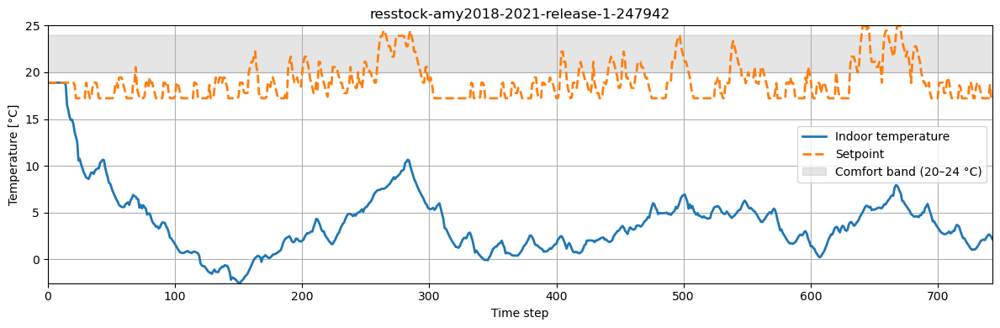

In [151]:
env_untrained, reward_untrained = rollout_episode(env_untrained, untrained_sac)

print("Untrained SAC reward:", reward_untrained)
plot_comfort(env_untrained)


In [39]:
FEB_DAYS = 28
FEB_START = SIMULATION_END_TIME_STEP + 1
FEB_END   = FEB_START + FEB_DAYS * 24 - 1


In [40]:
def make_period_env(start, end):
    env = make_env(
        reward_function=ComfortReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
    )
    env = NormalizedObservationWrapper(env)   # ← IMPORTANT
    env = StableBaselines3Wrapper(env)
    return env


In [43]:
SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP
jan_env = make_period_env(SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP)

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

# Train RL on 15 episodes on January, then test on February

In [61]:
from stable_baselines3 import SAC
from tqdm import tqdm

jan_env = make_period_env(SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP)

sac_model = SAC(
    policy="MlpPolicy",
    env=jan_env,
    seed=RANDOM_SEED,
    verbose=1,
)

sac_episodes = 15
timesteps = jan_env.unwrapped.time_steps - 1

for _ in tqdm(range(sac_episodes)):
    sac_model.learn(total_timesteps=timesteps, reset_num_timesteps=False)

sac_model.save("sac_trained_15eps_january_norm")


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


 20%|██        | 3/15 [00:16<01:08,  5.74s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 743       |
|    ep_rew_mean     | -1.14e+04 |
| time/              |           |
|    episodes        | 4         |
|    fps             | 128       |
|    time_elapsed    | 5         |
|    total_timesteps | 2972      |
| train/             |           |
|    actor_loss      | 168       |
|    critic_loss     | 253       |
|    ent_coef        | 1.01      |
|    ent_coef_loss   | 0.00223   |
|    learning_rate   | 0.0003    |
|    n_updates       | 2871      |
----------------------------------


 47%|████▋     | 7/15 [00:39<00:45,  5.71s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 743       |
|    ep_rew_mean     | -6.19e+03 |
| time/              |           |
|    episodes        | 8         |
|    fps             | 127       |
|    time_elapsed    | 5         |
|    total_timesteps | 5944      |
| train/             |           |
|    actor_loss      | 179       |
|    critic_loss     | 139       |
|    ent_coef        | 0.655     |
|    ent_coef_loss   | 0.00373   |
|    learning_rate   | 0.0003    |
|    n_updates       | 5843      |
----------------------------------


 73%|███████▎  | 11/15 [01:03<00:23,  5.78s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 743       |
|    ep_rew_mean     | -4.39e+03 |
| time/              |           |
|    episodes        | 12        |
|    fps             | 113       |
|    time_elapsed    | 6         |
|    total_timesteps | 8916      |
| train/             |           |
|    actor_loss      | 178       |
|    critic_loss     | 39.3      |
|    ent_coef        | 0.541     |
|    ent_coef_loss   | -0.0181   |
|    learning_rate   | 0.0003    |
|    n_updates       | 8815      |
----------------------------------


100%|██████████| 15/15 [01:28<00:00,  5.89s/it]


Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


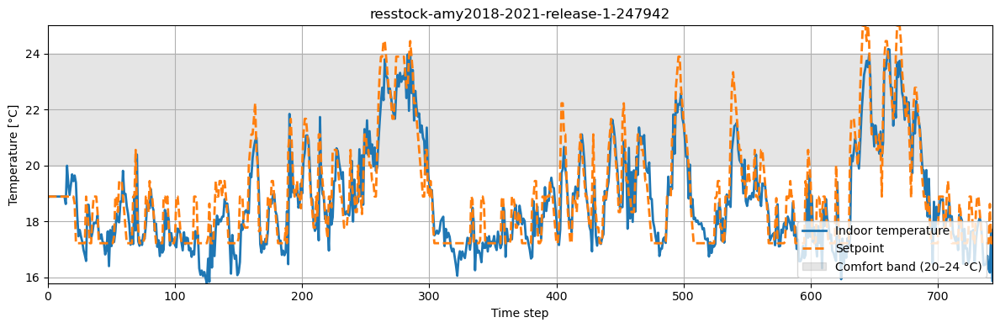

                                    cost_function     value  \
0                           all_time_peak_average  0.967056   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.027968   
5                              daily_peak_average  1.007196   
6                   discomfort_cold_delta_average  0.437136   
7                   discomfort_cold_delta_maximum  4.082966   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.043236   
10                   discomfort_hot_delta_average  0.221028   
11                   discomfort_hot_delta_maximum  2.164660   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.006974   
14                          discomfort_proportion  0.05

In [45]:
model = SAC.load("sac_trained_15eps_january_norm", env=jan_env)

obs, _ = jan_env.reset()
done = False

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = jan_env.step(action)
    done = terminated or truncated

plot_comfort(jan_env)
print(jan_env.unwrapped.evaluate())

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


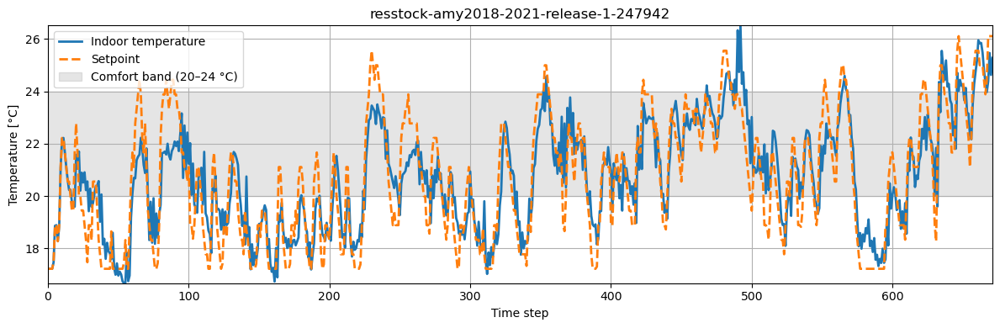

AttributeError: 'StableBaselines3Wrapper' object has no attribute 'rewards'

In [46]:
feb_env = make_period_env(FEB_START, FEB_END)

model = SAC.load("sac_trained_15eps_january_norm", env=feb_env)

obs, _ = feb_env.reset()
done = False

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = feb_env.step(action)
    done = terminated or truncated

plot_comfort(feb_env)
print("February total reward:", float(sum(feb_env.rewards)))


In [64]:
print(feb_env.unwrapped.evaluate())

                                    cost_function     value  \
0                           all_time_peak_average  0.948917   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.993435   
5                              daily_peak_average  1.001917   
6                   discomfort_cold_delta_average  0.438222   
7                   discomfort_cold_delta_maximum  2.859247   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.053435   
10                   discomfort_hot_delta_average  0.486548   
11                   discomfort_hot_delta_maximum  4.113190   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.038168   
14                          discomfort_proportion  0.09

In [174]:
obs, _ = jan_env.reset()
done = False

while not done:
    action, _ = sac_model.predict(obs, deterministic=True)
    obs, _, terminated, truncated, _ = jan_env.step(action)
    done = terminated or truncated

plot_comfort(jan_env)


AttributeError: 'TimeLimit' object has no attribute 'shared_observations'

In [16]:
from stable_baselines3 import SAC

# --- February env ---
feb_env = make_period_env(FEB_START, FEB_END)

# --- load model WITHOUT env ---
model = SAC.load("sac_trained_15eps_january_manual", env=None)

# --- BYPASS SB3 space check ---
model.env = feb_env
model._vec_normalize_env = None
model.n_envs = 1

# --- rollout February ---
obs, _ = feb_env.reset()
done = False

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, _ = feb_env.step(action)
    done = terminated or truncated

# --- plot ---
plot_comfort(feb_env)
print("February total reward:", float(sum(feb_env.rewards)))


NameError: name 'make_period_env' is not defined

## Improved Offline SAC Jump-Start (Stable + Comparable)

This section keeps wrappers/spaces consistent across offline pretraining, January evaluation, and February online fine-tuning.


In [23]:
from stable_baselines3 import SAC
from tqdm import tqdm
import gymnasium as gym
import numpy as np


REFERENCE_OBSERVATION_SPACE = None
REFERENCE_ACTION_SPACE = None


class FixedSpaceWrapper(gym.Wrapper):
    """Expose stable SB3 spaces across month slices while leaving observations untouched."""

    def __init__(self, env, observation_space, action_space):
        super().__init__(env)
        self._fixed_observation_space = observation_space
        self._fixed_action_space = action_space

    @property
    def observation_space(self):
        return self._fixed_observation_space

    @property
    def action_space(self):
        return self._fixed_action_space


def make_period_env(start, end, observation_space=None, action_space=None):
    """Single wrapper stack used everywhere in the clean SAC pipeline."""
    env = make_env(
        reward_function=ComfortReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
    )
    env = StableBaselines3Wrapper(env)

    fixed_observation_space = observation_space or REFERENCE_OBSERVATION_SPACE
    fixed_action_space = action_space or REFERENCE_ACTION_SPACE
    if fixed_observation_space is not None or fixed_action_space is not None:
        env = FixedSpaceWrapper(
            env,
            fixed_observation_space or env.observation_space,
            fixed_action_space or env.action_space,
        )

    return env


# Backwards-compatible alias for older exploratory cells below.
make_period_env_raw = make_period_env


def build_pi_period_dataset(start, end, dataset_path, force_rebuild=False):
    dataset_path = Path(dataset_path)

    if force_rebuild or not dataset_path.exists():
        env = make_env(
            reward_function=ComfortReward,
            simulation_start_time_step=start,
            simulation_end_time_step=end,
        )
        controller = PITemperatureController(env)
        env, dataset = collect_trajectories(env, controller, save_path=str(dataset_path))
        return env, dataset, "rebuilt"

    data = np.load(dataset_path)
    dataset = {key: np.asarray(data[key]) for key in data.files}
    return None, dataset, "loaded_existing"


def _ensure_transition_shape(name, x, expected_last_dim):
    if x.ndim != 3:
        raise ValueError(f"{name} must have shape (T, n_envs, dim); got {x.shape}")
    if x.shape[-1] != expected_last_dim:
        raise ValueError(
            f"{name} last dim mismatch: expected {expected_last_dim}, got {x.shape[-1]}. "
            "The clean pipeline assumes one wrapper stack with no raw/normalized mixing."
        )


def prefill_replay_buffer_from_npz(model, dataset_path):
    data = np.load(dataset_path)
    states = np.asarray(data["states"], dtype=np.float32)
    actions = np.asarray(data["actions"], dtype=np.float32)
    rewards = np.asarray(data["rewards"], dtype=np.float32)
    next_states = np.asarray(data["next_states"], dtype=np.float32)
    dones = np.asarray(data["dones"], dtype=bool)

    obs_dim = model.observation_space.shape[-1]
    act_dim = model.action_space.shape[-1]
    _ensure_transition_shape("states", states, obs_dim)
    _ensure_transition_shape("next_states", next_states, obs_dim)
    _ensure_transition_shape("actions", actions, act_dim)

    rb = model.replay_buffer

    for i in range(len(states)):
        obs_i = states[i].reshape(model.n_envs, obs_dim)
        next_obs_i = next_states[i].reshape(model.n_envs, obs_dim)
        act_i = actions[i].reshape(model.n_envs, act_dim)
        rew_i = np.asarray(rewards[i]).reshape(model.n_envs).astype(np.float32)
        done_i = np.asarray(dones[i]).reshape(model.n_envs)

        rb.add(
            obs_i,
            next_obs_i,
            act_i,
            rew_i,
            done_i,
            infos=[{} for _ in range(model.n_envs)],
        )

    return rb.size()


def rollout_and_kpis(model, start, end):
    env = make_period_env(start, end)
    obs, _ = env.reset()
    done = False
    total_reward = 0.0

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        total_reward += float(reward)

    return env, total_reward, env.unwrapped.evaluate()


def collect_period_into_replay(model, start, end, deterministic=True):
    env = make_period_env(start, end)
    obs, _ = env.reset()
    done = False
    total_reward = 0.0
    transitions = 0

    obs_dim = model.observation_space.shape[-1]
    act_dim = model.action_space.shape[-1]

    while not done:
        action, _ = model.predict(obs, deterministic=deterministic)
        next_obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        obs_i = np.asarray(obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        next_obs_i = np.asarray(next_obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        action_i = np.asarray(action, dtype=np.float32).reshape(model.n_envs, act_dim)
        reward_i = np.asarray([reward], dtype=np.float32).reshape(model.n_envs)
        done_i = np.asarray([done], dtype=bool).reshape(model.n_envs)

        model.replay_buffer.add(
            obs_i,
            next_obs_i,
            action_i,
            reward_i,
            done_i,
            infos=[{} for _ in range(model.n_envs)],
        )

        total_reward += float(reward)
        transitions += 1
        obs = next_obs

    return env, total_reward, env.unwrapped.evaluate(), transitions


def seed_online_replay_buffer(model, replay_buffer_path=OFFLINE_REPLAY_PATH, dataset_path=JAN_PI_DATASET_PATH):
    """Load saved offline replay buffer if available; fallback to the January PI dataset."""
    model._setup_learn(total_timesteps=1)
    replay_buffer_path = Path(replay_buffer_path)

    if replay_buffer_path.exists():
        model.load_replay_buffer(str(replay_buffer_path))
        return model.replay_buffer.size(), "loaded_saved_replay"

    size = prefill_replay_buffer_from_npz(model, dataset_path)
    return size, "prefilled_from_npz"


def set_sac_learning_rate(model, lr):
    optimizers = [model.actor.optimizer, model.critic.optimizer]
    if model.ent_coef_optimizer is not None:
        optimizers.append(model.ent_coef_optimizer)

    for optimizer in optimizers:
        for group in optimizer.param_groups:
            group["lr"] = lr


Experiment label: jan_pi_merlin_style_feb_mar
January exploration window: Jan 1-14 (0, 335)
Online learning/deployment window: Jan 15 - Mar 31 (336, 2159)
PI dataset mode: loaded_existing
PI dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/jan_pi_merlin_style_feb_mar_pi_dataset_comfort_raw.npz


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
January exploration replay size: 743
No separate offline pretraining block is run here.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Prefill-only January eval reward: -51493.976236497125
                                    cost_function         value  \
0                           all_time_peak_average  7.693714e-01   
1         annual_normalized_unserved_energy_total  6.120958e-10   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.406044e+00   
5                              daily_peak_average  7.237900e-01   
6                   discomfort_cold_delta_average  1.070996e+01   
7                   discomfort_cold_delta_maximum  2.146220e+01   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  9.475309e-01   
10                   discomfort_hot_delta_average  0.000000e+00   
11                   discomfort_hot_delta_maximum  0.000000e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13      

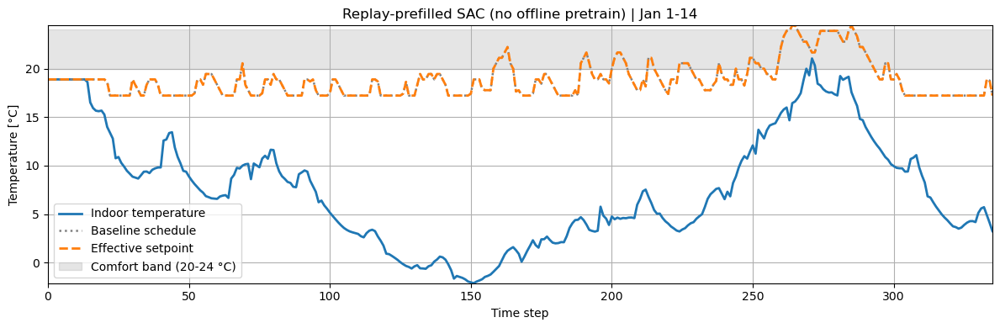

Saved prefill checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan_pi_merlin_style_feb_mar
Saved prefill replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan_pi_merlin_style_feb_mar_replay.pkl


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 15-21 | reward: -9486.758317084099
                                    cost_function      value  \
0                           all_time_peak_average   1.407891   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.029418   
5                              daily_peak_average   1.263780   
6                   discomfort_cold_delta_average   0.032183   
7                   discomfort_cold_delta_maximum   1.840444   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.000000   
10                   discomfort_hot_delta_average   5.981504   
11                   discomfort_hot_delta_maximum  17.256836   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion  

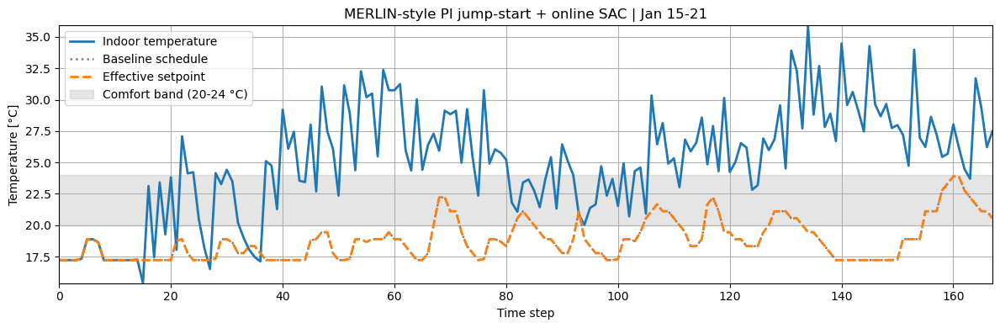

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 22-28 | reward: -6608.913386018703
                                    cost_function      value  \
0                           all_time_peak_average   0.831058   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.289041   
5                              daily_peak_average   0.977330   
6                   discomfort_cold_delta_average   4.427144   
7                   discomfort_cold_delta_maximum  13.521846   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.664557   
10                   discomfort_hot_delta_average   0.249517   
11                   discomfort_hot_delta_maximum   7.477459   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion  

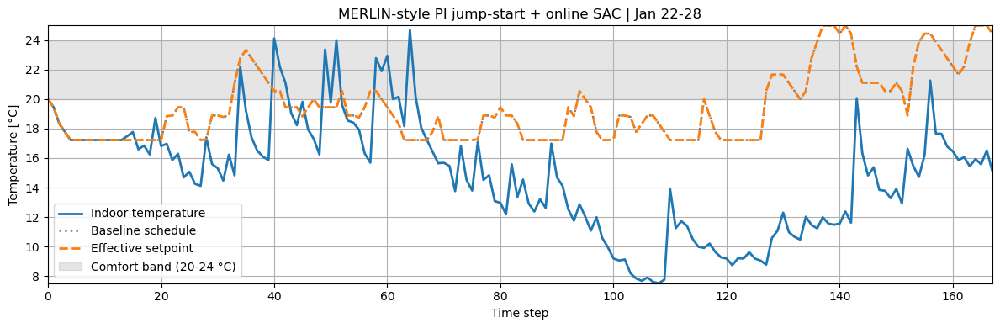

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 29 - Feb 4 | reward: -1373.5024251678278
                                    cost_function     value  \
0                           all_time_peak_average  1.309339   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.273874   
5                              daily_peak_average  1.184135   
6                   discomfort_cold_delta_average  1.488506   
7                   discomfort_cold_delta_maximum  9.919643   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.354037   
10                   discomfort_hot_delta_average  0.454978   
11                   discomfort_hot_delta_maximum  5.672983   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.099379

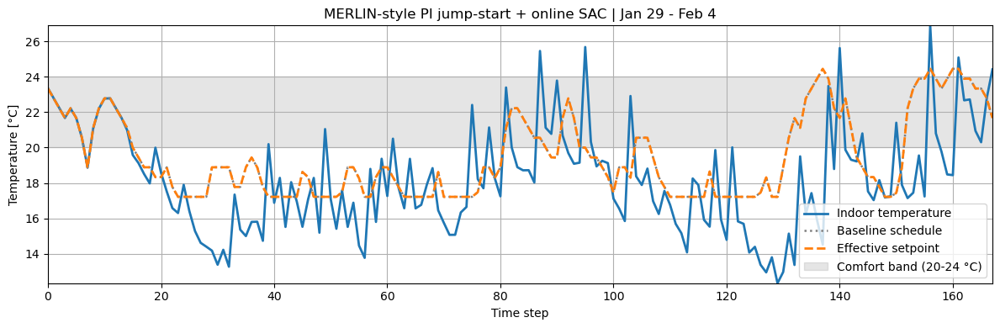

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 5-11 | reward: -889.019006262557
                                    cost_function     value  \
0                           all_time_peak_average  0.960796   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.080409   
5                              daily_peak_average  0.963102   
6                   discomfort_cold_delta_average  0.754578   
7                   discomfort_cold_delta_maximum  5.155972   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.167665   
10                   discomfort_hot_delta_average  0.969769   
11                   discomfort_hot_delta_maximum  7.708185   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.179641   
14  

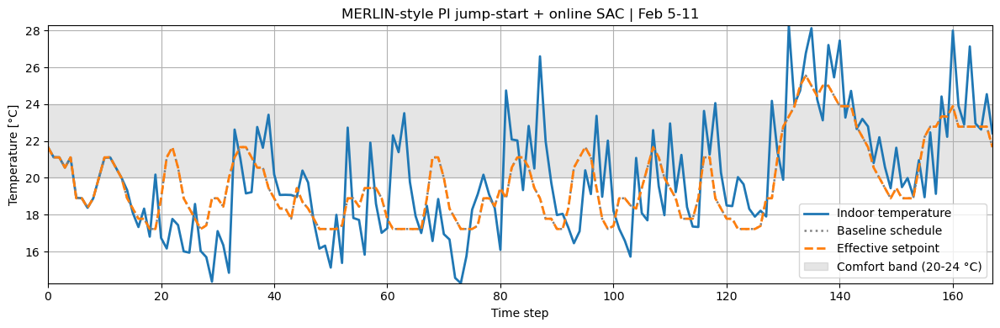

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 12-18 | reward: -672.0676185257216
                                    cost_function     value  \
0                           all_time_peak_average  1.034619   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.141475   
5                              daily_peak_average  1.072614   
6                   discomfort_cold_delta_average  0.332473   
7                   discomfort_cold_delta_maximum  3.094999   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.060606   
10                   discomfort_hot_delta_average  1.149499   
11                   discomfort_hot_delta_maximum  6.180296   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.230303   
14

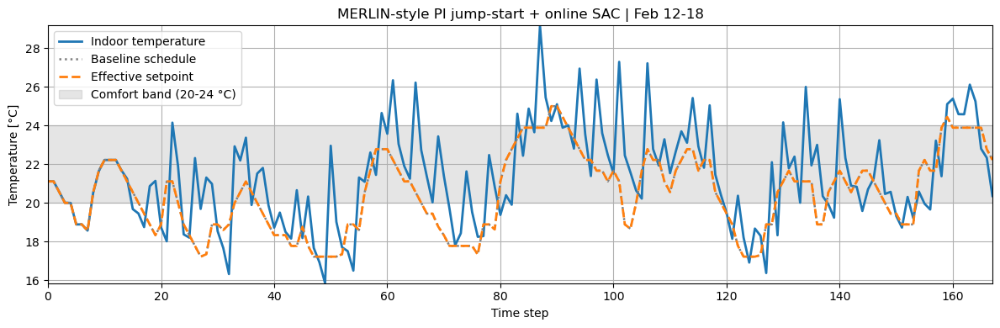

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 19-25 | reward: -832.9367694744542
                                    cost_function     value  \
0                           all_time_peak_average  1.069997   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.052335   
5                              daily_peak_average  1.106139   
6                   discomfort_cold_delta_average  0.096281   
7                   discomfort_cold_delta_maximum  2.756660   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.012346   
10                   discomfort_hot_delta_average  1.545798   
11                   discomfort_hot_delta_maximum  8.604610   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.345679   
14

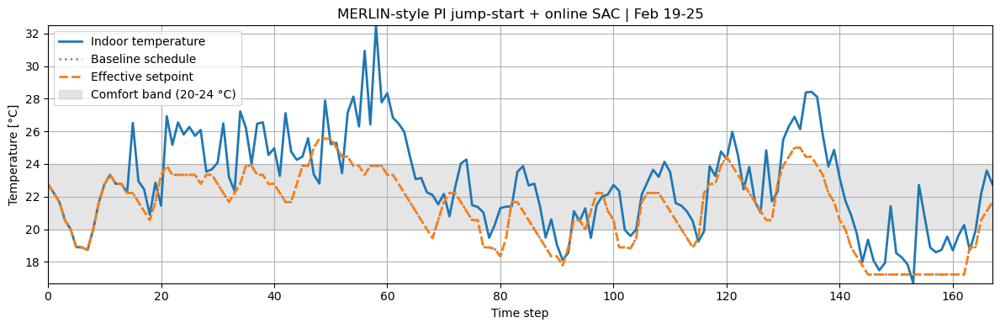

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 26 - Mar 4 | reward: -1098.6649676003544
                                    cost_function     value  \
0                           all_time_peak_average  1.095432   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.110894   
5                              daily_peak_average  1.117358   
6                   discomfort_cold_delta_average  0.102650   
7                   discomfort_cold_delta_maximum  1.912449   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  1.818374   
11                   discomfort_hot_delta_maximum  8.547169   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.418750

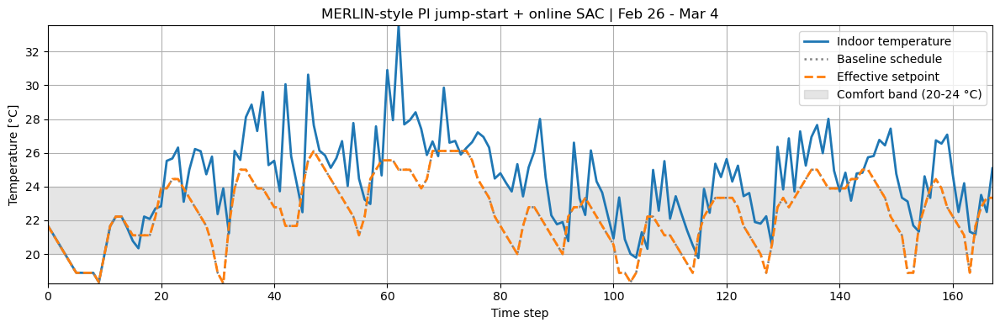

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full February eval after online learning: -8699.49308837549
                                    cost_function      value  \
0                           all_time_peak_average   1.034900   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.034351   
5                              daily_peak_average   1.121870   
6                   discomfort_cold_delta_average   0.028901   
7                   discomfort_cold_delta_maximum   2.954142   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.001527   
10                   discomfort_hot_delta_average   2.888175   
11                   discomfort_hot_delta_maximum  10.560930   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_propo

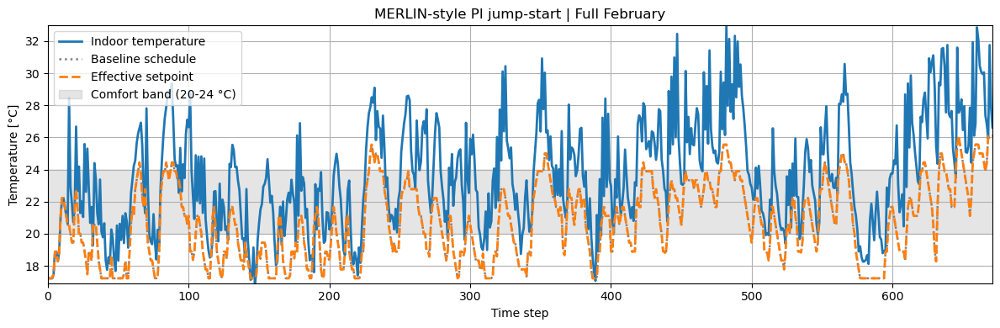

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 5-11 | reward: -1170.03127054777
                                    cost_function     value  \
0                           all_time_peak_average  0.971098   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.959682   
5                              daily_peak_average  0.964275   
6                   discomfort_cold_delta_average  0.069588   
7                   discomfort_cold_delta_maximum  1.644890   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  1.932270   
11                   discomfort_hot_delta_maximum  8.519342   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.475000   
14  

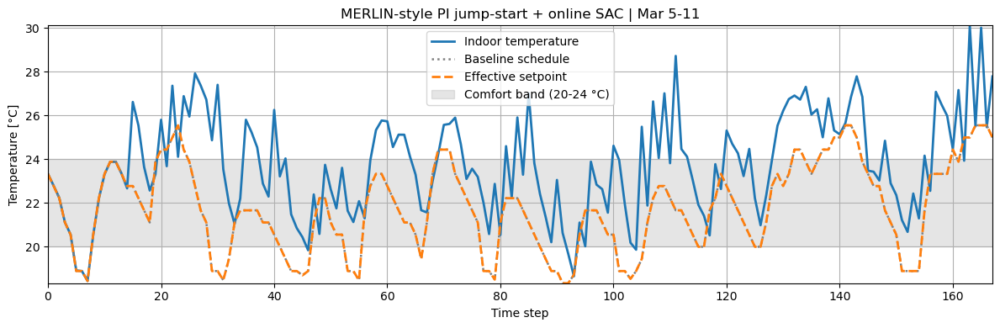

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 12-18 | reward: -1673.1825556529984
                                    cost_function         value  \
0                           all_time_peak_average  8.711864e-01   
1         annual_normalized_unserved_energy_total  5.624087e-10   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  9.900895e-01   
5                              daily_peak_average  9.841781e-01   
6                   discomfort_cold_delta_average  9.818613e-02   
7                   discomfort_cold_delta_maximum  2.479431e+00   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  1.863354e-02   
10                   discomfort_hot_delta_average  2.317382e+00   
11                   discomfort_hot_delta_maximum  8.060318e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13      

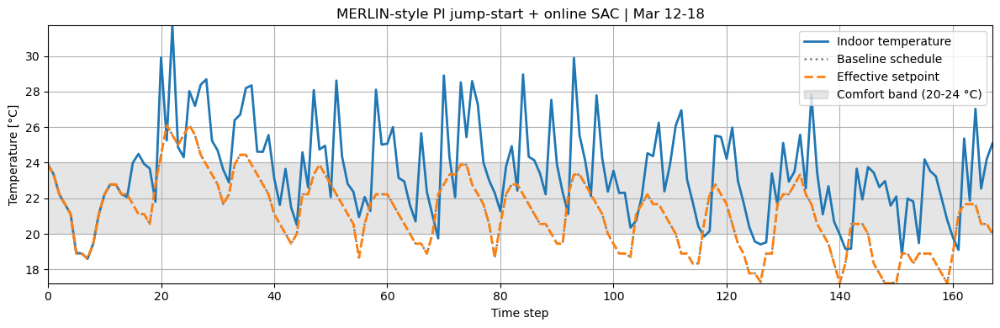

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 19-25 | reward: -2113.682449795
                                    cost_function         value  \
0                           all_time_peak_average  1.199418e+00   
1         annual_normalized_unserved_energy_total  1.147770e-09   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.026265e+00   
5                              daily_peak_average  1.063930e+00   
6                   discomfort_cold_delta_average  7.536696e-02   
7                   discomfort_cold_delta_maximum  2.788094e+00   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  6.211180e-03   
10                   discomfort_hot_delta_average  2.578625e+00   
11                   discomfort_hot_delta_maximum  1.045991e+01   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13          

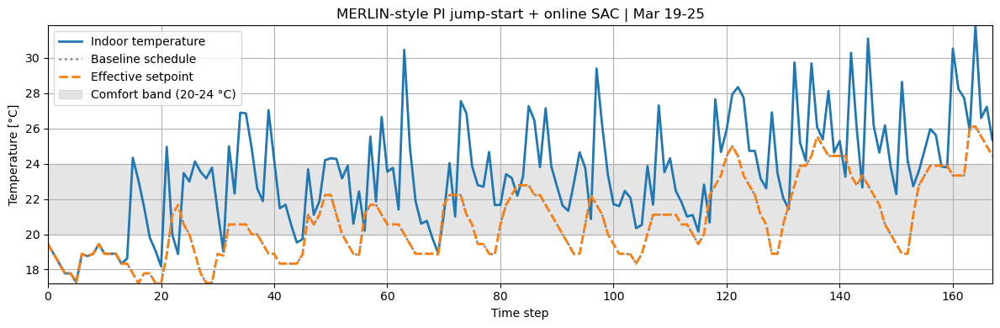

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 26-31 | reward: -1084.3412804047875
                                    cost_function     value  \
0                           all_time_peak_average  1.339728   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.069285   
5                              daily_peak_average  1.249145   
6                   discomfort_cold_delta_average  0.047686   
7                   discomfort_cold_delta_maximum  1.551685   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  2.100187   
11                   discomfort_hot_delta_maximum  6.623812   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.507042   
1

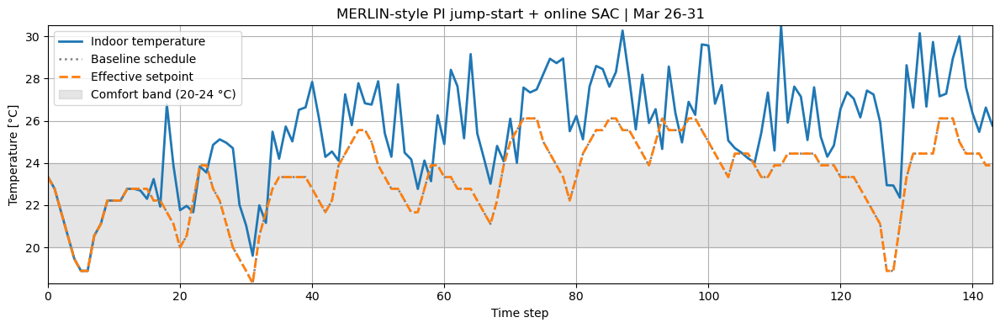

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full March eval after online learning: -5877.465729918629
                                    cost_function     value  \
0                           all_time_peak_average  1.047445   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.011957   
5                              daily_peak_average  1.092482   
6                   discomfort_cold_delta_average  0.043769   
7                   discomfort_cold_delta_maximum  2.142303   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.002809   
10                   discomfort_hot_delta_average  2.209956   
11                   discomfort_hot_delta_maximum  8.075758   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.540730 

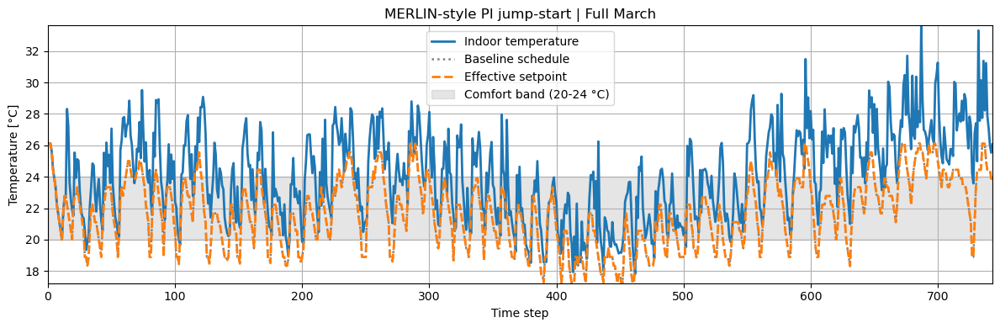

,week_idx,week_label,week_start,week_end,online_steps,updates_per_step,auto_ent_before_update,auto_ent_after_update,eval_reward_after_update,replay_size_after_update
0,1,Jan 15-21,336,503,167,2,1.000000,1.071298,-9486.758317,910
1,2,Jan 22-28,504,671,167,2,1.071298,1.068517,-6608.913386,1077
2,3,Jan 29 - Feb 4,672,839,167,2,1.068517,1.039858,-1373.502425,1244
3,4,Feb 5-11,840,1007,167,2,1.039858,1.001988,-889.019006,1411
4,5,Feb 12-18,1008,1175,167,2,1.001988,0.963952,-672.067619,1578
5,6,Feb 19-25,1176,1343,167,2,0.963952,0.931665,-832.936769,1745
6,7,Feb 26 - Mar 4,1344,1511,167,2,0.931665,0.896039,-1098.664968,1912
7,8,Mar 5-11,1512,1679,167,2,0.896039,0.856869,-1170.031271,2079
8,9,Mar 12-18,1680,1847,167,2,0.856869,0.809456,-1673.182556,2246
9,10,Mar 19-25,1848,2015,167,2,0.809456,0.755787,-2113.682450,2413


,month,month_start,month_end,eval_reward,replay_size_after_update
0,February,744,1415,-8699.493088,1912
1,March,1416,2159,-5877.465730,2556


Saved final checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan_pi_merlin_style_feb_mar
Saved final replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan_pi_merlin_style_feb_mar_replay.pkl


In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm
from stable_baselines3 import SAC

# ============================================================
# MERLIN-style adaptation using your January PI dataset
# ============================================================
# Key idea:
#   - January transitions are the "exploration phase"
#   - No separate offline pretraining block
#   - Start SAC updates only after the exploration phase
#   - From Feb onward, SAC acts online and keeps learning
#   - 2 gradient steps per environment step (MERLIN-style)
# ============================================================

MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

EXPERIMENT_OFFLINE_DAYS = 14     # January exploration phase
EXPERIMENT_WEEK_DAYS = 7
EXPERIMENT_FORCE_REBUILD = False
EXPERIMENT_PROGRESS_BAR = False
ENT_COEF = 'auto'

# MERLIN-like knobs
MERLIN_BATCH_SIZE = 256
MERLIN_BUFFER_SIZE = 100_000
MERLIN_GRADIENT_UPDATES_PER_STEP = 2
MERLIN_LR = 3e-4                      # keep SB3 default-ish unless you want to mimic CityLearn more aggressively
MERLIN_LEARNING_STARTS = 10**9            # disable SB3 auto-training; we train manually
MERLIN_NET_ARCH = [400, 400]              # matches MERLIN hidden_dimension better

experiment_label = f"jan_pi_merlin_style_feb_mar"
experiment_dataset_path = NOTEBOOK_DIR / f"{experiment_label}_pi_dataset_comfort_raw.npz"
experiment_ckpt_path = NOTEBOOK_DIR / f"sac_{experiment_label}"
experiment_replay_path = NOTEBOOK_DIR / f"sac_{experiment_label}_replay.pkl"

offline_seed_start = JAN_START
offline_seed_end = min(JAN_END, offline_seed_start + EXPERIMENT_OFFLINE_DAYS * 24 - 1)
online_start = offline_seed_end + 1
online_end = MAR_END

if online_start > online_end:
    raise ValueError("Online start is after the requested March end window.")

MONTH_LABELS = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}

def step_to_month_day(step):
    for month, (start, end) in MONTH_TO_RANGE.items():
        if start <= step <= end:
            day = int((step - start) // 24 + 1)
            return MONTH_LABELS.get(month, str(month)), day
    raise ValueError(f"Step {step} is outside MONTH_TO_RANGE.")

def format_window_label(start, end):
    start_month, start_day = step_to_month_day(start)
    end_month, end_day = step_to_month_day(end)
    if start_month == end_month:
        return f"{start_month} {start_day}-{end_day}"
    return f"{start_month} {start_day} - {end_month} {end_day}"

def current_auto_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

def manual_sac_updates(model, gradient_steps, batch_size=None):
    """Manual SB3 SAC updates from the current replay buffer."""
    batch_size = batch_size or model.batch_size
    for _ in range(gradient_steps):
        model.train(batch_size=batch_size, gradient_steps=1)

def collect_online_with_manual_updates(
    model,
    start,
    end,
    updates_per_step=2,
    deterministic=False,
):
    """
    Feb/Mar online phase:
      - model policy acts in env
      - transition added to replay
      - do updates_per_step manual SAC updates
    """
    env = make_period_env(start, end)
    obs, _ = env.reset()
    done = False
    total_reward = 0.0
    transitions = 0

    obs_dim = model.observation_space.shape[-1]
    act_dim = model.action_space.shape[-1]

    ent_before = current_auto_ent_coef(model)

    while not done:
        action, _ = model.predict(obs, deterministic=deterministic)

        next_obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        obs_i = np.asarray(obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        next_obs_i = np.asarray(next_obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        action_i = np.asarray(action, dtype=np.float32).reshape(model.n_envs, act_dim)
        reward_i = np.asarray([reward], dtype=np.float32).reshape(model.n_envs)
        done_i = np.asarray([done], dtype=bool).reshape(model.n_envs)

        model.replay_buffer.add(
            obs_i,
            next_obs_i,
            action_i,
            reward_i,
            done_i,
            infos=[{} for _ in range(model.n_envs)],
        )

        # MERLIN-style: update after adding each transition
        manual_sac_updates(model, gradient_steps=updates_per_step, batch_size=model.batch_size)

        total_reward += float(reward)
        transitions += 1
        obs = next_obs

    ent_after = current_auto_ent_coef(model)

    return {
        "env": env,
        "reward": total_reward,
        "kpis": env.unwrapped.evaluate(),
        "transitions": transitions,
        "auto_ent_before": ent_before,
        "auto_ent_after": ent_after,
    }

# ------------------------------------------------------------
# 1) Build/load January PI dataset
# ------------------------------------------------------------
seed_env, seed_dataset, seed_dataset_mode = build_pi_period_dataset(
    offline_seed_start,
    offline_seed_end,
    experiment_dataset_path,
    force_rebuild=EXPERIMENT_FORCE_REBUILD,
)

print("Experiment label:", experiment_label)
print("January exploration window:", format_window_label(offline_seed_start, offline_seed_end), (offline_seed_start, offline_seed_end))
print("Online learning/deployment window:", format_window_label(online_start, online_end), (online_start, online_end))
print("PI dataset mode:", seed_dataset_mode)
print("PI dataset path:", experiment_dataset_path)

# ------------------------------------------------------------
# 2) Build model with stable spaces
# ------------------------------------------------------------
seed_train_env = make_period_env(offline_seed_start, offline_seed_end)
REFERENCE_OBSERVATION_SPACE = seed_train_env.observation_space
REFERENCE_ACTION_SPACE = seed_train_env.action_space

policy_kwargs = dict(net_arch=MERLIN_NET_ARCH)

seasonal_model = SAC(
    policy="MlpPolicy",
    env=seed_train_env,
    seed=RANDOM_SEED,
    learning_rate=MERLIN_LR,
    batch_size=MERLIN_BATCH_SIZE,
    buffer_size=MERLIN_BUFFER_SIZE,
    learning_starts=MERLIN_LEARNING_STARTS,   # disable learn() training path
    train_freq=(1, "step"),
    gradient_steps=1,
    ent_coef=ENT_COEF,
    policy_kwargs=policy_kwargs,
    verbose=1,
)

# required before manual replay-buffer and train() usage
seasonal_model._setup_learn(total_timesteps=1)

# ------------------------------------------------------------
# 3) January = exploration phase only
#    Prefill replay buffer from PI dataset; no offline train loop
# ------------------------------------------------------------
exploration_replay_size = prefill_replay_buffer_from_npz(seasonal_model, experiment_dataset_path)
print(f"January exploration replay size: {exploration_replay_size}")
print("No separate offline pretraining block is run here.")

# Optional sanity evaluation of the untrained SAC after replay prefill
# This is usually not meaningful yet, because MERLIN starts learning only after the exploration phase.
seed_eval_env, seed_eval_reward, seed_eval_kpis = rollout_and_kpis(
    seasonal_model,
    offline_seed_start,
    offline_seed_end,
)
print("Prefill-only January eval reward:", seed_eval_reward)
print(seed_eval_kpis)
plot_comfort(
    seed_eval_env,
    title=f"Replay-prefilled SAC (no offline pretrain) | {format_window_label(offline_seed_start, offline_seed_end)}"
)

# Save state after exploration-phase prefill
seasonal_model.save(str(experiment_ckpt_path))
seasonal_model.save_replay_buffer(str(experiment_replay_path))
print(f"Saved prefill checkpoint: {experiment_ckpt_path}")
print(f"Saved prefill replay: {experiment_replay_path}")

# ------------------------------------------------------------
# 4) February + March online learning
#    Keep learning continuously with manual updates after each step
# ------------------------------------------------------------
weekly_results = []
monthly_results = []

feb_logged = False
mar_logged = False

for week_idx, week_start in enumerate(range(online_start, online_end + 1, EXPERIMENT_WEEK_DAYS * 24), start=1):
    week_end = min(online_end, week_start + EXPERIMENT_WEEK_DAYS * 24 - 1)
    week_label = format_window_label(week_start, week_end)

    result = collect_online_with_manual_updates(
        seasonal_model,
        start=week_start,
        end=week_end,
        updates_per_step=MERLIN_GRADIENT_UPDATES_PER_STEP,
        deterministic=False,
    )

    week_env = result["env"]
    week_reward = result["reward"]
    week_kpis = result["kpis"]

    print(f"Weekly eval | {week_label} | reward: {week_reward}")
    print(week_kpis)

    plot_comfort(
        week_env,
        title=f"MERLIN-style PI jump-start + online SAC | {week_label}",
    )

    weekly_results.append({
        "week_idx": week_idx,
        "week_label": week_label,
        "week_start": week_start,
        "week_end": week_end,
        "online_steps": result["transitions"],
        "updates_per_step": MERLIN_GRADIENT_UPDATES_PER_STEP,
        "auto_ent_before_update": result["auto_ent_before"],
        "auto_ent_after_update": result["auto_ent_after"],
        "eval_reward_after_update": float(week_reward),
        "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
    })

    # Full February eval once enough online learning has happened
    if not feb_logged and week_end >= FEB_END:
        feb_eval_env, feb_eval_reward, feb_eval_kpis = rollout_and_kpis(
            seasonal_model,
            FEB_START,
            FEB_END,
        )
        print("Full February eval after online learning:", feb_eval_reward)
        print(feb_eval_kpis)
        plot_comfort(feb_eval_env, title="MERLIN-style PI jump-start | Full February")
        monthly_results.append({
            "month": "February",
            "month_start": FEB_START,
            "month_end": FEB_END,
            "eval_reward": float(feb_eval_reward),
            "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
        })
        feb_logged = True

    # Full March eval at the end
    if not mar_logged and week_end >= MAR_END:
        mar_eval_env, mar_eval_reward, mar_eval_kpis = rollout_and_kpis(
            seasonal_model,
            MAR_START,
            MAR_END,
        )
        print("Full March eval after online learning:", mar_eval_reward)
        print(mar_eval_kpis)
        plot_comfort(mar_eval_env, title="MERLIN-style PI jump-start | Full March")
        monthly_results.append({
            "month": "March",
            "month_start": MAR_START,
            "month_end": MAR_END,
            "eval_reward": float(mar_eval_reward),
            "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
        })
        mar_logged = True

weekly_df = pd.DataFrame(weekly_results)
display(weekly_df)

monthly_df = pd.DataFrame(monthly_results)
display(monthly_df)

seasonal_model.save(str(experiment_ckpt_path))
seasonal_model.save_replay_buffer(str(experiment_replay_path))
print(f"Saved final checkpoint: {experiment_ckpt_path}")
print(f"Saved final replay: {experiment_replay_path}")

In [ ]:
# 10) Occupant PI jump-start -> online SAC with occupant overrides
# For each occupant:
#   1) collect/load January PI data while the occupant is actively overriding
#   2) prefill SAC replay from that occupant-specific PI dataset
#   3) continue online SAC with the same occupant and CurrentOccupantFeedbackReward

OCC_JUMPSTART_OFFLINE_DAYS = 14
OCC_JUMPSTART_WEEK_DAYS = 7
OCC_JUMPSTART_FORCE_REBUILD = True
OCC_JUMPSTART_PROGRESS_BAR = False
OCC_JUMPSTART_NORMALIZE_OBS = False

OCC_JUMPSTART_BATCH_SIZE = globals().get('MERLIN_BATCH_SIZE', 256)
OCC_JUMPSTART_BUFFER_SIZE = globals().get('MERLIN_BUFFER_SIZE', 100_000)
OCC_JUMPSTART_UPDATES_PER_STEP = globals().get('MERLIN_GRADIENT_UPDATES_PER_STEP', 2)
OCC_JUMPSTART_LR = globals().get('MERLIN_LR', 3e-4)
OCC_JUMPSTART_LEARNING_STARTS = 10**9
OCC_JUMPSTART_NET_ARCH = globals().get('MERLIN_NET_ARCH', [400, 400])
OCC_JUMPSTART_ENT_COEF = globals().get('ENT_COEF', 'auto')

MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

offline_seed_start = JAN_START
offline_seed_end = min(JAN_END, offline_seed_start + OCC_JUMPSTART_OFFLINE_DAYS * 24 - 1)
online_start = offline_seed_end + 1
online_end = MAR_END

if online_start > online_end:
    raise ValueError('Online start is after the requested March end window.')

def make_occ_jumpstart_env(
    start,
    end,
    occupant,
    normalize_obs=OCC_JUMPSTART_NORMALIZE_OBS,
    seed=None,
    observation_space=None,
    action_space=None,
):
    env = make_env(
        reward_function=DynamicComfortReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )
    occ_env = OccupantSACWrapper(env, deepcopy(occupant))
    rl_env = occ_env

    if normalize_obs:
        rl_env = NormalizedObservationWrapper(rl_env)

    rl_env = StableBaselines3Wrapper(rl_env)

    if observation_space is not None or action_space is not None:
        rl_env = FixedSpaceWrapper(
            rl_env,
            observation_space or rl_env.observation_space,
            action_space or rl_env.action_space,
        )

    return occ_env, rl_env

def build_pi_occ_period_dataset(start, end, occupant, dataset_path, force_rebuild=False, seed=None):
    dataset_path = Path(dataset_path)
    seed = int(RANDOM_SEED if seed is None else seed)

    if force_rebuild or not dataset_path.exists():
        np.random.seed(seed)
        random.seed(seed)

        env = make_env(
            reward_function=CurrentOccupantFeedbackReward,
            simulation_start_time_step=start,
            simulation_end_time_step=end,
            random_seed=seed,
        )
        occ_env = OccupantSACWrapper(env, deepcopy(occupant))
        controller = PITemperatureController(occ_env)
        occ_env, dataset = collect_trajectories(
            occ_env,
            controller,
            save_path=str(dataset_path),
            seed=seed,
        )
        return occ_env, dataset, 'rebuilt'

    data = np.load(dataset_path)
    dataset = {key: np.asarray(data[key]) for key in data.files}
    return None, dataset, 'loaded_existing'

def rollout_occ_jumpstart_model(model, start, end, occupant, observation_space, action_space, deterministic=True, seed=None):
    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)

    occ_env, rl_env = make_occ_jumpstart_env(
        start,
        end,
        occupant,
        seed=seed,
        observation_space=observation_space,
        action_space=action_space,
    )
    reward_sum = rollout_sb3_env(model, rl_env, deterministic=deterministic, seed=seed)
    return occ_env, reward_sum, occ_env.unwrapped.evaluate()

def collect_occ_online_with_manual_updates(
    model,
    start,
    end,
    occupant,
    observation_space,
    action_space,
    updates_per_step=2,
    deterministic=False,
    seed=None,
):
    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)

    occ_env, rl_env = make_occ_jumpstart_env(
        start,
        end,
        occupant,
        seed=seed,
        observation_space=observation_space,
        action_space=action_space,
    )

    obs, _ = rl_env.reset(seed=seed)
    terminated = truncated = False
    total_reward = 0.0
    transitions = 0

    obs_dim = model.observation_space.shape[-1]
    act_dim = model.action_space.shape[-1]

    ent_before = current_auto_ent_coef(model)

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=deterministic)
        next_obs, reward, terminated, truncated, _ = rl_env.step(action)
        done = terminated or truncated

        obs_i = np.asarray(obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        next_obs_i = np.asarray(next_obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        action_i = np.asarray(action, dtype=np.float32).reshape(model.n_envs, act_dim)
        reward_i = np.asarray([_scalar_reward(reward)], dtype=np.float32).reshape(model.n_envs)
        done_i = np.asarray([done], dtype=bool).reshape(model.n_envs)

        model.replay_buffer.add(
            obs_i,
            next_obs_i,
            action_i,
            reward_i,
            done_i,
            infos=[{} for _ in range(model.n_envs)],
        )

        manual_sac_updates(
            model,
            gradient_steps=updates_per_step,
            batch_size=model.batch_size,
        )

        total_reward += _scalar_reward(reward)
        transitions += 1
        obs = next_obs

    ent_after = current_auto_ent_coef(model)

    return {
        'env': occ_env,
        'reward': float(total_reward),
        'kpis': occ_env.unwrapped.evaluate(),
        'transitions': int(transitions),
        'override_count': int(getattr(occ_env, 'override_count', 0)),
        'auto_ent_before': ent_before,
        'auto_ent_after': ent_after,
    }

occupant_jumpstart_results = {}
occupant_jumpstart_weekly_rows = []
occupant_jumpstart_monthly_rows = []
occupant_jumpstart_summary_rows = []

for occ_idx, (label, occupant) in enumerate(SAC_OCCUPANT_SPECS.items(), start=1):
    print(f"\n{'=' * 80}\nPI jump-start + online SAC with occupant overrides | {label}\n{'=' * 80}")

    seed_local = int(RANDOM_SEED + 100 * occ_idx)
    experiment_label = f"{label}_jan{OCC_JUMPSTART_OFFLINE_DAYS}d_pi_occ_jumpstart_online_sac_feb_mar"
    experiment_dataset_path = NOTEBOOK_DIR / f"{experiment_label}_dataset.npz"
    experiment_ckpt_path = NOTEBOOK_DIR / f"sac_{experiment_label}"
    experiment_replay_path = NOTEBOOK_DIR / f"sac_{experiment_label}_replay.pkl"

    seed_env, seed_dataset, seed_dataset_mode = build_pi_occ_period_dataset(
        offline_seed_start,
        offline_seed_end,
        occupant,
        experiment_dataset_path,
        force_rebuild=OCC_JUMPSTART_FORCE_REBUILD,
        seed=seed_local,
    )

    print('Experiment label:', experiment_label)
    print('January PI occupant seed window:', format_window_label(offline_seed_start, offline_seed_end), (offline_seed_start, offline_seed_end))
    print('Online learning/deployment window:', format_window_label(online_start, online_end), (online_start, online_end))
    print('PI occupant dataset mode:', seed_dataset_mode)
    print('PI occupant dataset path:', experiment_dataset_path)
    if seed_env is not None:
        print('PI occupant seed overrides:', int(getattr(seed_env, 'override_count', 0)))

    seed_occ_env, seed_train_env = make_occ_jumpstart_env(
        offline_seed_start,
        offline_seed_end,
        occupant,
        seed=seed_local,
    )
    reference_observation_space = seed_train_env.observation_space
    reference_action_space = seed_train_env.action_space

    policy_kwargs = dict(net_arch=OCC_JUMPSTART_NET_ARCH)
    model = SAC(
        policy='MlpPolicy',
        env=seed_train_env,
        seed=seed_local,
        learning_rate=OCC_JUMPSTART_LR,
        batch_size=OCC_JUMPSTART_BATCH_SIZE,
        buffer_size=OCC_JUMPSTART_BUFFER_SIZE,
        learning_starts=OCC_JUMPSTART_LEARNING_STARTS,
        train_freq=(1, 'step'),
        gradient_steps=1,
        ent_coef=OCC_JUMPSTART_ENT_COEF,
        policy_kwargs=policy_kwargs,
        verbose=1,
    )
    model._setup_learn(total_timesteps=1)

    exploration_replay_size = prefill_replay_buffer_from_npz(model, experiment_dataset_path)
    print(f'January occupant PI exploration replay size: {exploration_replay_size}')
    print('No separate offline pretraining block is run here.')

    model.save(str(experiment_ckpt_path))
    model.save_replay_buffer(str(experiment_replay_path))
    print(f'Saved prefill checkpoint: {experiment_ckpt_path}')
    print(f'Saved prefill replay: {experiment_replay_path}')

    weekly_results = []
    monthly_results = []
    feb_logged = False
    mar_logged = False

    for week_idx, week_start in enumerate(range(online_start, online_end + 1, OCC_JUMPSTART_WEEK_DAYS * 24), start=1):
        week_end = min(online_end, week_start + OCC_JUMPSTART_WEEK_DAYS * 24 - 1)
        week_label = format_window_label(week_start, week_end)

        result = collect_occ_online_with_manual_updates(
            model,
            start=week_start,
            end=week_end,
            occupant=occupant,
            observation_space=reference_observation_space,
            action_space=reference_action_space,
            updates_per_step=OCC_JUMPSTART_UPDATES_PER_STEP,
            deterministic=False,
            seed=seed_local + week_idx,
        )

        week_env = result['env']
        week_reward = result['reward']
        week_kpis = result['kpis']

        print(f'Weekly eval | {label} | {week_label} | reward: {week_reward} | overrides: {result["override_count"]}')
        print(week_kpis)
        plot_comfort(
            week_env,
            title=f'{label} | PI jump-start + online SAC with overrides | {week_label}',
        )

        row = {
            'occupant': label,
            'week_idx': week_idx,
            'week_label': week_label,
            'week_start': week_start,
            'week_end': week_end,
            'online_steps': result['transitions'],
            'updates_per_step': OCC_JUMPSTART_UPDATES_PER_STEP,
            'override_count': result['override_count'],
            'auto_ent_before_update': result['auto_ent_before'],
            'auto_ent_after_update': result['auto_ent_after'],
            'eval_reward_after_update': float(week_reward),
            'replay_size_after_update': int(model.replay_buffer.size()),
        }
        weekly_results.append(row)
        occupant_jumpstart_weekly_rows.append(row)

        if not feb_logged and week_end >= FEB_END:
            feb_pi_env, feb_pi_reward = rollout_pi_occ_baseline(
                FEB_START,
                FEB_END,
                occupant,
                seed=seed_local + 10_000,
            )
            feb_eval_env, feb_eval_reward, feb_eval_kpis = rollout_occ_jumpstart_model(
                model,
                FEB_START,
                FEB_END,
                occupant,
                reference_observation_space,
                reference_action_space,
                deterministic=True,
                seed=seed_local + 10_000,
            )
            feb_pi_overrides = int(getattr(feb_pi_env, 'override_count', 0))
            feb_sac_overrides = int(getattr(feb_eval_env, 'override_count', 0))
            print(f'Full February PI baseline | {label}: reward={feb_pi_reward:.3f} | overrides={feb_pi_overrides}')
            print(f'Full February SAC eval | {label}: reward={feb_eval_reward:.3f} | overrides={feb_sac_overrides}')
            print(feb_eval_kpis)
            plot_comfort(feb_eval_env, title=f'{label} | PI jump-start SAC | Full February')
            month_row = {
                'occupant': label,
                'month': 'February',
                'month_start': FEB_START,
                'month_end': FEB_END,
                'pi_reward': float(feb_pi_reward),
                'sac_reward': float(feb_eval_reward),
                'pi_overrides': feb_pi_overrides,
                'sac_overrides': feb_sac_overrides,
                'override_delta_vs_pi': int(feb_sac_overrides - feb_pi_overrides),
                'replay_size_after_update': int(model.replay_buffer.size()),
                'electricity_consumption_total': _district_metric(feb_eval_kpis, 'electricity_consumption_total'),
                'discomfort_proportion': _district_metric(feb_eval_kpis, 'discomfort_proportion'),
                'discomfort_cold_proportion': _district_metric(feb_eval_kpis, 'discomfort_cold_proportion'),
                'discomfort_hot_proportion': _district_metric(feb_eval_kpis, 'discomfort_hot_proportion'),
                'daily_peak_average': _district_metric(feb_eval_kpis, 'daily_peak_average'),
            }
            monthly_results.append(month_row)
            occupant_jumpstart_monthly_rows.append(month_row)
            feb_logged = True

        if not mar_logged and week_end >= MAR_END:
            mar_eval_env, mar_eval_reward, mar_eval_kpis = rollout_occ_jumpstart_model(
                model,
                MAR_START,
                MAR_END,
                occupant,
                reference_observation_space,
                reference_action_space,
                deterministic=True,
                seed=seed_local + 20_000,
            )
            mar_sac_overrides = int(getattr(mar_eval_env, 'override_count', 0))
            print(f'Full March SAC eval | {label}: reward={mar_eval_reward:.3f} | overrides={mar_sac_overrides}')
            print(mar_eval_kpis)
            plot_comfort(mar_eval_env, title=f'{label} | PI jump-start SAC | Full March')
            month_row = {
                'occupant': label,
                'month': 'March',
                'month_start': MAR_START,
                'month_end': MAR_END,
                'pi_reward': np.nan,
                'sac_reward': float(mar_eval_reward),
                'pi_overrides': np.nan,
                'sac_overrides': mar_sac_overrides,
                'override_delta_vs_pi': np.nan,
                'replay_size_after_update': int(model.replay_buffer.size()),
                'electricity_consumption_total': _district_metric(mar_eval_kpis, 'electricity_consumption_total'),
                'discomfort_proportion': _district_metric(mar_eval_kpis, 'discomfort_proportion'),
                'discomfort_cold_proportion': _district_metric(mar_eval_kpis, 'discomfort_cold_proportion'),
                'discomfort_hot_proportion': _district_metric(mar_eval_kpis, 'discomfort_hot_proportion'),
                'daily_peak_average': _district_metric(mar_eval_kpis, 'daily_peak_average'),
            }
            monthly_results.append(month_row)
            occupant_jumpstart_monthly_rows.append(month_row)
            mar_logged = True

    model.save(str(experiment_ckpt_path))
    model.save_replay_buffer(str(experiment_replay_path))
    print(f'Saved final checkpoint: {experiment_ckpt_path}')
    print(f'Saved final replay: {experiment_replay_path}')

    feb_row = next((r for r in monthly_results if r['month'] == 'February'), None)
    mar_row = next((r for r in monthly_results if r['month'] == 'March'), None)

    occupant_jumpstart_results[label] = {
        'model': model,
        'dataset_path': experiment_dataset_path,
        'checkpoint_path': experiment_ckpt_path,
        'replay_path': experiment_replay_path,
        'weekly_results': pd.DataFrame(weekly_results),
        'monthly_results': pd.DataFrame(monthly_results),
    }

    occupant_jumpstart_summary_rows.append({
        'occupant': label,
        'seed_dataset_mode': seed_dataset_mode,
        'seed_dataset_path': str(experiment_dataset_path),
        'seed_replay_size': int(exploration_replay_size),
        'feb_pi_overrides': np.nan if feb_row is None else feb_row['pi_overrides'],
        'feb_sac_overrides': np.nan if feb_row is None else feb_row['sac_overrides'],
        'feb_override_delta_vs_pi': np.nan if feb_row is None else feb_row['override_delta_vs_pi'],
        'feb_sac_reward': np.nan if feb_row is None else feb_row['sac_reward'],
        'mar_sac_overrides': np.nan if mar_row is None else mar_row['sac_overrides'],
        'mar_sac_reward': np.nan if mar_row is None else mar_row['sac_reward'],
    })

occupant_jumpstart_weekly_df = pd.DataFrame(occupant_jumpstart_weekly_rows)
display(occupant_jumpstart_weekly_df)

occupant_jumpstart_monthly_df = pd.DataFrame(occupant_jumpstart_monthly_rows)
display(occupant_jumpstart_monthly_df)

occupant_jumpstart_summary = pd.DataFrame(occupant_jumpstart_summary_rows)
display(occupant_jumpstart_summary)



PI jump-start + online SAC with occupant overrides | occ1_tolerant


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/occ1_tolerant_jan14d_pi_occ_jumpstart_online_sac_feb_mar_dataset.npz
Experiment label: occ1_tolerant_jan14d_pi_occ_jumpstart_online_sac_feb_mar
January PI occupant seed window: Jan 1-14 (0, 335)
Online learning/deployment window: Jan 15 - Mar 31 (336, 2159)
PI occupant dataset mode: rebuilt
PI occupant dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/occ1_tolerant_jan14d_pi_occ_jumpstart_online_sac_feb_mar_dataset.npz
PI occupant seed overrides: 47
Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

RuntimeError: CUDA error: unspecified launch failure
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Experiment: continuous_pi_explore_14d_sac_to_mar
Continuous training window: Jan 1 - Mar 31 (0, 2159)
Exploration window: Jan 1-14 (0, 335)
Learning starts at step: 336
Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


Continuous PI->SAC loop:   0%|          | 0/2160 [01:37<?, ?it/s]
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this ex


Chunk eval | Jan 1-7
Collected chunk reward: -727.6690912209851
Deterministic eval reward: -27603.057431672634
                                    cost_function         value  \
0                           all_time_peak_average  7.991990e-01   
1         annual_normalized_unserved_energy_total  1.244173e-09   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.477261e+00   
5                              daily_peak_average  7.520977e-01   
6                   discomfort_cold_delta_average  1.054363e+01   
7                   discomfort_cold_delta_maximum  2.146219e+01   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  9.068323e-01   
10                   discomfort_hot_delta_average  0.000000e+00   
11                   discomfort_hot_delta_maximum  0.000000e+00   
12               

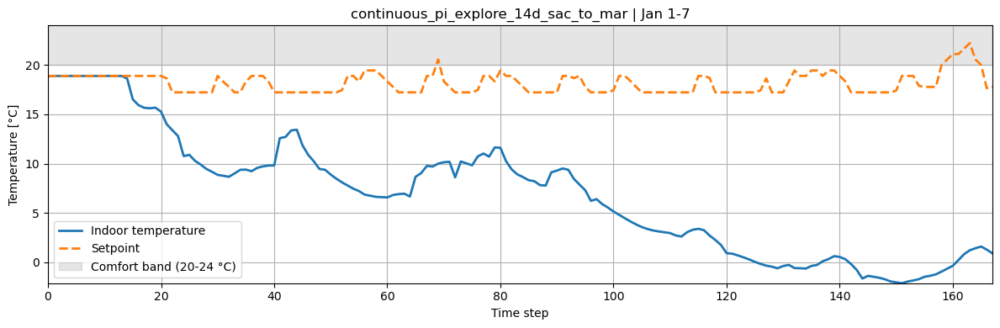

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Jan 8-14
Collected chunk reward: -566.8647720309464
Deterministic eval reward: -12770.263719530576
                                    cost_function      value  \
0                           all_time_peak_average   0.928285   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.282199   
5                              daily_peak_average   0.726659   
6                   discomfort_cold_delta_average   7.466532   
7                   discomfort_cold_delta_maximum  15.416326   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.871166   
10                   discomfort_hot_delta_average   0.000260   
11                   discomfort_hot_delta_maximum   0.014133   
12                   discomfort_hot_delta_minimum   0.0

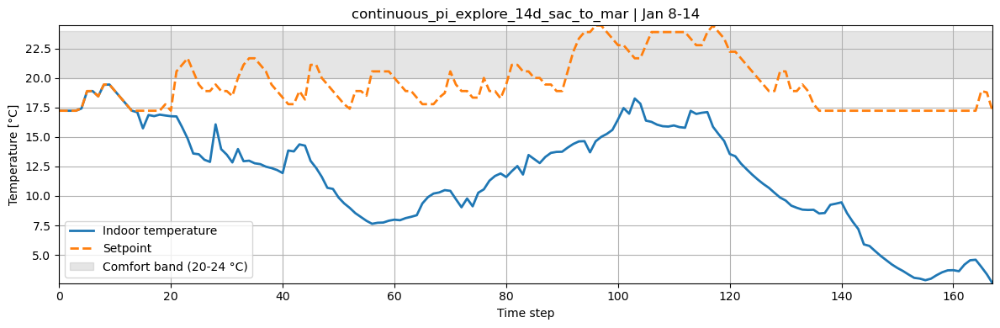

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Jan 15-21
Collected chunk reward: -12725.397885856737
Deterministic eval reward: -19596.51811182409
                                    cost_function      value  \
0                           all_time_peak_average   0.957119   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.244782   
5                              daily_peak_average   0.767755   
6                   discomfort_cold_delta_average   9.580113   
7                   discomfort_cold_delta_maximum  16.888927   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.901840   
10                   discomfort_hot_delta_average   0.000443   
11                   discomfort_hot_delta_maximum   0.045933   
12                   discomfort_hot_delta_minimum   0.

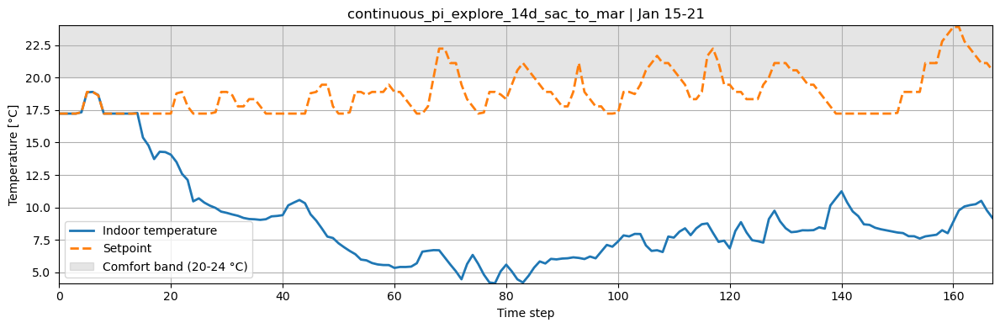

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Jan 22-28
Collected chunk reward: -6385.44596896153
Deterministic eval reward: -18752.13373669479
                                    cost_function      value  \
0                           all_time_peak_average   0.869265   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.303113   
5                              daily_peak_average   0.820866   
6                   discomfort_cold_delta_average   8.874615   
7                   discomfort_cold_delta_maximum  17.032749   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.892405   
10                   discomfort_hot_delta_average   0.001733   
11                   discomfort_hot_delta_maximum   0.262094   
12                   discomfort_hot_delta_minimum   0.00

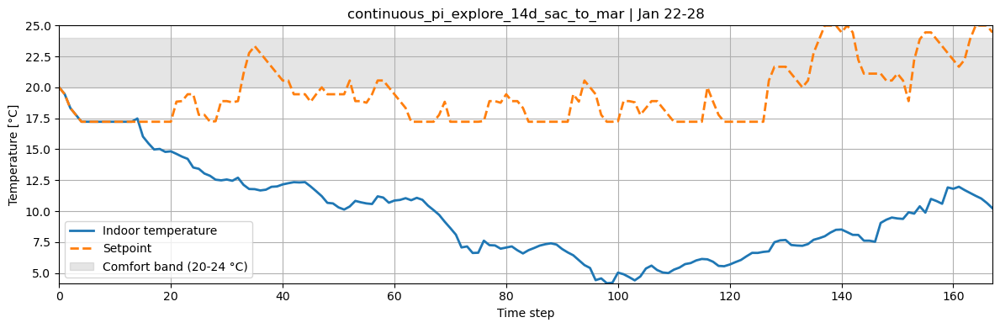

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Jan 29 - Feb 4
Collected chunk reward: -15122.858016182417
Deterministic eval reward: -18723.21411272058
                                    cost_function      value  \
0                           all_time_peak_average   1.000000   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.292363   
5                              daily_peak_average   0.859897   
6                   discomfort_cold_delta_average   8.653633   
7                   discomfort_cold_delta_maximum  19.341080   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.857143   
10                   discomfort_hot_delta_average   0.000706   
11                   discomfort_hot_delta_maximum   0.027727   
12                   discomfort_hot_delta_minimum

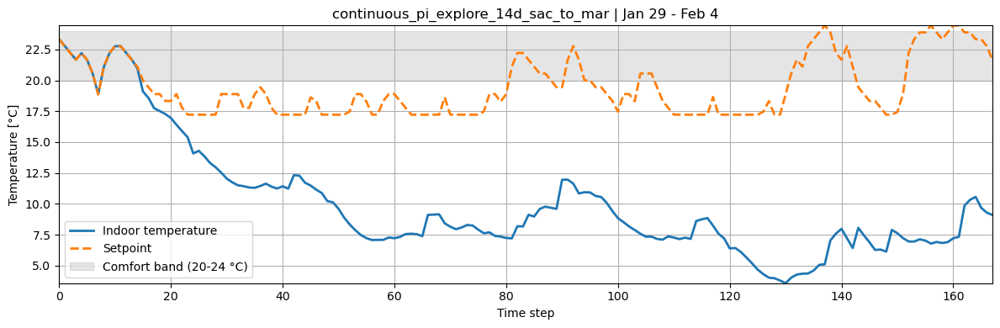

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Jan eval: -71689.78970165343
                                    cost_function      value  \
0                           all_time_peak_average   0.891184   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.247320   
5                              daily_peak_average   0.802400   
6                   discomfort_cold_delta_average   8.945292   
7                   discomfort_cold_delta_maximum  17.381857   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.979079   
10                   discomfort_hot_delta_average   0.000000   
11                   discomfort_hot_delta_maximum   0.000000   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.000000   
14    

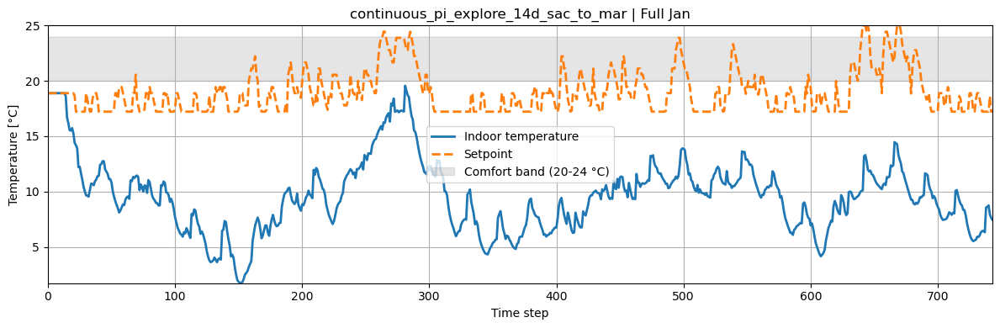

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Feb 5-11
Collected chunk reward: -7062.157602211228
Deterministic eval reward: -3384.659449780005
                                    cost_function      value  \
0                           all_time_peak_average   0.812365   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.079328   
5                              daily_peak_average   0.862494   
6                   discomfort_cold_delta_average   3.555826   
7                   discomfort_cold_delta_maximum  10.912965   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.652695   
10                   discomfort_hot_delta_average   0.010542   
11                   discomfort_hot_delta_maximum   0.491421   
12                   discomfort_hot_delta_minimum   0.00

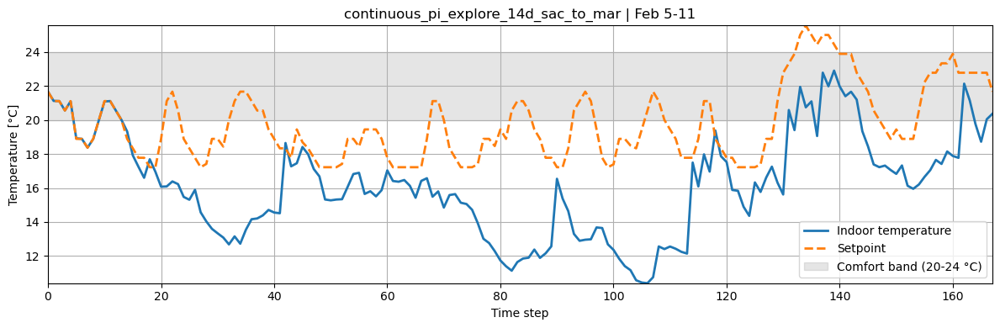

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Feb 12-18
Collected chunk reward: -1445.7920260426145
Deterministic eval reward: -1211.2708467533694
                                    cost_function     value  \
0                           all_time_peak_average  0.987497   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.222561   
5                              daily_peak_average  1.105047   
6                   discomfort_cold_delta_average  1.833092   
7                   discomfort_cold_delta_maximum  9.102203   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.393939   
10                   discomfort_hot_delta_average  0.145890   
11                   discomfort_hot_delta_maximum  2.116375   
12                   discomfort_hot_delta_minimum  0.000000   
13 

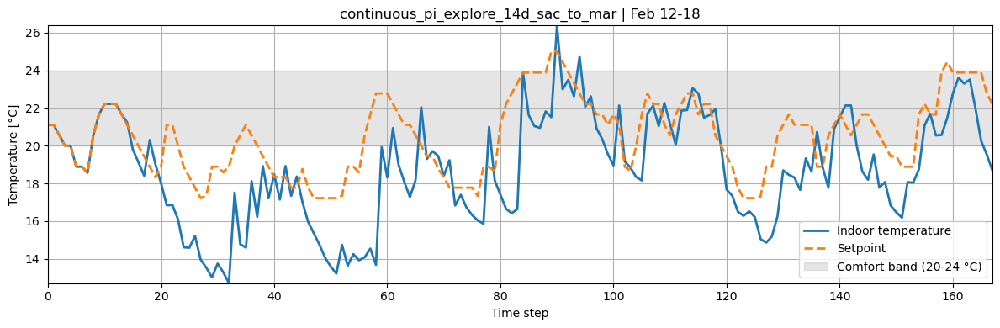

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Feb 19-25
Collected chunk reward: -677.3031764212246
Deterministic eval reward: -231.61898959503014
                                    cost_function     value  \
0                           all_time_peak_average  1.082767   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.101909   
5                              daily_peak_average  1.079138   
6                   discomfort_cold_delta_average  0.538506   
7                   discomfort_cold_delta_maximum  3.861073   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.080247   
10                   discomfort_hot_delta_average  0.291224   
11                   discomfort_hot_delta_maximum  2.736822   
12                   discomfort_hot_delta_minimum  0.000000   
13  

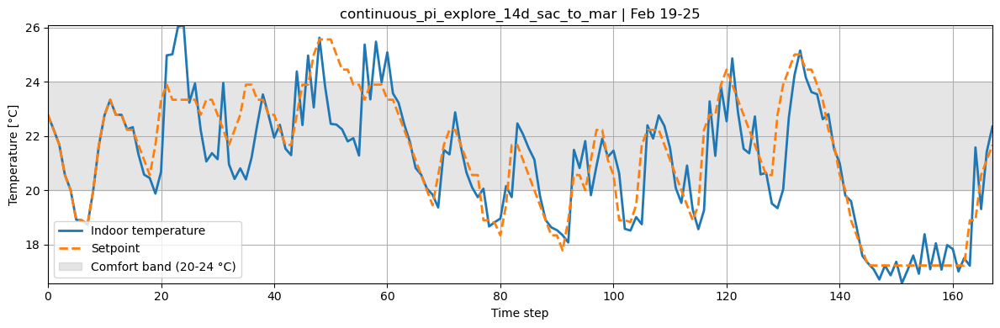

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Feb 26 - Mar 4
Collected chunk reward: -1078.6387706916576
Deterministic eval reward: -357.20087651377617
                                    cost_function     value  \
0                           all_time_peak_average  0.939845   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.102685   
5                              daily_peak_average  1.068001   
6                   discomfort_cold_delta_average  0.378626   
7                   discomfort_cold_delta_maximum  3.520281   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.081250   
10                   discomfort_hot_delta_average  0.751165   
11                   discomfort_hot_delta_maximum  3.314598   
12                   discomfort_hot_delta_minimum  0.000000  

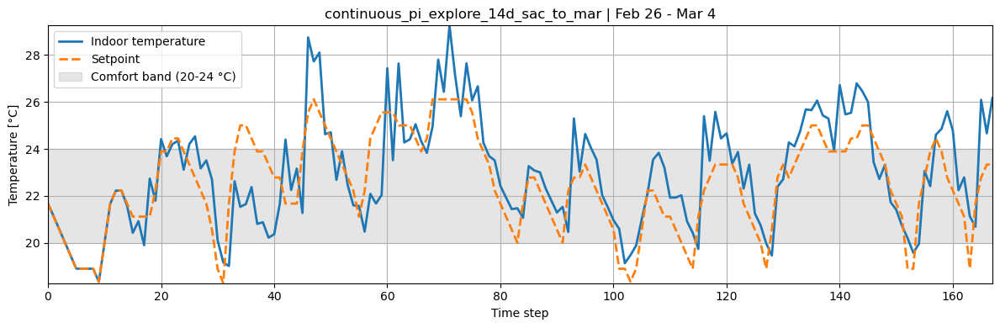

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Feb eval: -2979.166441954203
                                    cost_function     value  \
0                           all_time_peak_average  1.039454   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.125495   
5                              daily_peak_average  1.125644   
6                   discomfort_cold_delta_average  0.352409   
7                   discomfort_cold_delta_maximum  4.133965   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.065649   
10                   discomfort_hot_delta_average  1.259042   
11                   discomfort_hot_delta_maximum  8.604372   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.264122   
14                   

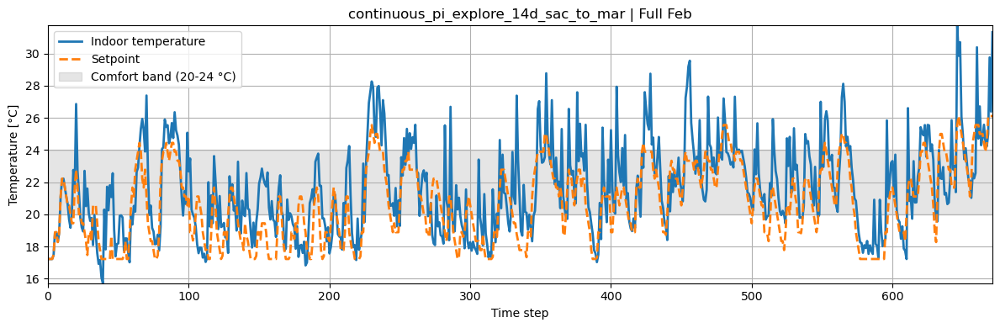

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Mar 5-11
Collected chunk reward: -1362.7063665416717
Deterministic eval reward: -532.3003454079371
                                    cost_function     value  \
0                           all_time_peak_average  1.052952   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.007869   
5                              daily_peak_average  1.055957   
6                   discomfort_cold_delta_average  0.149564   
7                   discomfort_cold_delta_maximum  2.125685   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.012500   
10                   discomfort_hot_delta_average  1.230760   
11                   discomfort_hot_delta_maximum  4.755703   
12                   discomfort_hot_delta_minimum  0.000000   
13   

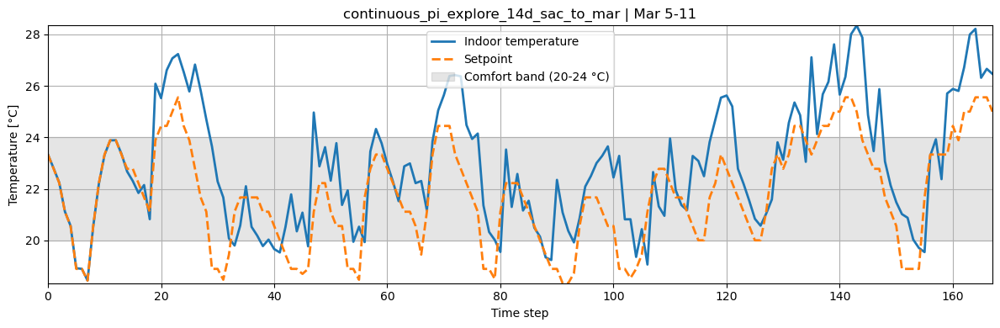

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Mar 12-18
Collected chunk reward: -2275.1460068297783
Deterministic eval reward: -1102.9927789034045
                                    cost_function     value  \
0                           all_time_peak_average  0.853867   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.944905   
5                              daily_peak_average  0.990226   
6                   discomfort_cold_delta_average  0.064892   
7                   discomfort_cold_delta_maximum  2.221640   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.006211   
10                   discomfort_hot_delta_average  1.928071   
11                   discomfort_hot_delta_maximum  7.436579   
12                   discomfort_hot_delta_minimum  0.000000   
13 

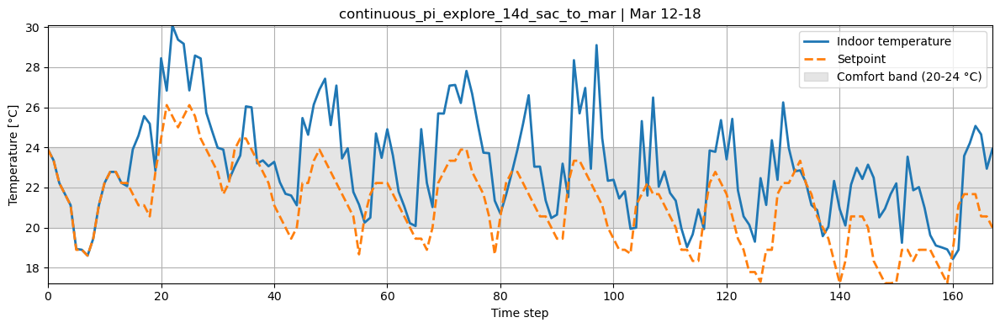

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Mar 19-25
Collected chunk reward: -2756.3625442624907
Deterministic eval reward: -1412.6966196425055
                                    cost_function     value  \
0                           all_time_peak_average  1.219748   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.007356   
5                              daily_peak_average  1.178349   
6                   discomfort_cold_delta_average  0.038859   
7                   discomfort_cold_delta_maximum  1.445520   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  2.124457   
11                   discomfort_hot_delta_maximum  6.854027   
12                   discomfort_hot_delta_minimum  0.000000   
13 

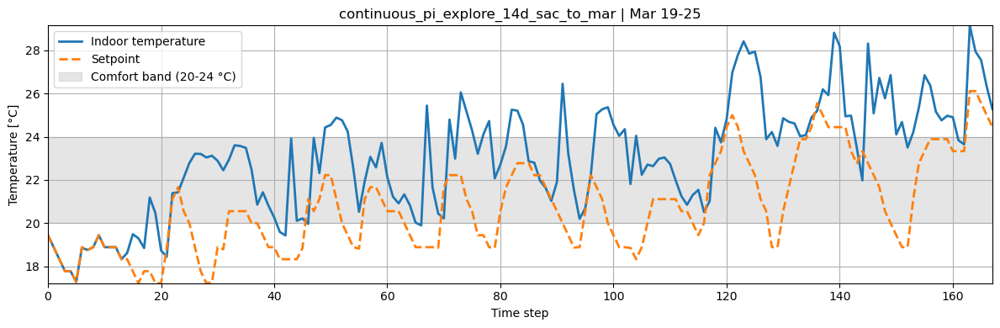

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


Chunk eval | Mar 26-31
Collected chunk reward: -2182.756993255418
Deterministic eval reward: -851.5494182410694
                                    cost_function     value  \
0                           all_time_peak_average  1.145586   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.983322   
5                              daily_peak_average  1.129479   
6                   discomfort_cold_delta_average  0.129042   
7                   discomfort_cold_delta_maximum  1.557241   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  1.741037   
11                   discomfort_hot_delta_maximum  6.306931   
12                   discomfort_hot_delta_minimum  0.000000   
13   

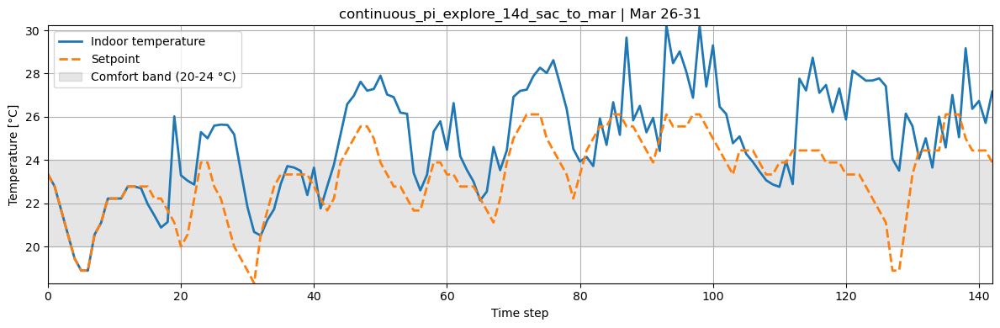

Continuous PI->SAC loop: 100%|█████████▉| 2159/2160 [00:47<00:00, 45.04it/s]


,chunk_idx,chunk_label,chunk_start,chunk_end,exploration_steps,steps_in_chunk,online_updates_in_chunk,updates_per_step,auto_ent_before_chunk,auto_ent_after_chunk,collected_reward,deterministic_eval_reward,replay_size_after_chunk
0,1,Jan 1-7,0,167,336,168,0,2,1.000000,1.000000,-727.669091,-27603.057432,168
1,2,Jan 8-14,168,335,336,168,0,2,1.000000,1.000000,-566.864772,-12770.263720,336
2,3,Jan 15-21,336,503,336,168,336,2,1.000000,1.090168,-12725.397886,-19596.518112,504
3,4,Jan 22-28,504,671,336,168,336,2,1.090168,1.178490,-6385.445969,-18752.133737,672
4,5,Jan 29 - Feb 4,672,839,336,168,336,2,1.178490,1.220403,-15122.858016,-18723.214113,840
5,6,Feb 5-11,840,1007,336,168,336,2,1.220403,1.240609,-7062.157602,-3384.659450,1008
6,7,Feb 12-18,1008,1175,336,168,336,2,1.240609,1.234558,-1445.792026,-1211.270847,1176
7,8,Feb 19-25,1176,1343,336,168,336,2,1.234558,1.236122,-677.303176,-231.618990,1344
8,9,Feb 26 - Mar 4,1344,1511,336,168,336,2,1.236122,1.269777,-1078.638771,-357.200877,1512
9,10,Mar 5-11,1512,1679,336,168,336,2,1.269777,1.318995,-1362.706367,-532.300345,1680


,month,month_start,month_end,eval_reward,replay_size_after_chunk
0,Jan,0,743,-71689.789702,840
1,Feb,744,1415,-2979.166442,1512


Saved final checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_continuous_pi_explore_14d_sac_to_mar
Saved final replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_continuous_pi_explore_14d_sac_to_mar_replay.pkl


In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm
from stable_baselines3 import SAC
import gymnasium as gym

# ============================================================
# Continuous MERLIN-style loop:
#   exploration + learning in ONE rollout
# ============================================================

MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

# ----------------------------
# Tunable knobs
# ----------------------------
CONTINUOUS_START = JAN_START
CONTINUOUS_END = MAR_END

EXPLORATION_DAYS = 14                 # PI controls first N days
EXPLORATION_STEPS = EXPLORATION_DAYS * 24

BATCH_SIZE = 256
BUFFER_SIZE = 100_000
UPDATES_PER_STEP = 2                  # MERLIN-style
LR = 3e-4
NET_ARCH = [400, 400]
ENT_COEF = "auto"
DETERMINISTIC_POLICY_DURING_LEARNING = False

EVAL_EVERY_DAYS = 7
EVAL_EVERY_STEPS = EVAL_EVERY_DAYS * 24

EXPERIMENT_LABEL = f"continuous_pi_explore_{EXPLORATION_DAYS}d_sac_to_mar"
CKPT_PATH = NOTEBOOK_DIR / f"sac_{EXPERIMENT_LABEL}"
REPLAY_PATH = NOTEBOOK_DIR / f"sac_{EXPERIMENT_LABEL}_replay.pkl"

MONTH_LABELS = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}

def step_to_month_day(step):
    for month, (start, end) in MONTH_TO_RANGE.items():
        if start <= step <= end:
            day = int((step - start) // 24 + 1)
            return MONTH_LABELS.get(month, str(month)), day
    raise ValueError(f"Step {step} is outside MONTH_TO_RANGE.")

def format_window_label(start, end):
    sm, sd = step_to_month_day(start)
    em, ed = step_to_month_day(end)
    return f"{sm} {sd}-{ed}" if sm == em else f"{sm} {sd} - {em} {ed}"

def current_auto_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

def manual_sac_updates(model, gradient_steps, batch_size=None):
    batch_size = batch_size or model.batch_size
    for _ in range(int(gradient_steps)):
        model.train(batch_size=batch_size, gradient_steps=1)

def make_continuous_env(start, end, observation_space=None, action_space=None):
    raw_env = make_env(
        reward_function=ComfortReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
    )
    wrapped_env = StableBaselines3Wrapper(raw_env)

    fixed_observation_space = observation_space or REFERENCE_OBSERVATION_SPACE
    fixed_action_space = action_space or REFERENCE_ACTION_SPACE
    if fixed_observation_space is not None or fixed_action_space is not None:
        wrapped_env = FixedSpaceWrapper(
            wrapped_env,
            fixed_observation_space or wrapped_env.observation_space,
            fixed_action_space or wrapped_env.action_space,
        )

    return raw_env, wrapped_env

def controller_action(controller, obs):
    """
    Convert SB3 flat observation -> CityLearn single-building observation list.
    """
    obs_arr = np.asarray(obs, dtype=np.float32)

    # SB3 wrapper gives a flat vector for one building.
    # CityLearn PI controller expects a list-like collection of building observations.
    if obs_arr.ndim == 1:
        obs_for_controller = [obs_arr]
    else:
        obs_for_controller = obs_arr

    if hasattr(controller, "predict"):
        action = controller.predict(obs_for_controller)
    elif hasattr(controller, "select_action"):
        action = controller.select_action(obs_for_controller)
    elif hasattr(controller, "act"):
        action = controller.act(obs_for_controller)
    else:
        raise AttributeError(
            "PITemperatureController method not found. "
            "Expected one of: predict, select_action, act"
        )

    action = np.asarray(action, dtype=np.float32)

    # If controller returns [[a]], unwrap single-building action.
    if action.ndim >= 2 and action.shape[0] == 1:
        action = action[0]

    return action

# ------------------------------------------------------------
# 1) Build one continuous environment Jan -> Mar
# ------------------------------------------------------------
full_raw_env, full_env = make_continuous_env(CONTINUOUS_START, CONTINUOUS_END)
REFERENCE_OBSERVATION_SPACE = full_env.observation_space
REFERENCE_ACTION_SPACE = full_env.action_space

print("Experiment:", EXPERIMENT_LABEL)
print("Continuous training window:", format_window_label(CONTINUOUS_START, CONTINUOUS_END), (CONTINUOUS_START, CONTINUOUS_END))
print("Exploration window:", format_window_label(CONTINUOUS_START, CONTINUOUS_START + EXPLORATION_STEPS - 1), (CONTINUOUS_START, CONTINUOUS_START + EXPLORATION_STEPS - 1))
print("Learning starts at step:", EXPLORATION_STEPS)

# PI controller attached to the SAME underlying environment
pi_controller = PITemperatureController(full_raw_env)

# ------------------------------------------------------------
# 2) Build SAC model
# ------------------------------------------------------------
policy_kwargs = dict(net_arch=NET_ARCH)

model = SAC(
    policy="MlpPolicy",
    env=full_env,
    seed=RANDOM_SEED,
    learning_rate=LR,
    batch_size=BATCH_SIZE,
    buffer_size=BUFFER_SIZE,
    learning_starts=10**9,   # disable SB3 auto-training; we train manually
    train_freq=(1, "step"),
    gradient_steps=1,
    ent_coef=ENT_COEF,
    policy_kwargs=policy_kwargs,
    verbose=1,
)

model._setup_learn(total_timesteps=1)

# ------------------------------------------------------------
# 3) One continuous simulation loop
# ------------------------------------------------------------
obs, _ = full_env.reset()
done = False
t = 0

obs_dim = model.observation_space.shape[-1]
act_dim = model.action_space.shape[-1]

weekly_results = []
monthly_results = []
logged_months = set()

chunk_reward = 0.0
chunk_start_step = CONTINUOUS_START
chunk_online_updates = 0

ent_before_chunk = current_auto_ent_coef(model)

progress_total = CONTINUOUS_END - CONTINUOUS_START + 1
pbar = tqdm(total=progress_total, desc="Continuous PI->SAC loop")

while not done:
    global_step = CONTINUOUS_START + t

    # --------------------------------------------------------
    # Exploration phase: PI controller acts
    # Learning phase: SAC policy acts
    # --------------------------------------------------------
    if t < EXPLORATION_STEPS:
        action = controller_action(pi_controller, obs)
        action = action.reshape(model.action_space.shape)
    else:
        action, _ = model.predict(obs, deterministic=DETERMINISTIC_POLICY_DURING_LEARNING)
        action = np.asarray(action, dtype=np.float32).reshape(model.action_space.shape)

    next_obs, reward, terminated, truncated, _ = full_env.step(action)
    done = terminated or truncated

    # store transition in replay
    obs_i = np.asarray(obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
    next_obs_i = np.asarray(next_obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
    action_i = np.asarray(action, dtype=np.float32).reshape(model.n_envs, act_dim)
    reward_i = np.asarray([reward], dtype=np.float32).reshape(model.n_envs)
    done_i = np.asarray([done], dtype=bool).reshape(model.n_envs)

    model.replay_buffer.add(
        obs_i,
        next_obs_i,
        action_i,
        reward_i,
        done_i,
        infos=[{} for _ in range(model.n_envs)],
    )

    # start learning only AFTER exploration phase
    if t >= EXPLORATION_STEPS:
        manual_sac_updates(model, gradient_steps=UPDATES_PER_STEP, batch_size=model.batch_size)
        chunk_online_updates += UPDATES_PER_STEP

    chunk_reward += float(reward)
    obs = next_obs
    t += 1
    pbar.update(1)

    # --------------------------------------------------------
    # Weekly logging/evaluation
    # --------------------------------------------------------
    is_eval_boundary = (t % EVAL_EVERY_STEPS == 0) or done
    if is_eval_boundary:
        chunk_end_step = global_step
        chunk_label = format_window_label(chunk_start_step, chunk_end_step)
        ent_after_chunk = current_auto_ent_coef(model)

        eval_env, eval_reward, eval_kpis = rollout_and_kpis(
            model,
            chunk_start_step,
            chunk_end_step,
        )

        print(f"\nChunk eval | {chunk_label}")
        print("Collected chunk reward:", chunk_reward)
        print("Deterministic eval reward:", eval_reward)
        print(eval_kpis)

        plot_comfort(
            eval_env,
            title=f"{EXPERIMENT_LABEL} | {chunk_label}",
        )

        weekly_results.append({
            "chunk_idx": len(weekly_results) + 1,
            "chunk_label": chunk_label,
            "chunk_start": chunk_start_step,
            "chunk_end": chunk_end_step,
            "exploration_steps": EXPLORATION_STEPS,
            "steps_in_chunk": chunk_end_step - chunk_start_step + 1,
            "online_updates_in_chunk": chunk_online_updates,
            "updates_per_step": UPDATES_PER_STEP,
            "auto_ent_before_chunk": ent_before_chunk,
            "auto_ent_after_chunk": ent_after_chunk,
            "collected_reward": float(chunk_reward),
            "deterministic_eval_reward": float(eval_reward),
            "replay_size_after_chunk": int(model.replay_buffer.size()),
        })

        # full-month evals when month end is reached
        for month, (m_start, m_end) in MONTH_TO_RANGE.items():
            if month in logged_months:
                continue
            if m_start < CONTINUOUS_START or m_end > CONTINUOUS_END:
                continue
            if global_step >= m_end:
                month_name = MONTH_LABELS[month]
                m_env, m_reward, m_kpis = rollout_and_kpis(model, m_start, m_end)
                print(f"Full {month_name} eval:", m_reward)
                print(m_kpis)
                plot_comfort(m_env, title=f"{EXPERIMENT_LABEL} | Full {month_name}")

                monthly_results.append({
                    "month": month_name,
                    "month_start": m_start,
                    "month_end": m_end,
                    "eval_reward": float(m_reward),
                    "replay_size_after_chunk": int(model.replay_buffer.size()),
                })
                logged_months.add(month)

        # reset chunk accumulators
        chunk_start_step = global_step + 1
        chunk_reward = 0.0
        chunk_online_updates = 0
        ent_before_chunk = current_auto_ent_coef(model)

pbar.close()

# ------------------------------------------------------------
# 4) Save and show results
# ------------------------------------------------------------
weekly_df = pd.DataFrame(weekly_results)
monthly_df = pd.DataFrame(monthly_results)

display(weekly_df)
display(monthly_df)

model.save(str(CKPT_PATH))
model.save_replay_buffer(str(REPLAY_PATH))
print(f"Saved final checkpoint: {CKPT_PATH}")
print(f"Saved final replay: {REPLAY_PATH}")

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Experiment: continuous_pi_explore_14d_sac_to_mar
Continuous window: Jan 1 - Mar 31 (0, 2159)
Exploration window: Jan 1-14 (0, 335)
Learning starts after step: 336
Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


Continuous PI->SAC rollout:   8%|▊         | 168/2160 [00:00<00:03, 528.84it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Jan 1-7
Collected rollout reward: -727.6690912209851
Deterministic eval reward: -27603.057431672634
                                    cost_function         value  \
0                           all_time_peak_average  7.991990e-01   
1         annual_normalized_unserved_energy_total  1.244173e-09   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.477261e+00   
5                              daily_peak_average  7.520977e-01   
6                   discomfort_cold_delta_average  1.054363e+01   
7                   discomfort_cold_delta_maximum  2.146219e+01   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  9.068323e-01   
10                   discomfort_hot_delta_average  0.000000e+00   
11                   discomfort_hot_delta_maximum  0.000000e+00   
12                   

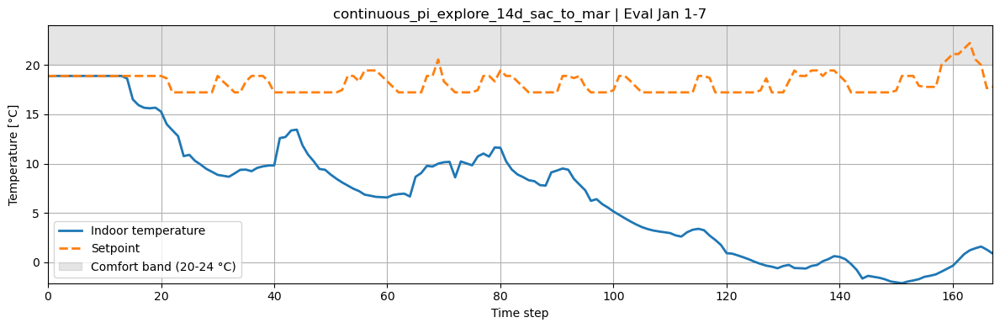

Continuous PI->SAC rollout:  15%|█▍        | 323/2160 [00:01<00:11, 158.08it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Jan 8-14
Collected rollout reward: -566.8647720309464
Deterministic eval reward: -12770.263719530576
                                    cost_function      value  \
0                           all_time_peak_average   0.928285   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.282199   
5                              daily_peak_average   0.726659   
6                   discomfort_cold_delta_average   7.466532   
7                   discomfort_cold_delta_maximum  15.416326   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.871166   
10                   discomfort_hot_delta_average   0.000260   
11                   discomfort_hot_delta_maximum   0.014133   
12                   discomfort_hot_delta_minimum   0.00000

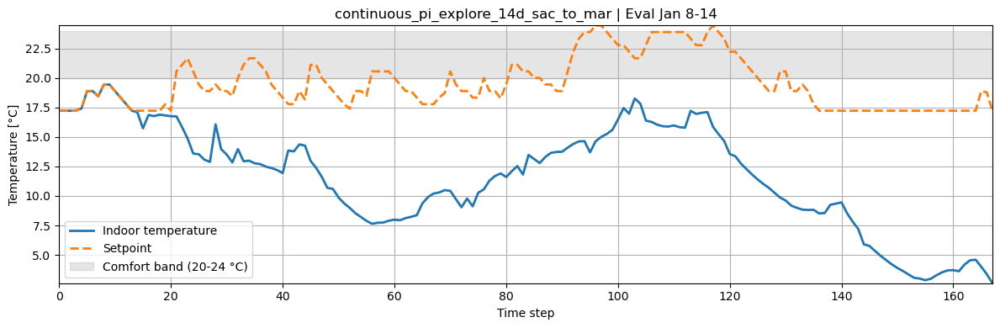

Continuous PI->SAC rollout:  23%|██▎       | 503/2160 [00:05<00:21, 77.92it/s] /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Jan 15-21
Collected rollout reward: -12725.397885856737
Deterministic eval reward: -19596.51811182409
                                    cost_function      value  \
0                           all_time_peak_average   0.957119   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.244782   
5                              daily_peak_average   0.767755   
6                   discomfort_cold_delta_average   9.580113   
7                   discomfort_cold_delta_maximum  16.888927   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.901840   
10                   discomfort_hot_delta_average   0.000443   
11                   discomfort_hot_delta_maximum   0.045933   
12                   discomfort_hot_delta_minimum   0.0000

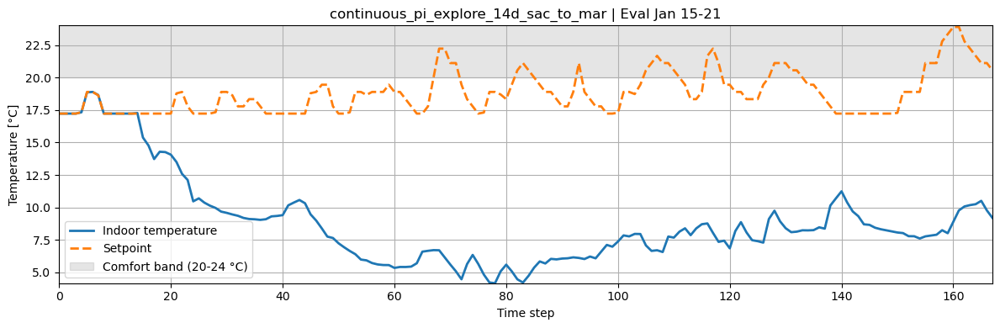

Continuous PI->SAC rollout:  31%|███       | 671/2160 [00:09<00:18, 81.35it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relate


Chunk: Jan 22-28
Collected rollout reward: -6385.44596896153
Deterministic eval reward: -18752.13373669479
                                    cost_function      value  \
0                           all_time_peak_average   0.869265   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.303113   
5                              daily_peak_average   0.820866   
6                   discomfort_cold_delta_average   8.874615   
7                   discomfort_cold_delta_maximum  17.032749   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.892405   
10                   discomfort_hot_delta_average   0.001733   
11                   discomfort_hot_delta_maximum   0.262094   
12                   discomfort_hot_delta_minimum   0.000000

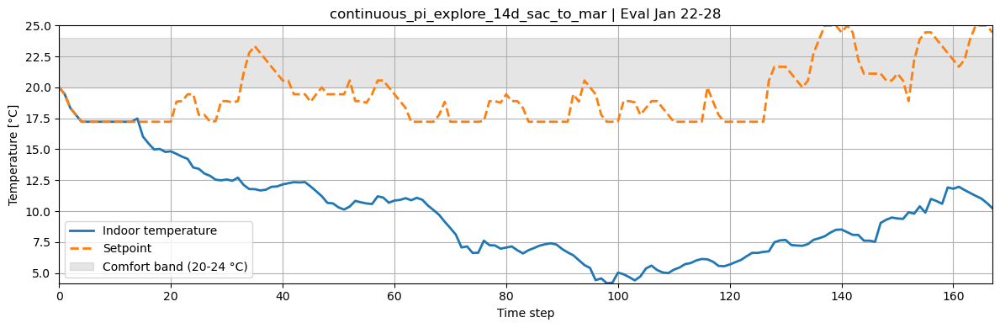

Continuous PI->SAC rollout:  39%|███▊      | 835/2160 [00:12<00:18, 72.09it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relate


Chunk: Jan 29 - Feb 4
Collected rollout reward: -15122.858016182417
Deterministic eval reward: -18723.21411272058
                                    cost_function      value  \
0                           all_time_peak_average   1.000000   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.292363   
5                              daily_peak_average   0.859897   
6                   discomfort_cold_delta_average   8.653633   
7                   discomfort_cold_delta_maximum  19.341080   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.857143   
10                   discomfort_hot_delta_average   0.000706   
11                   discomfort_hot_delta_maximum   0.027727   
12                   discomfort_hot_delta_minimum   0

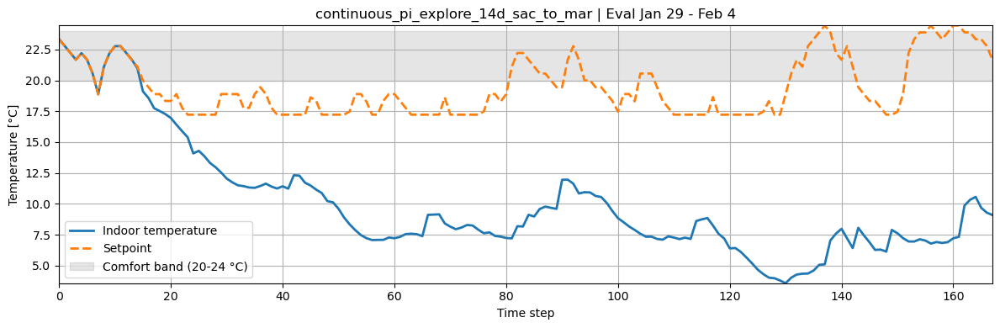

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Jan eval: -71689.78970165343
                                    cost_function      value  \
0                           all_time_peak_average   0.891184   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.247320   
5                              daily_peak_average   0.802400   
6                   discomfort_cold_delta_average   8.945292   
7                   discomfort_cold_delta_maximum  17.381857   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.979079   
10                   discomfort_hot_delta_average   0.000000   
11                   discomfort_hot_delta_maximum   0.000000   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.000000   
14    

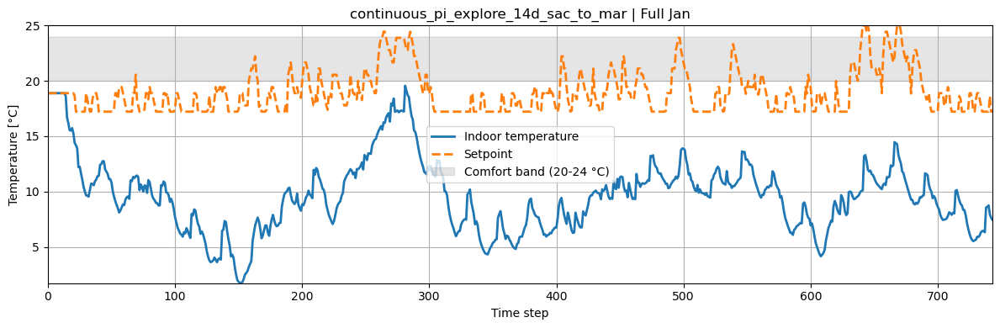

Continuous PI->SAC rollout:  47%|████▋     | 1008/2160 [00:19<00:15, 72.96it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Feb 5-11
Collected rollout reward: -7062.157602211228
Deterministic eval reward: -3384.659449780005
                                    cost_function      value  \
0                           all_time_peak_average   0.812365   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.079328   
5                              daily_peak_average   0.862494   
6                   discomfort_cold_delta_average   3.555826   
7                   discomfort_cold_delta_maximum  10.912965   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.652695   
10                   discomfort_hot_delta_average   0.010542   
11                   discomfort_hot_delta_maximum   0.491421   
12                   discomfort_hot_delta_minimum   0.000000

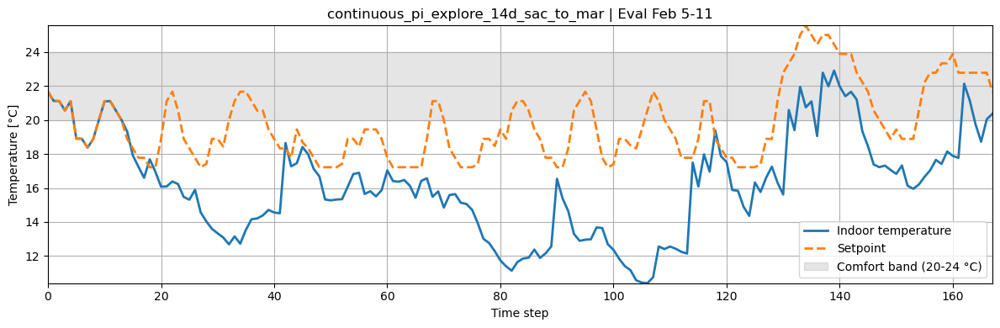

Continuous PI->SAC rollout:  54%|█████▍    | 1169/2160 [00:22<00:11, 84.86it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Feb 12-18
Collected rollout reward: -1445.7920260426145
Deterministic eval reward: -1211.2708467533694
                                    cost_function     value  \
0                           all_time_peak_average  0.987497   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.222561   
5                              daily_peak_average  1.105047   
6                   discomfort_cold_delta_average  1.833092   
7                   discomfort_cold_delta_maximum  9.102203   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.393939   
10                   discomfort_hot_delta_average  0.145890   
11                   discomfort_hot_delta_maximum  2.116375   
12                   discomfort_hot_delta_minimum  0.000000   
13     

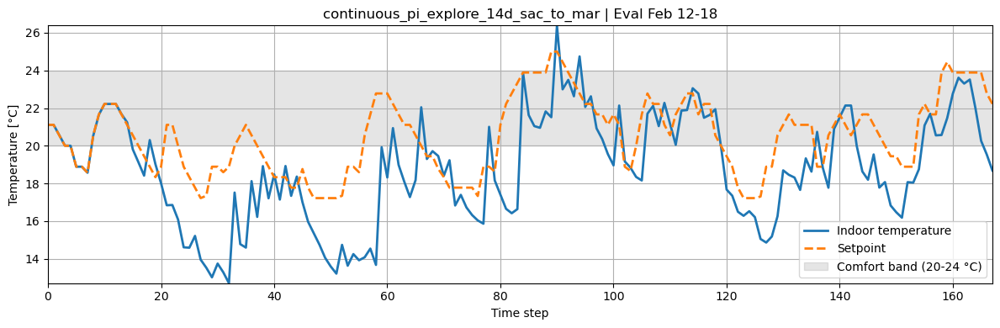

Continuous PI->SAC rollout:  62%|██████▏   | 1339/2160 [00:26<00:11, 72.92it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Feb 19-25
Collected rollout reward: -677.3031764212246
Deterministic eval reward: -231.61898959503014
                                    cost_function     value  \
0                           all_time_peak_average  1.082767   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.101909   
5                              daily_peak_average  1.079138   
6                   discomfort_cold_delta_average  0.538506   
7                   discomfort_cold_delta_maximum  3.861073   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.080247   
10                   discomfort_hot_delta_average  0.291224   
11                   discomfort_hot_delta_maximum  2.736822   
12                   discomfort_hot_delta_minimum  0.000000   
13      

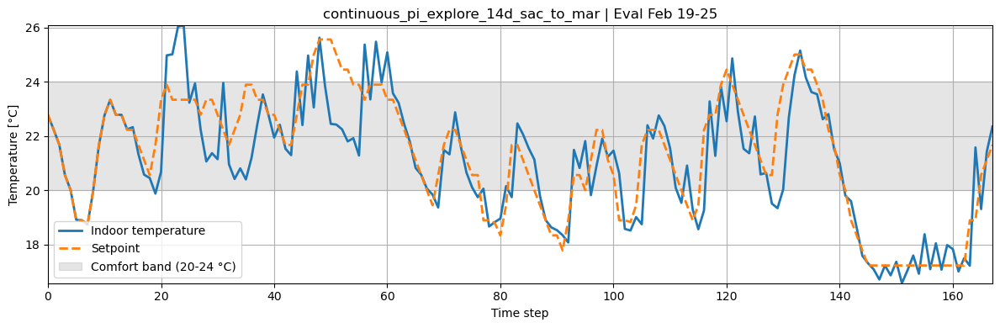

Continuous PI->SAC rollout:  70%|██████▉   | 1506/2160 [00:30<00:10, 63.50it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Feb 26 - Mar 4
Collected rollout reward: -1078.6387706916576
Deterministic eval reward: -357.20087651377617
                                    cost_function     value  \
0                           all_time_peak_average  0.939845   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.102685   
5                              daily_peak_average  1.068001   
6                   discomfort_cold_delta_average  0.378626   
7                   discomfort_cold_delta_maximum  3.520281   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.081250   
10                   discomfort_hot_delta_average  0.751165   
11                   discomfort_hot_delta_maximum  3.314598   
12                   discomfort_hot_delta_minimum  0.000000   
13

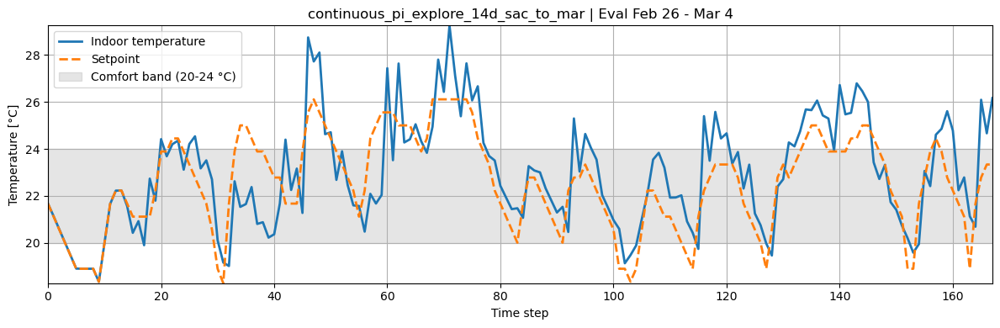

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Feb eval: -2979.166441954203
                                    cost_function     value  \
0                           all_time_peak_average  1.039454   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.125495   
5                              daily_peak_average  1.125644   
6                   discomfort_cold_delta_average  0.352409   
7                   discomfort_cold_delta_maximum  4.133965   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.065649   
10                   discomfort_hot_delta_average  1.259042   
11                   discomfort_hot_delta_maximum  8.604372   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.264122   
14                   

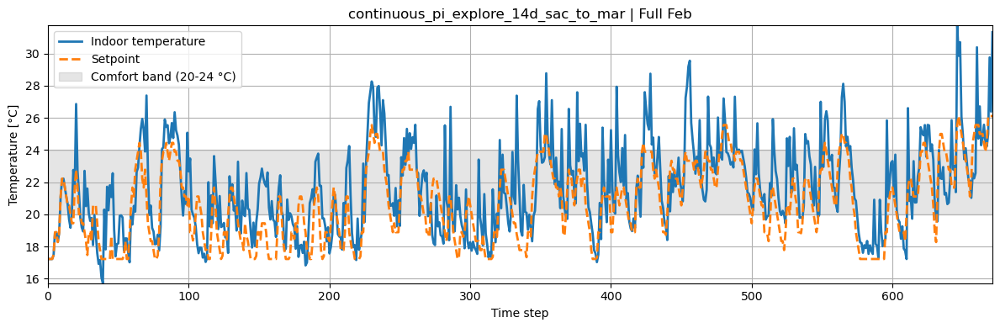

Continuous PI->SAC rollout:  78%|███████▊  | 1680/2160 [00:36<00:06, 72.04it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Mar 5-11
Collected rollout reward: -1362.7063665416717
Deterministic eval reward: -532.3003454079371
                                    cost_function     value  \
0                           all_time_peak_average  1.052952   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.007869   
5                              daily_peak_average  1.055957   
6                   discomfort_cold_delta_average  0.149564   
7                   discomfort_cold_delta_maximum  2.125685   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.012500   
10                   discomfort_hot_delta_average  1.230760   
11                   discomfort_hot_delta_maximum  4.755703   
12                   discomfort_hot_delta_minimum  0.000000   
13       

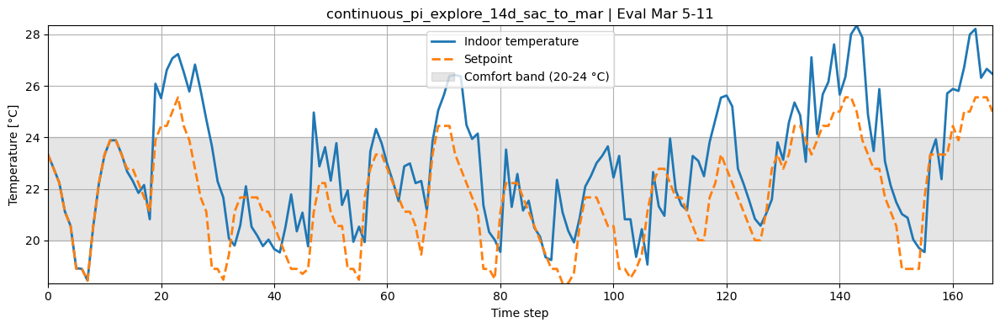

Continuous PI->SAC rollout:  85%|████████▌ | 1840/2160 [00:39<00:03, 85.48it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Mar 12-18
Collected rollout reward: -2275.1460068297783
Deterministic eval reward: -1102.9927789034045
                                    cost_function     value  \
0                           all_time_peak_average  0.853867   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.944905   
5                              daily_peak_average  0.990226   
6                   discomfort_cold_delta_average  0.064892   
7                   discomfort_cold_delta_maximum  2.221640   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.006211   
10                   discomfort_hot_delta_average  1.928071   
11                   discomfort_hot_delta_maximum  7.436579   
12                   discomfort_hot_delta_minimum  0.000000   
13     

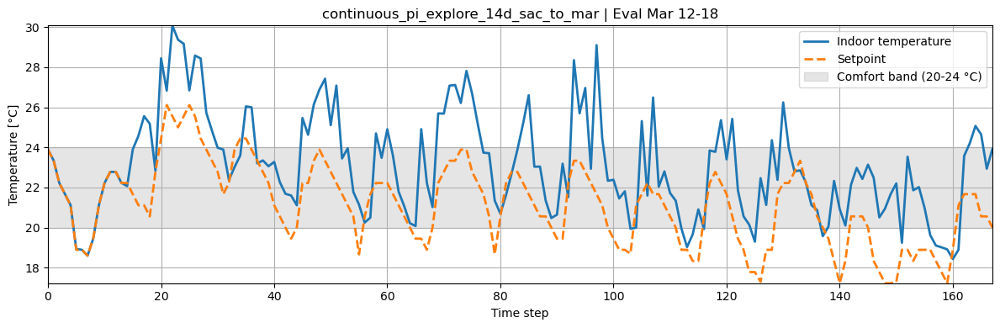

Continuous PI->SAC rollout:  93%|█████████▎| 2010/2160 [00:43<00:01, 82.15it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Mar 19-25
Collected rollout reward: -2756.3625442624907
Deterministic eval reward: -1412.6966196425055
                                    cost_function     value  \
0                           all_time_peak_average  1.219748   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.007356   
5                              daily_peak_average  1.178349   
6                   discomfort_cold_delta_average  0.038859   
7                   discomfort_cold_delta_maximum  1.445520   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  2.124457   
11                   discomfort_hot_delta_maximum  6.854027   
12                   discomfort_hot_delta_minimum  0.000000   
13     

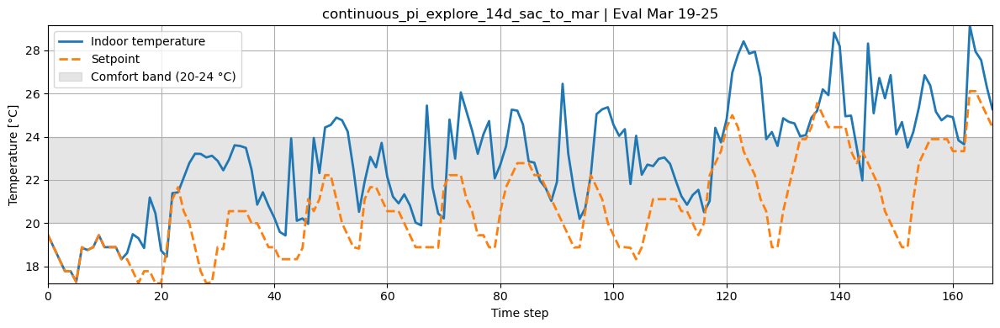

Continuous PI->SAC rollout: 100%|█████████▉| 2157/2160 [00:46<00:00, 77.92it/s]/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues relat


Chunk: Mar 26-31
Collected rollout reward: -2182.756993255418
Deterministic eval reward: -851.5494182410694
                                    cost_function     value  \
0                           all_time_peak_average  1.145586   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.983322   
5                              daily_peak_average  1.129479   
6                   discomfort_cold_delta_average  0.129042   
7                   discomfort_cold_delta_maximum  1.557241   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.000000   
10                   discomfort_hot_delta_average  1.741037   
11                   discomfort_hot_delta_maximum  6.306931   
12                   discomfort_hot_delta_minimum  0.000000   
13       

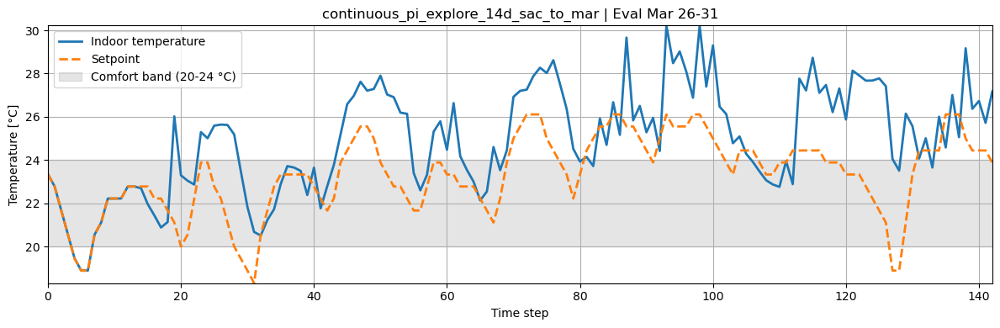

Continuous PI->SAC rollout: 100%|█████████▉| 2159/2160 [00:48<00:00, 44.83it/s]


Phase counts:
phase
SAC    1823
PI      336
Name: count, dtype: int64


,global_step,phase,reward,done,obs_0,obs_1,obs_2,obs_3,obs_4,obs_5,...,next_obs_18,next_obs_19,next_obs_20,next_obs_21,next_obs_22,next_obs_23,next_obs_24,next_obs_25,next_obs_26,next_obs_27
0,0,PI,-0.000856,False,1.0,1.0,-21.333334,0.0,-24.826778,-15.724686,...,2.0,-0.000856,-0.000856,3.0,0.0,4.742636,0.0,4.324236,0.0,0.0
1,1,PI,-0.000021,False,1.0,2.0,-21.225000,0.0,-24.973806,-16.243246,...,2.0,-0.000021,-0.000021,3.0,0.0,4.505665,0.0,4.119984,0.0,0.0
2,2,PI,0.000000,False,1.0,3.0,-21.700001,0.0,-23.852222,-16.396481,...,2.0,0.000000,0.000000,3.0,0.0,4.561524,0.0,4.178558,0.0,0.0
3,3,PI,0.000000,False,1.0,4.0,-22.799999,0.0,-20.824516,-16.053118,...,2.0,0.000000,0.000000,3.0,0.0,4.499859,0.0,4.119608,0.0,0.0
4,4,PI,0.000000,False,1.0,5.0,-22.450001,0.0,-19.571859,-17.764027,...,2.0,0.000000,0.000000,3.0,0.0,4.710834,0.0,4.330583,0.0,0.0


,chunk_idx,chunk_label,chunk_start,chunk_end,steps_in_chunk,exploration_steps_total,online_updates_in_chunk,updates_per_step,auto_ent_before_chunk,auto_ent_after_chunk,collected_reward,deterministic_eval_reward,replay_size_after_chunk
0,1,Jan 1-7,0,167,168,336,0,2,1.000000,1.000000,-727.669091,-27603.057432,168
1,2,Jan 8-14,168,335,168,336,0,2,1.000000,1.000000,-566.864772,-12770.263720,336
2,3,Jan 15-21,336,503,168,336,336,2,1.000000,1.090168,-12725.397886,-19596.518112,504
3,4,Jan 22-28,504,671,168,336,336,2,1.090168,1.178490,-6385.445969,-18752.133737,672
4,5,Jan 29 - Feb 4,672,839,168,336,336,2,1.178490,1.220403,-15122.858016,-18723.214113,840
5,6,Feb 5-11,840,1007,168,336,336,2,1.220403,1.240609,-7062.157602,-3384.659450,1008
6,7,Feb 12-18,1008,1175,168,336,336,2,1.240609,1.234558,-1445.792026,-1211.270847,1176
7,8,Feb 19-25,1176,1343,168,336,336,2,1.234558,1.236122,-677.303176,-231.618990,1344
8,9,Feb 26 - Mar 4,1344,1511,168,336,336,2,1.236122,1.269777,-1078.638771,-357.200877,1512
9,10,Mar 5-11,1512,1679,168,336,336,2,1.269777,1.318995,-1362.706367,-532.300345,1680


,month,month_start,month_end,eval_reward,replay_size_after_chunk
0,Jan,0,743,-71689.789702,840
1,Feb,744,1415,-2979.166442,1512


Saved final checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_continuous_pi_explore_14d_sac_to_mar
Saved final replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_continuous_pi_explore_14d_sac_to_mar_replay.pkl


In [27]:
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm
from stable_baselines3 import SAC
import gymnasium as gym

# ============================================================
# EXACT LOOP STRUCTURE:
# one continuous Jan->Mar simulation
# - PI controller acts during exploration phase
# - transitions are added to replay immediately
# - after exploration ends, SAC acts and learns online
# - no separate offline batch-training block
# ============================================================

# ----------------------------
# Settings
# ----------------------------
MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

CONTINUOUS_START = JAN_START
CONTINUOUS_END = MAR_END

EXPLORATION_DAYS = 14
EXPLORATION_STEPS = EXPLORATION_DAYS * 24

BATCH_SIZE = 256
BUFFER_SIZE = 100_000
UPDATES_PER_STEP = 2
LR = 3e-4
NET_ARCH = [400, 400]
ENT_COEF = "auto"

DETERMINISTIC_POLICY_DURING_LEARNING = False
EVAL_EVERY_DAYS = 7
EVAL_EVERY_STEPS = EVAL_EVERY_DAYS * 24

EXPERIMENT_LABEL = f"continuous_pi_explore_{EXPLORATION_DAYS}d_sac_to_mar"
CKPT_PATH = NOTEBOOK_DIR / f"sac_{EXPERIMENT_LABEL}"
REPLAY_PATH = NOTEBOOK_DIR / f"sac_{EXPERIMENT_LABEL}_replay.pkl"

MONTH_LABELS = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}

# ----------------------------
# Helpers
# ----------------------------
def step_to_month_day(step):
    for month, (start, end) in MONTH_TO_RANGE.items():
        if start <= step <= end:
            day = int((step - start) // 24 + 1)
            return MONTH_LABELS.get(month, str(month)), day
    raise ValueError(f"Step {step} is outside MONTH_TO_RANGE.")

def format_window_label(start, end):
    sm, sd = step_to_month_day(start)
    em, ed = step_to_month_day(end)
    return f"{sm} {sd}-{ed}" if sm == em else f"{sm} {sd} - {em} {ed}"

def current_auto_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

def manual_sac_updates(model, gradient_steps, batch_size=None):
    batch_size = batch_size or model.batch_size
    for _ in range(int(gradient_steps)):
        model.train(batch_size=batch_size, gradient_steps=1)

def make_continuous_env(start, end, observation_space=None, action_space=None):
    raw_env = make_env(
        reward_function=ComfortReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
    )
    wrapped_env = StableBaselines3Wrapper(raw_env)

    fixed_observation_space = observation_space or REFERENCE_OBSERVATION_SPACE
    fixed_action_space = action_space or REFERENCE_ACTION_SPACE
    if fixed_observation_space is not None or fixed_action_space is not None:
        wrapped_env = FixedSpaceWrapper(
            wrapped_env,
            fixed_observation_space or wrapped_env.observation_space,
            fixed_action_space or wrapped_env.action_space,
        )

    return raw_env, wrapped_env

def controller_action(controller, obs):
    """
    SB3 wrapper gives a flat 1D observation for one building.
    CityLearn PI controller expects a list of building observations.
    """
    obs_arr = np.asarray(obs, dtype=np.float32)
    obs_for_controller = [obs_arr] if obs_arr.ndim == 1 else obs_arr

    if hasattr(controller, "predict"):
        action = controller.predict(obs_for_controller)
    elif hasattr(controller, "select_action"):
        action = controller.select_action(obs_for_controller)
    elif hasattr(controller, "act"):
        action = controller.act(obs_for_controller)
    else:
        raise AttributeError(
            "PITemperatureController method not found. "
            "Expected one of: predict, select_action, act"
        )

    action = np.asarray(action, dtype=np.float32)

    # unwrap single-building action if returned as [[...]]
    if action.ndim >= 2 and action.shape[0] == 1:
        action = action[0]

    return action

# ----------------------------
# Build one continuous env
# ----------------------------
full_raw_env, full_env = make_continuous_env(CONTINUOUS_START, CONTINUOUS_END)
REFERENCE_OBSERVATION_SPACE = full_env.observation_space
REFERENCE_ACTION_SPACE = full_env.action_space

print("Experiment:", EXPERIMENT_LABEL)
print("Continuous window:", format_window_label(CONTINUOUS_START, CONTINUOUS_END), (CONTINUOUS_START, CONTINUOUS_END))
print("Exploration window:", format_window_label(CONTINUOUS_START, CONTINUOUS_START + EXPLORATION_STEPS - 1), (CONTINUOUS_START, CONTINUOUS_START + EXPLORATION_STEPS - 1))
print("Learning starts after step:", EXPLORATION_STEPS)

# PI controller attached to same underlying raw env
pi_controller = PITemperatureController(full_raw_env)

# ----------------------------
# Build SAC model
# ----------------------------
policy_kwargs = dict(net_arch=NET_ARCH)

model = SAC(
    policy="MlpPolicy",
    env=full_env,
    seed=RANDOM_SEED,
    learning_rate=LR,
    batch_size=BATCH_SIZE,
    buffer_size=BUFFER_SIZE,
    learning_starts=10**9,   # disable SB3 automatic learn() training
    train_freq=(1, "step"),
    gradient_steps=1,
    ent_coef=ENT_COEF,
    policy_kwargs=policy_kwargs,
    verbose=1,
)

model._setup_learn(total_timesteps=1)

# ----------------------------
# One continuous loop
# ----------------------------
obs, _ = full_env.reset()
done = False
t = 0

obs_dim = model.observation_space.shape[-1]
act_dim = model.action_space.shape[-1]

trajectory_rows = []
weekly_results = []
monthly_results = []
logged_months = set()

chunk_reward = 0.0
chunk_online_updates = 0
chunk_start_step = CONTINUOUS_START
ent_before_chunk = current_auto_ent_coef(model)

total_steps = CONTINUOUS_END - CONTINUOUS_START + 1
pbar = tqdm(total=total_steps, desc="Continuous PI->SAC rollout")

while not done:
    global_step = CONTINUOUS_START + t

    # --------------------------------------------------------
    # PI exploration phase
    # --------------------------------------------------------
    if t < EXPLORATION_STEPS:
        phase = "PI"
        action = controller_action(pi_controller, obs)
        action = np.asarray(action, dtype=np.float32).reshape(model.action_space.shape)

    # --------------------------------------------------------
    # SAC learning phase
    # --------------------------------------------------------
    else:
        phase = "SAC"
        action, _ = model.predict(obs, deterministic=DETERMINISTIC_POLICY_DURING_LEARNING)
        action = np.asarray(action, dtype=np.float32).reshape(model.action_space.shape)

    next_obs, reward, terminated, truncated, info = full_env.step(action)
    done = terminated or truncated

    # add transition to replay
    obs_i = np.asarray(obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
    next_obs_i = np.asarray(next_obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
    action_i = np.asarray(action, dtype=np.float32).reshape(model.n_envs, act_dim)
    reward_i = np.asarray([reward], dtype=np.float32).reshape(model.n_envs)
    done_i = np.asarray([done], dtype=bool).reshape(model.n_envs)

    model.replay_buffer.add(
        obs_i,
        next_obs_i,
        action_i,
        reward_i,
        done_i,
        infos=[{} for _ in range(model.n_envs)],
    )

    # start learning only after exploration phase is over
    if t >= EXPLORATION_STEPS:
        manual_sac_updates(model, gradient_steps=UPDATES_PER_STEP, batch_size=model.batch_size)
        chunk_online_updates += UPDATES_PER_STEP

    # log ACTUAL training trajectory
    row = {
        "global_step": global_step,
        "phase": phase,
        "reward": float(reward),
        "done": bool(done),
    }

    flat_obs = np.asarray(obs).reshape(-1)
    flat_action = np.asarray(action).reshape(-1)
    flat_next_obs = np.asarray(next_obs).reshape(-1)

    for i, val in enumerate(flat_obs):
        row[f"obs_{i}"] = float(val)
    for i, val in enumerate(flat_action):
        row[f"action_{i}"] = float(val)
    for i, val in enumerate(flat_next_obs):
        row[f"next_obs_{i}"] = float(val)

    trajectory_rows.append(row)

    chunk_reward += float(reward)
    obs = next_obs
    t += 1
    pbar.update(1)

    # --------------------------------------------------------
    # Weekly boundary logging
    # --------------------------------------------------------
    is_eval_boundary = (t % EVAL_EVERY_STEPS == 0) or done
    if is_eval_boundary:
        chunk_end_step = global_step
        chunk_label = format_window_label(chunk_start_step, chunk_end_step)
        ent_after_chunk = current_auto_ent_coef(model)

        # deterministic evaluation on same date slice
        eval_env, eval_reward, eval_kpis = rollout_and_kpis(
            model,
            chunk_start_step,
            chunk_end_step,
        )

        print(f"\nChunk: {chunk_label}")
        print("Collected rollout reward:", chunk_reward)
        print("Deterministic eval reward:", eval_reward)
        print(eval_kpis)

        weekly_results.append({
            "chunk_idx": len(weekly_results) + 1,
            "chunk_label": chunk_label,
            "chunk_start": chunk_start_step,
            "chunk_end": chunk_end_step,
            "steps_in_chunk": chunk_end_step - chunk_start_step + 1,
            "exploration_steps_total": EXPLORATION_STEPS,
            "online_updates_in_chunk": chunk_online_updates,
            "updates_per_step": UPDATES_PER_STEP,
            "auto_ent_before_chunk": ent_before_chunk,
            "auto_ent_after_chunk": ent_after_chunk,
            "collected_reward": float(chunk_reward),
            "deterministic_eval_reward": float(eval_reward),
            "replay_size_after_chunk": int(model.replay_buffer.size()),
        })

        # optional eval plots
        plot_comfort(
            eval_env,
            title=f"{EXPERIMENT_LABEL} | Eval {chunk_label}",
        )

        # full-month evals once month end has been reached
        for month, (m_start, m_end) in MONTH_TO_RANGE.items():
            if month in logged_months:
                continue
            if m_start < CONTINUOUS_START or m_end > CONTINUOUS_END:
                continue
            if global_step >= m_end:
                month_name = MONTH_LABELS[month]
                m_env, m_reward, m_kpis = rollout_and_kpis(model, m_start, m_end)
                print(f"Full {month_name} eval:", m_reward)
                print(m_kpis)

                monthly_results.append({
                    "month": month_name,
                    "month_start": m_start,
                    "month_end": m_end,
                    "eval_reward": float(m_reward),
                    "replay_size_after_chunk": int(model.replay_buffer.size()),
                })

                plot_comfort(
                    m_env,
                    title=f"{EXPERIMENT_LABEL} | Full {month_name}",
                )

                logged_months.add(month)

        # reset chunk accumulators
        chunk_start_step = global_step + 1
        chunk_reward = 0.0
        chunk_online_updates = 0
        ent_before_chunk = current_auto_ent_coef(model)

pbar.close()

# ----------------------------
# Results
# ----------------------------
trajectory_df = pd.DataFrame(trajectory_rows)
weekly_df = pd.DataFrame(weekly_results)
monthly_df = pd.DataFrame(monthly_results)

print("\nPhase counts:")
print(trajectory_df["phase"].value_counts())

display(trajectory_df.head())
display(weekly_df)
display(monthly_df)

model.save(str(CKPT_PATH))
model.save_replay_buffer(str(REPLAY_PATH))
print(f"Saved final checkpoint: {CKPT_PATH}")
print(f"Saved final replay: {REPLAY_PATH}")

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/pi_seed_14d_offupd_500_onupd_2_to_m3_dataset.npz
Experiment: pi_seed_14d_offupd_500_onupd_2_to_m3
Offline seed window: Jan 1-14 (0, 335)
Online train window: Jan 15 - Mar 31 (336, 2159)
Dataset mode: rebuilt
Dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/pi_seed_14d_offupd_500_onupd_2_to_m3_dataset.npz


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Prefilled replay from dataset: 335 transitions
Saved prefill checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_pi_seed_14d_offupd_500_onupd_2_to_m3_prefill
Saved prefill replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_pi_seed_14d_offupd_500_onupd_2_to_m3_prefill_replay.pkl


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Prefill-only reward: -51493.976236497125
                                    cost_function         value  \
0                           all_time_peak_average  7.693714e-01   
1         annual_normalized_unserved_energy_total  6.120958e-10   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.406044e+00   
5                              daily_peak_average  7.237900e-01   
6                   discomfort_cold_delta_average  1.070996e+01   
7                   discomfort_cold_delta_maximum  2.146220e+01   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  9.475309e-01   
10                   discomfort_hot_delta_average  0.000000e+00   
11                   discomfort_hot_delta_maximum  0.000000e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13                   

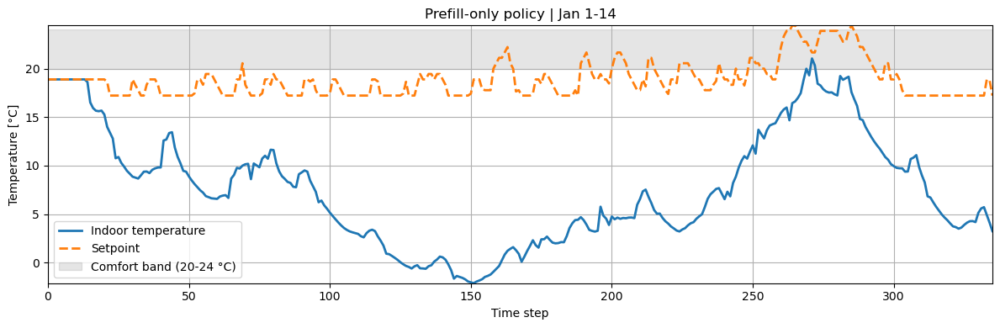

Running offline SAC updates: 500 | lr=0.0003


Offline SAC updates: 100%|██████████| 500/500 [00:02<00:00, 175.20it/s]


Saved offline-updated checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_pi_seed_14d_offupd_500_onupd_2_to_m3_offline


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Offline-updated reward: -8229.250804325195
                                    cost_function      value  \
0                           all_time_peak_average   1.159339   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   0.895526   
5                              daily_peak_average   1.288755   
6                   discomfort_cold_delta_average   0.154460   
7                   discomfort_cold_delta_maximum   4.149404   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.033951   
10                   discomfort_hot_delta_average   3.697630   
11                   discomfort_hot_delta_maximum  11.788748   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.675926 

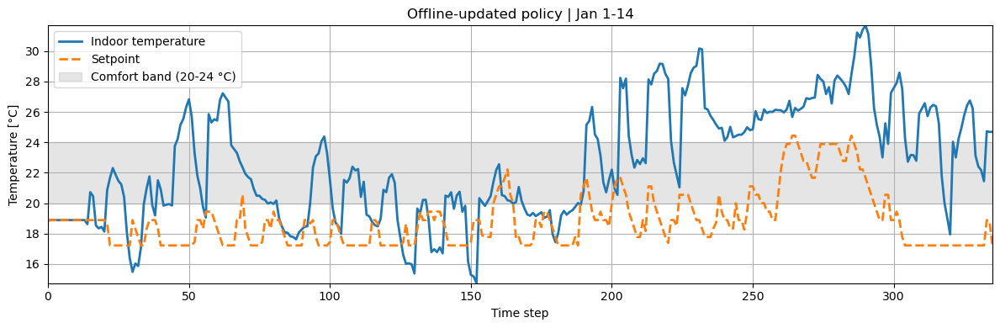

Online learning rate set to: 0.0003


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 15-21 | reward: -3301.513333341164
                                    cost_function      value  \
0                           all_time_peak_average   1.174910   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.073591   
5                              daily_peak_average   1.113611   
6                   discomfort_cold_delta_average   0.442478   
7                   discomfort_cold_delta_maximum   5.155705   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.092025   
10                   discomfort_hot_delta_average   2.657885   
11                   discomfort_hot_delta_maximum  15.026417   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion  

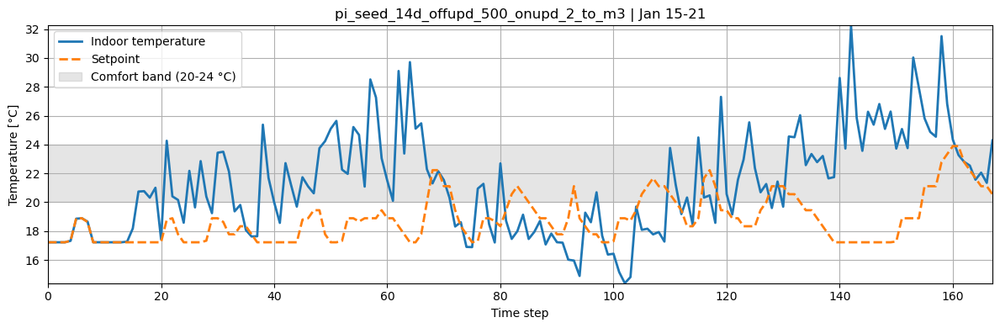

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 22-28 | reward: -5644.987615569307
                                    cost_function      value  \
0                           all_time_peak_average   0.843440   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.196254   
5                              daily_peak_average   0.879651   
6                   discomfort_cold_delta_average   3.739322   
7                   discomfort_cold_delta_maximum  12.494073   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.575949   
10                   discomfort_hot_delta_average   0.302601   
11                   discomfort_hot_delta_maximum   6.196230   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion  

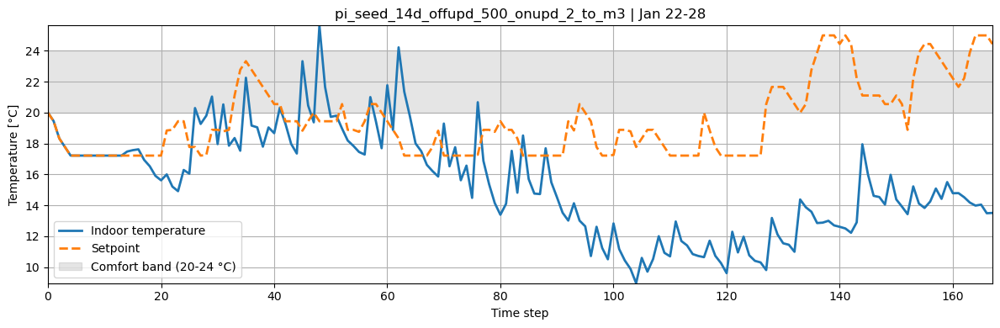

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 29 - Feb 4 | reward: -10826.1559939828
                                    cost_function      value  \
0                           all_time_peak_average   1.000000   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.230095   
5                              daily_peak_average   0.848546   
6                   discomfort_cold_delta_average   6.273183   
7                   discomfort_cold_delta_maximum  17.066050   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.844720   
10                   discomfort_hot_delta_average   0.014850   
11                   discomfort_hot_delta_maximum   1.502951   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proporti

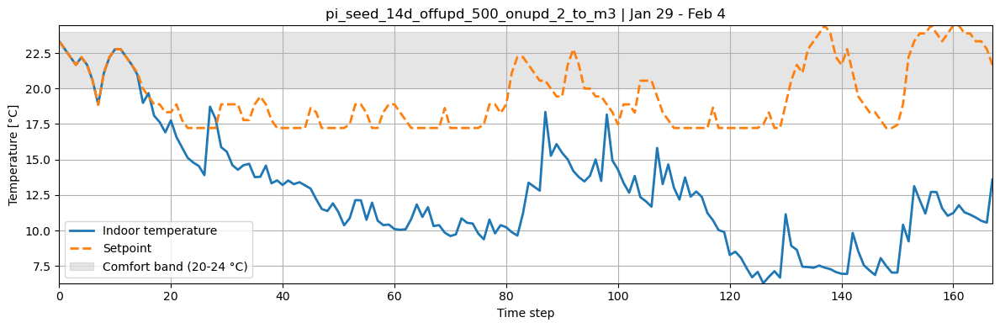

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Jan eval: -88638.28862772111
                                    cost_function      value  \
0                           all_time_peak_average   0.841080   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.248380   
5                              daily_peak_average   0.797951   
6                   discomfort_cold_delta_average  10.023817   
7                   discomfort_cold_delta_maximum  19.318733   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.979079   
10                   discomfort_hot_delta_average   0.000000   
11                   discomfort_hot_delta_maximum   0.000000   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   0.000000   
14    

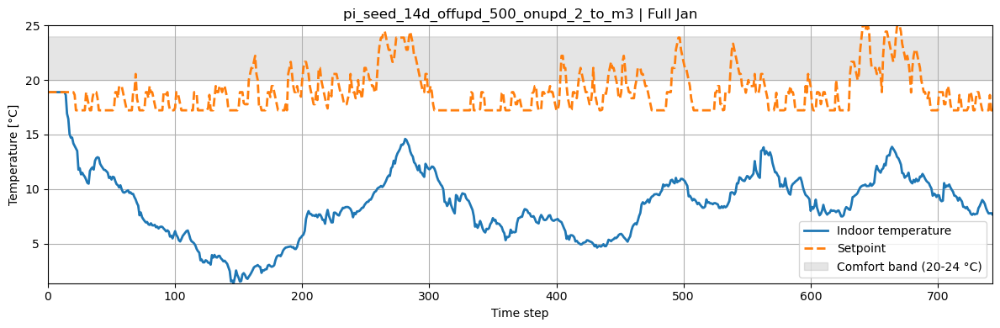

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 5-11 | reward: -3757.741505539384
                                    cost_function      value  \
0                           all_time_peak_average   0.719338   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.117393   
5                              daily_peak_average   0.839876   
6                   discomfort_cold_delta_average   3.903535   
7                   discomfort_cold_delta_maximum  10.199673   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.748503   
10                   discomfort_hot_delta_average   0.101195   
11                   discomfort_hot_delta_maximum   2.974503   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   

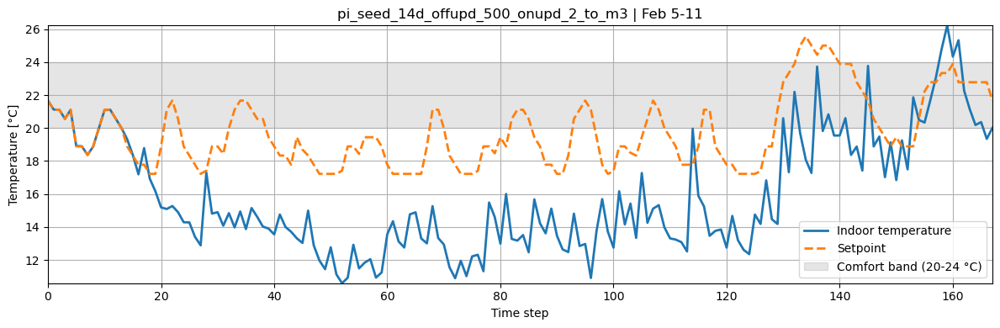

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 12-18 | reward: -499.3050057108594
                                    cost_function     value  \
0                           all_time_peak_average  0.941574   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.119904   
5                              daily_peak_average  0.992284   
6                   discomfort_cold_delta_average  0.760432   
7                   discomfort_cold_delta_maximum  4.798071   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.133333   
10                   discomfort_hot_delta_average  0.599449   
11                   discomfort_hot_delta_maximum  5.149569   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.115152   
14

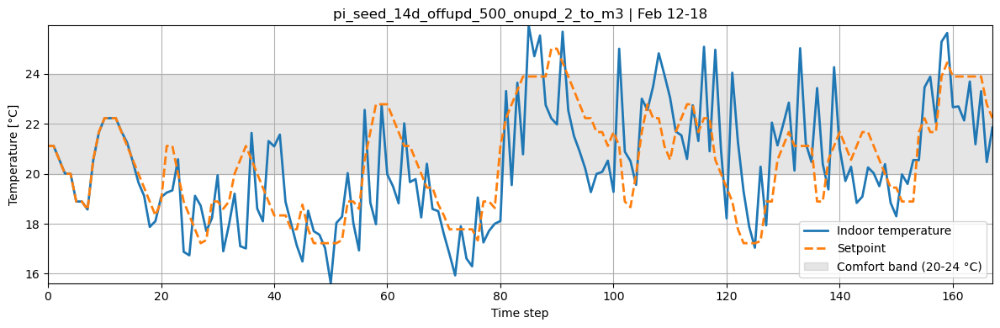

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 19-25 | reward: -837.4505522212748
                                    cost_function     value  \
0                           all_time_peak_average  0.923887   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.076164   
5                              daily_peak_average  1.051858   
6                   discomfort_cold_delta_average  0.352513   
7                   discomfort_cold_delta_maximum  4.025940   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.043210   
10                   discomfort_hot_delta_average  1.110251   
11                   discomfort_hot_delta_maximum  5.717993   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.203704   
14

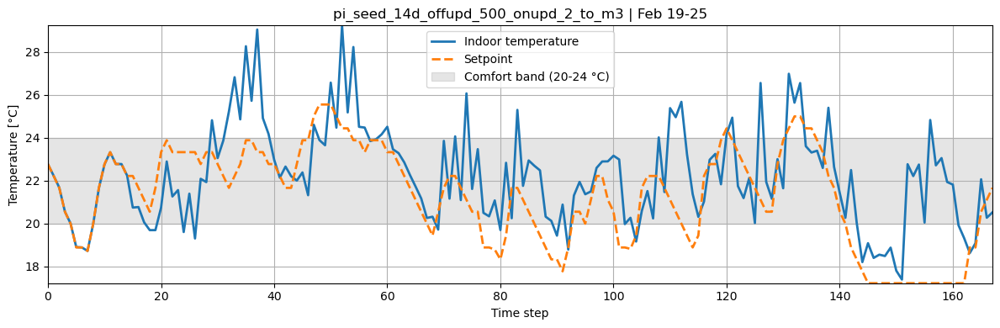

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 26 - Mar 4 | reward: -1113.506438096214
                                    cost_function     value  \
0                           all_time_peak_average  1.188238   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.128967   
5                              daily_peak_average  1.145148   
6                   discomfort_cold_delta_average  0.161852   
7                   discomfort_cold_delta_maximum  2.946285   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.012500   
10                   discomfort_hot_delta_average  1.739072   
11                   discomfort_hot_delta_maximum  8.346018   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.412500 

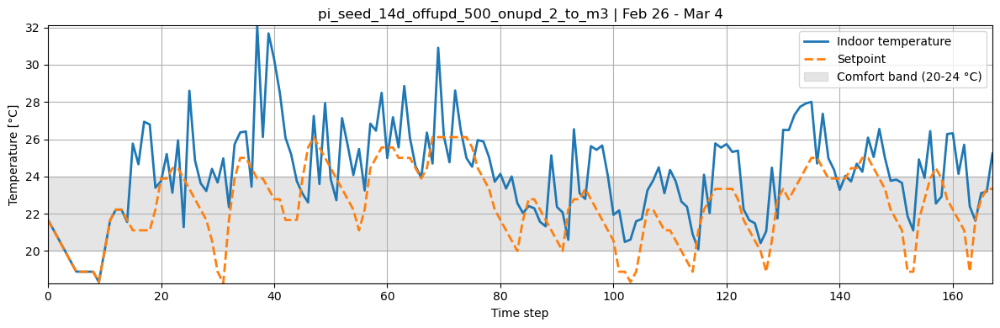

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Feb eval: -8771.729728166323
                                    cost_function     value  \
0                           all_time_peak_average  0.988621   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.085124   
5                              daily_peak_average  1.149953   
6                   discomfort_cold_delta_average  0.059779   
7                   discomfort_cold_delta_maximum  2.709887   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.004580   
10                   discomfort_hot_delta_average  2.773714   
11                   discomfort_hot_delta_maximum  9.732420   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.604580   
14                   

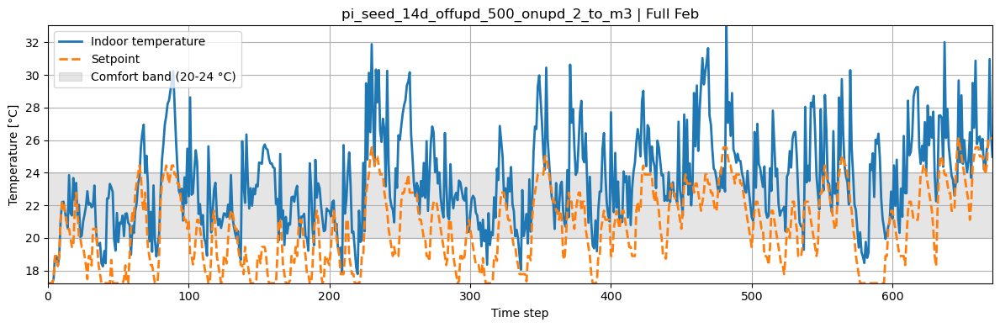

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 5-11 | reward: -1222.0657069469416
                                    cost_function     value  \
0                           all_time_peak_average  0.888974   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.025278   
5                              daily_peak_average  1.020261   
6                   discomfort_cold_delta_average  0.109821   
7                   discomfort_cold_delta_maximum  2.913406   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.006250   
10                   discomfort_hot_delta_average  2.002722   
11                   discomfort_hot_delta_maximum  6.968168   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.475000   
14

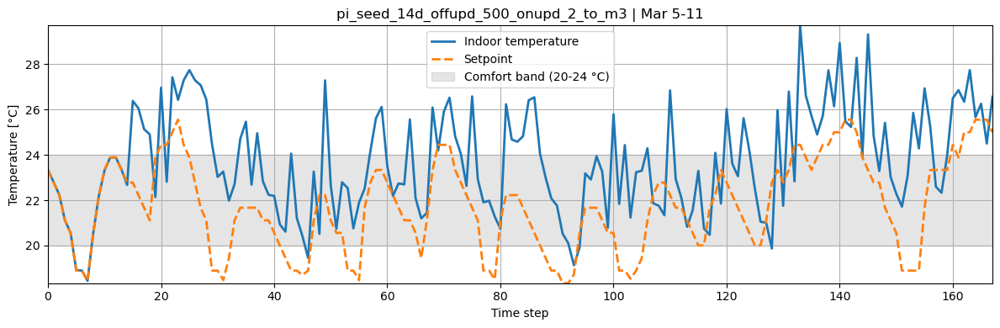

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 12-18 | reward: -1475.809968532616
                                    cost_function         value  \
0                           all_time_peak_average  8.310466e-01   
1         annual_normalized_unserved_energy_total  1.213386e-09   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.017616e+00   
5                              daily_peak_average  9.383720e-01   
6                   discomfort_cold_delta_average  8.828497e-02   
7                   discomfort_cold_delta_maximum  2.022663e+00   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  6.211180e-03   
10                   discomfort_hot_delta_average  2.068402e+00   
11                   discomfort_hot_delta_maximum  8.497684e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13       

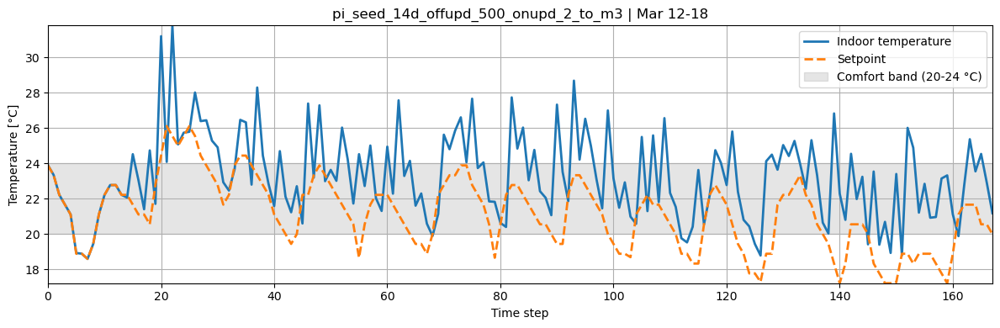

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 19-25 | reward: -1775.6659496895845
                                    cost_function         value  \
0                           all_time_peak_average  1.359794e+00   
1         annual_normalized_unserved_energy_total  1.081594e-09   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.018586e+00   
5                              daily_peak_average  1.137169e+00   
6                   discomfort_cold_delta_average  5.439033e-02   
7                   discomfort_cold_delta_maximum  1.935162e+00   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  0.000000e+00   
10                   discomfort_hot_delta_average  2.304973e+00   
11                   discomfort_hot_delta_maximum  8.048861e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13      

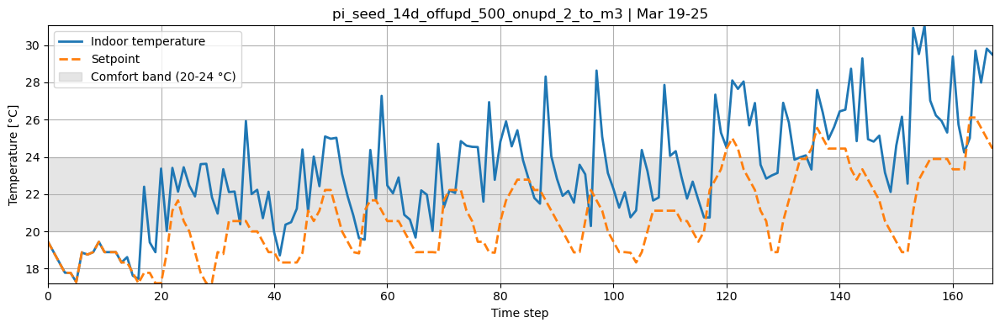

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 26-31 | reward: -564.6314794891405
                                    cost_function     value  \
0                           all_time_peak_average  1.028482   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.103082   
5                              daily_peak_average  1.100990   
6                   discomfort_cold_delta_average  0.361679   
7                   discomfort_cold_delta_maximum  3.660070   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.056338   
10                   discomfort_hot_delta_average  1.125163   
11                   discomfort_hot_delta_maximum  6.369810   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.260563   
14

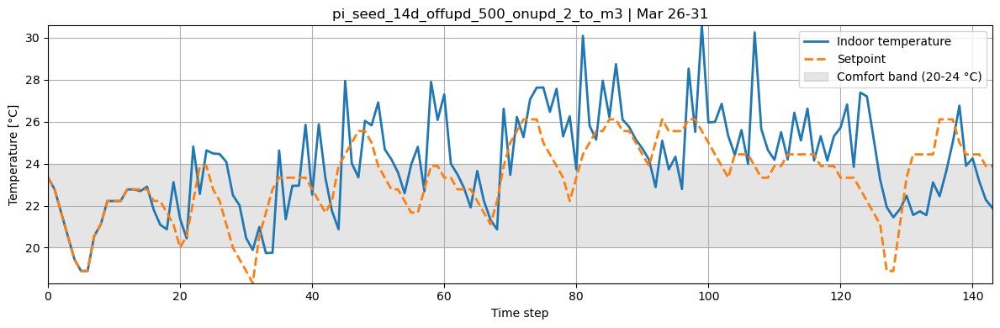

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full Mar eval: -4138.798741478691
                                    cost_function     value  \
0                           all_time_peak_average  0.956646   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.084995   
5                              daily_peak_average  1.095318   
6                   discomfort_cold_delta_average  0.133006   
7                   discomfort_cold_delta_maximum  2.832191   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.011236   
10                   discomfort_hot_delta_average  1.667985   
11                   discomfort_hot_delta_maximum  7.266502   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.389045   
14                   

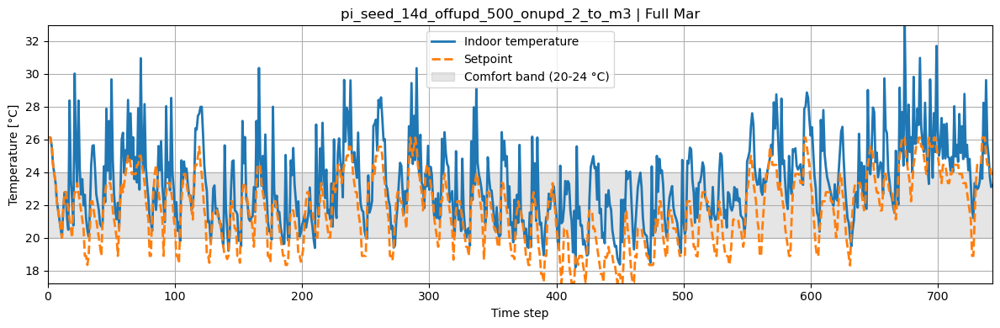

,week_idx,week_label,week_start,week_end,online_steps,offline_days,offline_updates,online_updates_per_step,offline_lr,online_lr,auto_ent_before_update,auto_ent_after_update,eval_reward_after_update,replay_size_after_update
0,1,Jan 15-21,336,503,167,14,500,2,0.0003,0.0003,1.128273,1.118268,-3301.513333,502
1,2,Jan 22-28,504,671,167,14,500,2,0.0003,0.0003,1.118268,1.082129,-5644.987616,669
2,3,Jan 29 - Feb 4,672,839,167,14,500,2,0.0003,0.0003,1.082129,1.085025,-10826.155994,836
3,4,Feb 5-11,840,1007,167,14,500,2,0.0003,0.0003,1.085025,1.039916,-3757.741506,1003
4,5,Feb 12-18,1008,1175,167,14,500,2,0.0003,0.0003,1.039916,0.988613,-499.305006,1170
5,6,Feb 19-25,1176,1343,167,14,500,2,0.0003,0.0003,0.988613,0.981683,-837.450552,1337
6,7,Feb 26 - Mar 4,1344,1511,167,14,500,2,0.0003,0.0003,0.981683,1.007612,-1113.506438,1504
7,8,Mar 5-11,1512,1679,167,14,500,2,0.0003,0.0003,1.007612,1.039961,-1222.065707,1671
8,9,Mar 12-18,1680,1847,167,14,500,2,0.0003,0.0003,1.039961,1.071077,-1475.809969,1838
9,10,Mar 19-25,1848,2015,167,14,500,2,0.0003,0.0003,1.071077,1.085811,-1775.665950,2005


,month,month_start,month_end,offline_days,offline_updates,online_updates_per_step,offline_lr,online_lr,eval_reward,replay_size_after_update
0,Jan,0,743,14,500,2,0.0003,0.0003,-88638.288628,836
1,Feb,744,1415,14,500,2,0.0003,0.0003,-8771.729728,1504
2,Mar,1416,2159,14,500,2,0.0003,0.0003,-4138.798741,2148


Saved final checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_pi_seed_14d_offupd_500_onupd_2_to_m3_final
Saved final replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_pi_seed_14d_offupd_500_onupd_2_to_m3_final_replay.pkl


In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm
from stable_baselines3 import SAC

# ============================================================
# Tunable offline-seed + online-finetune SAC experiment
# ============================================================
# Requires these helpers to already exist:
# - make_period_env
# - build_pi_period_dataset
# - prefill_replay_buffer_from_npz
# - rollout_and_kpis
# - set_sac_learning_rate
# - plot_comfort
# - MONTH_TO_RANGE, JAN_START, JAN_END, FEB_START, FEB_END
# - RANDOM_SEED, NOTEBOOK_DIR
# - REFERENCE_OBSERVATION_SPACE, REFERENCE_ACTION_SPACE
# ============================================================

# ----------------------------
# 0) Experiment knobs
# ----------------------------
TARGET_END_MONTH = 3                         # evaluate/train until end of this month
TARGET_END = MONTH_TO_RANGE[TARGET_END_MONTH][1]

# Offline data window
OFFLINE_START = JAN_START
OFFLINE_DAYS = 14                   # how much PI data to seed with
OFFLINE_END = min(TARGET_END, OFFLINE_START + OFFLINE_DAYS * 24 - 1)

# Online phase starts after offline seed window
ONLINE_START = OFFLINE_END + 1
ONLINE_END = TARGET_END

if ONLINE_START > ONLINE_END:
    raise ValueError("ONLINE_START > ONLINE_END. Reduce OFFLINE_DAYS or extend TARGET_END_MONTH.")

# Offline training
RUN_OFFLINE_UPDATES = True
OFFLINE_UPDATES = 500                         # e.g. 0, 500, 1500, 5000
OFFLINE_LR = 3e-4
OFFLINE_BATCH_SIZE = 256

# Online training
ONLINE_UPDATES_PER_STEP = 2                 # MERLIN-style would be 2
ONLINE_LR = 3e-4
ONLINE_DETERMINISTIC_ACTIONS = False        # False = SAC samples during learning

# Model architecture / buffer
BUFFER_SIZE = 100_000
NET_ARCH = [400, 400]
ENT_COEF = "auto"
USE_SAVED_REPLAY_IF_EXISTS = False
FORCE_REBUILD_DATASET = False

# Evaluation
EVAL_EVERY_DAYS = 7
PLOT_WEEKLY = True
PLOT_MONTHLY = True
PROGRESS_BAR = False

# Naming
EXPERIMENT_TAG = (
    f"pi_seed_{OFFLINE_DAYS}d"
    f"_offupd_{OFFLINE_UPDATES}"
    f"_onupd_{ONLINE_UPDATES_PER_STEP}"
    f"_to_m{TARGET_END_MONTH}"
)

dataset_path = NOTEBOOK_DIR / f"{EXPERIMENT_TAG}_dataset.npz"
ckpt_prefill_path = NOTEBOOK_DIR / f"sac_{EXPERIMENT_TAG}_prefill"
ckpt_offline_path = NOTEBOOK_DIR / f"sac_{EXPERIMENT_TAG}_offline"
ckpt_final_path = NOTEBOOK_DIR / f"sac_{EXPERIMENT_TAG}_final"
replay_prefill_path = NOTEBOOK_DIR / f"sac_{EXPERIMENT_TAG}_prefill_replay.pkl"
replay_final_path = NOTEBOOK_DIR / f"sac_{EXPERIMENT_TAG}_final_replay.pkl"

MONTH_LABELS = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}

def step_to_month_day(step):
    for month, (start, end) in MONTH_TO_RANGE.items():
        if start <= step <= end:
            day = int((step - start) // 24 + 1)
            return MONTH_LABELS.get(month, str(month)), day
    raise ValueError(f"Step {step} is outside MONTH_TO_RANGE.")

def format_window_label(start, end):
    sm, sd = step_to_month_day(start)
    em, ed = step_to_month_day(end)
    return f"{sm} {sd}-{ed}" if sm == em else f"{sm} {sd} - {em} {ed}"

def current_auto_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

def manual_sac_updates(model, gradient_steps, batch_size=None):
    batch_size = batch_size or model.batch_size
    for _ in range(int(gradient_steps)):
        model.train(batch_size=batch_size, gradient_steps=1)

def collect_online_with_manual_updates(
    model,
    start,
    end,
    updates_per_step=2,
    deterministic=False,
):
    env = make_period_env(start, end)
    obs, _ = env.reset()
    done = False
    total_reward = 0.0
    transitions = 0

    obs_dim = model.observation_space.shape[-1]
    act_dim = model.action_space.shape[-1]

    ent_before = current_auto_ent_coef(model)

    while not done:
        action, _ = model.predict(obs, deterministic=deterministic)
        next_obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        obs_i = np.asarray(obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        next_obs_i = np.asarray(next_obs, dtype=np.float32).reshape(model.n_envs, obs_dim)
        action_i = np.asarray(action, dtype=np.float32).reshape(model.n_envs, act_dim)
        reward_i = np.asarray([reward], dtype=np.float32).reshape(model.n_envs)
        done_i = np.asarray([done], dtype=bool).reshape(model.n_envs)

        model.replay_buffer.add(
            obs_i,
            next_obs_i,
            action_i,
            reward_i,
            done_i,
            infos=[{} for _ in range(model.n_envs)],
        )

        if updates_per_step > 0:
            manual_sac_updates(model, gradient_steps=updates_per_step, batch_size=model.batch_size)

        total_reward += float(reward)
        transitions += 1
        obs = next_obs

    ent_after = current_auto_ent_coef(model)

    return {
        "env": env,
        "reward": total_reward,
        "kpis": env.unwrapped.evaluate(),
        "transitions": transitions,
        "auto_ent_before": ent_before,
        "auto_ent_after": ent_after,
    }

# ----------------------------
# 1) Build/load PI dataset for offline seed window
# ----------------------------
seed_env, seed_dataset, seed_dataset_mode = build_pi_period_dataset(
    OFFLINE_START,
    OFFLINE_END,
    dataset_path,
    force_rebuild=FORCE_REBUILD_DATASET,
)

print("Experiment:", EXPERIMENT_TAG)
print("Offline seed window:", format_window_label(OFFLINE_START, OFFLINE_END), (OFFLINE_START, OFFLINE_END))
print("Online train window:", format_window_label(ONLINE_START, ONLINE_END), (ONLINE_START, ONLINE_END))
print("Dataset mode:", seed_dataset_mode)
print("Dataset path:", dataset_path)

# ----------------------------
# 2) Build model
# ----------------------------
seed_train_env = make_period_env(OFFLINE_START, OFFLINE_END)
REFERENCE_OBSERVATION_SPACE = seed_train_env.observation_space
REFERENCE_ACTION_SPACE = seed_train_env.action_space

policy_kwargs = dict(net_arch=NET_ARCH)

model = SAC(
    policy="MlpPolicy",
    env=seed_train_env,
    seed=RANDOM_SEED,
    learning_rate=OFFLINE_LR,
    batch_size=OFFLINE_BATCH_SIZE,
    buffer_size=BUFFER_SIZE,
    learning_starts=10**9,          # disable SB3 automatic training path
    train_freq=(1, "step"),
    gradient_steps=1,
    ent_coef=ENT_COEF,
    policy_kwargs=policy_kwargs,
    verbose=1,
)

model._setup_learn(total_timesteps=1)

# ----------------------------
# 3) Prefill replay buffer
# ----------------------------
if USE_SAVED_REPLAY_IF_EXISTS and replay_prefill_path.exists():
    model.load_replay_buffer(str(replay_prefill_path))
    prefill_size = model.replay_buffer.size()
    print(f"Loaded existing prefill replay: {replay_prefill_path}")
else:
    prefill_size = prefill_replay_buffer_from_npz(model, dataset_path)
    print(f"Prefilled replay from dataset: {prefill_size} transitions")

model.save(str(ckpt_prefill_path))
model.save_replay_buffer(str(replay_prefill_path))
print(f"Saved prefill checkpoint: {ckpt_prefill_path}")
print(f"Saved prefill replay: {replay_prefill_path}")

# Optional sanity eval before any offline updates
prefill_eval_env, prefill_eval_reward, prefill_eval_kpis = rollout_and_kpis(
    model, OFFLINE_START, OFFLINE_END
)
print("Prefill-only reward:", prefill_eval_reward)
print(prefill_eval_kpis)
plot_comfort(
    prefill_eval_env,
    title=f"Prefill-only policy | {format_window_label(OFFLINE_START, OFFLINE_END)}"
)

# ----------------------------
# 4) Optional offline SAC updates on seeded replay
# ----------------------------
offline_eval_reward = None
offline_eval_kpis = None

if RUN_OFFLINE_UPDATES and OFFLINE_UPDATES > 0:
    set_sac_learning_rate(model, OFFLINE_LR)
    print(f"Running offline SAC updates: {OFFLINE_UPDATES} | lr={OFFLINE_LR}")

    for _ in tqdm(range(OFFLINE_UPDATES), desc="Offline SAC updates"):
        model.train(batch_size=model.batch_size, gradient_steps=1)

    model.save(str(ckpt_offline_path))
    print(f"Saved offline-updated checkpoint: {ckpt_offline_path}")

    offline_eval_env, offline_eval_reward, offline_eval_kpis = rollout_and_kpis(
        model, OFFLINE_START, OFFLINE_END
    )
    print("Offline-updated reward:", offline_eval_reward)
    print(offline_eval_kpis)
    plot_comfort(
        offline_eval_env,
        title=f"Offline-updated policy | {format_window_label(OFFLINE_START, OFFLINE_END)}"
    )
else:
    print("Skipping offline updates.")

# ----------------------------
# 5) Online learning through remaining horizon
# ----------------------------
set_sac_learning_rate(model, ONLINE_LR)
print(f"Online learning rate set to: {ONLINE_LR}")

weekly_results = []
monthly_results = []

# Which full months are inside the online phase?
months_to_log = []
for month, (m_start, m_end) in MONTH_TO_RANGE.items():
    if m_end < ONLINE_START or m_start > ONLINE_END:
        continue
    months_to_log.append((month, m_start, m_end))

logged_months = set()

for week_idx, week_start in enumerate(range(ONLINE_START, ONLINE_END + 1, EVAL_EVERY_DAYS * 24), start=1):
    week_end = min(ONLINE_END, week_start + EVAL_EVERY_DAYS * 24 - 1)
    week_label = format_window_label(week_start, week_end)

    result = collect_online_with_manual_updates(
        model,
        start=week_start,
        end=week_end,
        updates_per_step=ONLINE_UPDATES_PER_STEP,
        deterministic=ONLINE_DETERMINISTIC_ACTIONS,
    )

    week_env = result["env"]
    week_reward = result["reward"]
    week_kpis = result["kpis"]

    print(f"Weekly eval | {week_label} | reward: {week_reward}")
    print(week_kpis)

    if PLOT_WEEKLY:
        plot_comfort(
            week_env,
            title=f"{EXPERIMENT_TAG} | {week_label}",
        )

    weekly_results.append({
        "week_idx": week_idx,
        "week_label": week_label,
        "week_start": week_start,
        "week_end": week_end,
        "online_steps": result["transitions"],
        "offline_days": OFFLINE_DAYS,
        "offline_updates": OFFLINE_UPDATES,
        "online_updates_per_step": ONLINE_UPDATES_PER_STEP,
        "offline_lr": OFFLINE_LR,
        "online_lr": ONLINE_LR,
        "auto_ent_before_update": result["auto_ent_before"],
        "auto_ent_after_update": result["auto_ent_after"],
        "eval_reward_after_update": float(week_reward),
        "replay_size_after_update": int(model.replay_buffer.size()),
    })

    # full-month evals once the end of that month has been reached online
    for month, m_start, m_end in months_to_log:
        if month in logged_months:
            continue
        if week_end >= m_end:
            month_name = MONTH_LABELS[month]
            m_env, m_reward, m_kpis = rollout_and_kpis(model, m_start, m_end)
            print(f"Full {month_name} eval:", m_reward)
            print(m_kpis)

            if PLOT_MONTHLY:
                plot_comfort(m_env, title=f"{EXPERIMENT_TAG} | Full {month_name}")

            monthly_results.append({
                "month": month_name,
                "month_start": m_start,
                "month_end": m_end,
                "offline_days": OFFLINE_DAYS,
                "offline_updates": OFFLINE_UPDATES,
                "online_updates_per_step": ONLINE_UPDATES_PER_STEP,
                "offline_lr": OFFLINE_LR,
                "online_lr": ONLINE_LR,
                "eval_reward": float(m_reward),
                "replay_size_after_update": int(model.replay_buffer.size()),
            })
            logged_months.add(month)

weekly_df = pd.DataFrame(weekly_results)
monthly_df = pd.DataFrame(monthly_results)

display(weekly_df)
display(monthly_df)

# ----------------------------
# 6) Save final model + replay
# ----------------------------
model.save(str(ckpt_final_path))
model.save_replay_buffer(str(replay_final_path))
print(f"Saved final checkpoint: {ckpt_final_path}")
print(f"Saved final replay: {replay_final_path}")

In [26]:
temp_error = indoor_temp - setpoint
print(temp_error.mean(), np.median(temp_error), temp_error.std())

NameError: name 'indoor_temp' is not defined

In [23]:
# 1) Clean offline pretraining from January jump-start data
# REBUILD_JAN_PI_DATASET = True
REBUILD_JAN_PI_DATASET = False

# jan_pi_env, january_pi_dataset, january_dataset_mode = build_pi_period_dataset(
#     JAN_START,
#     JAN_END,
#     JAN_PI_DATASET_PATH,
#     force_rebuild=REBUILD_JAN_PI_DATASET,
# )
if not JAN_PI_DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Missing MPC jump-start dataset at {JAN_PI_DATASET_PATH}. Run the January MPC dataset cell in my_mpc.ipynb first."
    )
jumpstart_npz = np.load(JAN_PI_DATASET_PATH)
jan_pi_env = None
january_pi_dataset = {key: np.asarray(jumpstart_npz[key]) for key in jumpstart_npz.files}
january_dataset_mode = "loaded_existing"
print(f"January jump-start dataset mode: {january_dataset_mode}")
print(f"January jump-start dataset path: {JAN_PI_DATASET_PATH}")

jan_env = make_period_env(JAN_START, JAN_END)
REFERENCE_OBSERVATION_SPACE = jan_env.observation_space
REFERENCE_ACTION_SPACE = jan_env.action_space

jump_model = SAC(
    policy="MlpPolicy",
    env=jan_env,
    seed=RANDOM_SEED,
    learning_starts=0,
    # learning_rate=1e-4,
    batch_size=256,
    buffer_size=50_000,
    train_freq=(1, "step"),
    # gradient_steps=1,
    ent_coef="auto",
    verbose=1,
)

# Required before manual replay-buffer usage for pure offline updates.
jump_model._setup_learn(total_timesteps=1)

buffer_size = prefill_replay_buffer_from_npz(jump_model, JAN_PI_DATASET_PATH)
print(f"Replay buffer size: {buffer_size}")

# Keep offline updates close to the amount of data we actually have.
OFFLINE_UPDATES_PER_SAMPLE = 1.0
OFFLINE_MIN_UPDATES = 500
OFFLINE_MAX_UPDATES = 1000
offline_steps = int(min(OFFLINE_MAX_UPDATES, max(OFFLINE_MIN_UPDATES, round(OFFLINE_UPDATES_PER_SAMPLE * buffer_size))))
offline_steps = 10000
print(f"Offline gradient updates: {offline_steps}")

for _ in tqdm(range(offline_steps), desc="Offline SAC updates"):
    jump_model.train(batch_size=jump_model.batch_size, gradient_steps=1)

jump_model.save(str(OFFLINE_CHECKPOINT_PATH))
print(f"Saved offline jump-start model after {offline_steps} gradient updates: {OFFLINE_CHECKPOINT_PATH}")

# Save replay buffer so online runs can start from the exact offline buffer state.
jump_model.save_replay_buffer(str(OFFLINE_REPLAY_PATH))
print(f"Saved replay buffer: {OFFLINE_REPLAY_PATH}")


January jump-start dataset mode: loaded_existing
January jump-start dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/january_mpc_dataset_comfort_raw.npz


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Replay buffer size: 743
Offline gradient updates: 10000


Offline SAC updates:   5%|▌         | 535/10000 [00:02<00:46, 205.23it/s]


KeyboardInterrupt: 

In [32]:
# 2) Evaluate the offline model on January and February with the same wrapper stack
jan_eval_env, jan_reward, jan_kpis = rollout_and_kpis(
    jump_model,
    JAN_START,
    JAN_END,
)

feb_eval_env, feb_reward_offline, feb_kpis_offline = rollout_and_kpis(
    jump_model,
    FEB_START,
    FEB_END,
)

print("January offline reward:", jan_reward)
print("February offline reward:", feb_reward_offline)
print("February offline KPIs:")
print(feb_kpis_offline)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

January offline reward: -76194.17484743967
February offline reward: -70749.73704644125
February offline KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   0.799841   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.227097   
5                              daily_peak_average   0.854848   
6                   discomfort_cold_delta_average   9.385370   
7                   discomfort_cold_delta_maximum  17.246824   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.963359   
10                   discomfort_hot_delta_average   0.000136   
11                   discomfort_hot_delta_maximum   0.069214   
12                   discomfort_hot_delta_minimum   0.0000

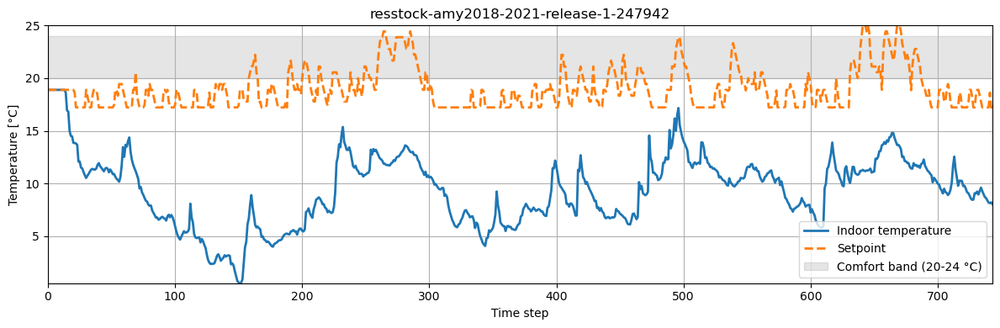

In [34]:
plot_comfort(jan_eval_env)

In [35]:
# 2.5) Load pretrained offline SAC checkpoint
jan_checkpoint = SAC.load(str(OFFLINE_CHECKPOINT_PATH), env=None)
print(f"Loaded pretrained checkpoint: {OFFLINE_CHECKPOINT_PATH}")


Loaded pretrained checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jumpstart_offline_jan_mpc


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

February OFFLINE-only reward: -70749.73704644125
February OFFLINE-only KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   0.799841   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.227097   
5                              daily_peak_average   0.854848   
6                   discomfort_cold_delta_average   9.385370   
7                   discomfort_cold_delta_maximum  17.246824   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.963359   
10                   discomfort_hot_delta_average   0.000136   
11                   discomfort_hot_delta_maximum   0.069214   
12                   discomfort_hot_delta_minimum   0.000000   
13                      dis

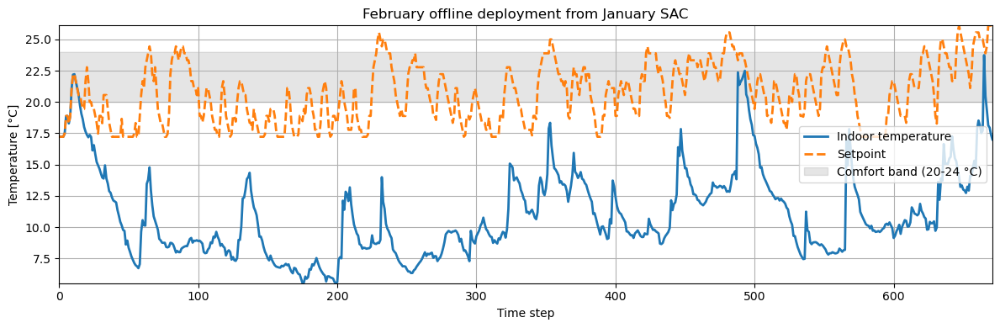

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Warm replay buffer size: 743 (loaded_saved_replay).
Online fine-tuning steps: 3355


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 671       |
|    ep_rew_mean     | -1.19e+04 |
| time/              |           |
|    episodes        | 4         |
|    fps             | 128       |
|    time_elapsed    | 20        |
|    total_timesteps | 2684      |
| train/             |           |
|    actor_loss      | 175       |
|    critic_loss     | 1.49e+03  |
|    ent_coef        | 0.169     |
|    ent_coef_loss   | 3.15      |
|    learning_rate   | 0.0003    |
|    n_updates       | 12683     |
----------------------------------


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

February ONLINE-finetuned reward: -3916.028632502448
February ONLINE-finetuned KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   1.104607   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.228551   
5                              daily_peak_average   1.158548   
6                   discomfort_cold_delta_average   1.025417   
7                   discomfort_cold_delta_maximum   5.924456   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.209160   
10                   discomfort_hot_delta_average   0.803803   
11                   discomfort_hot_delta_maximum  12.209911   
12                   discomfort_hot_delta_minimum   0.000000   
13                 

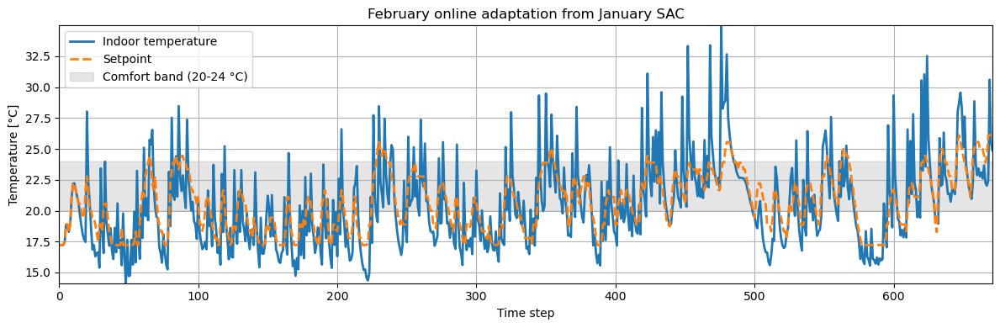

Reward delta (online - offline): 66833.7084139388
Saved February online-adapted checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jumpstart_plus_feb_online_from_mpc


In [38]:
# 3) February comparison: offline checkpoint vs online fine-tuned SAC
feb_train_env = make_period_env(FEB_START, FEB_END)

# ---- Tunable online SAC knobs ----
ONLINE_LR = 3e-4
ONLINE_FRACTION = 1.0

# A) Offline-only February performance (pure deployment/inference; no learning)
feb_offline_env, feb_reward_offline_only, feb_kpis_offline_only = rollout_and_kpis(
    jan_checkpoint,
    FEB_START,
    FEB_END,
)

print("February OFFLINE-only reward:", feb_reward_offline_only)
print("February OFFLINE-only KPIs:")
print(feb_kpis_offline_only)
plot_comfort(feb_offline_env, title='February offline deployment from January SAC')

# B) Online fine-tuned February performance
warm_model = SAC.load(str(OFFLINE_CHECKPOINT_PATH), env=feb_train_env)
warm_model.learning_starts = 0
set_sac_learning_rate(warm_model, ONLINE_LR)

# Seed replay with the exact January offline buffer before February online updates.
seeded_size, seeded_mode = seed_online_replay_buffer(
    warm_model,
    replay_buffer_path=OFFLINE_REPLAY_PATH,
    dataset_path=JAN_PI_DATASET_PATH,
)
print(f"Warm replay buffer size: {seeded_size} ({seeded_mode}).")

FEB_TIMESTEPS = feb_train_env.unwrapped.time_steps - 1
online_steps = max(24, 5*int(FEB_TIMESTEPS * ONLINE_FRACTION))
print("Online fine-tuning steps:", online_steps)
warm_model.learn(total_timesteps=online_steps, reset_num_timesteps=False)

feb_online_env, feb_reward_online, feb_kpis_online = rollout_and_kpis(
    warm_model,
    FEB_START,
    FEB_END,
)

print("February ONLINE-finetuned reward:", feb_reward_online)
print("February ONLINE-finetuned KPIs:")
print(feb_kpis_online)
plot_comfort(feb_online_env, title='February online adaptation from January SAC')

print("Reward delta (online - offline):", feb_reward_online - feb_reward_offline_only)

warm_model.save(str(ONLINE_CHECKPOINT_PATH))
print(f"Saved February online-adapted checkpoint: {ONLINE_CHECKPOINT_PATH}")


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Training fresh SAC on February only
February passes: 2
Training env steps: 1342


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Fresh February-trained SAC | February reward: -23961.32537008014
Fresh February-trained SAC | February KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   0.956333   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.153738   
5                              daily_peak_average   0.944227   
6                   discomfort_cold_delta_average   5.219907   
7                   discomfort_cold_delta_maximum  12.912944   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.890076   
10                   discomfort_hot_delta_average   0.000486   
11                   discomfort_hot_delta_maximum   0.235052   
12                   discomfort_hot_delta_minimum   0.00000

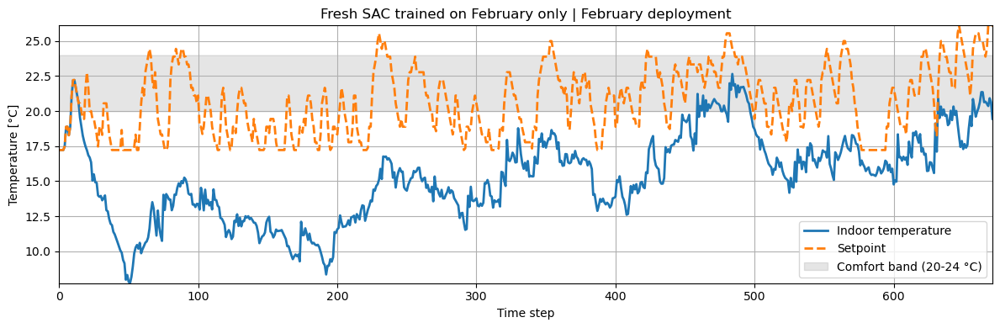

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Fresh February-trained SAC | March reward: -38060.45207726772
Fresh February-trained SAC | March KPIs:
                                    cost_function      value  \
0                           all_time_peak_average   0.766627   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.137640   
5                              daily_peak_average   0.845271   
6                   discomfort_cold_delta_average   6.350097   
7                   discomfort_cold_delta_maximum  11.982291   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.957865   
10                   discomfort_hot_delta_average   0.000124   
11                   discomfort_hot_delta_maximum   0.020226   
12                   discomfort_hot_delta_minimum   0.000000   
1

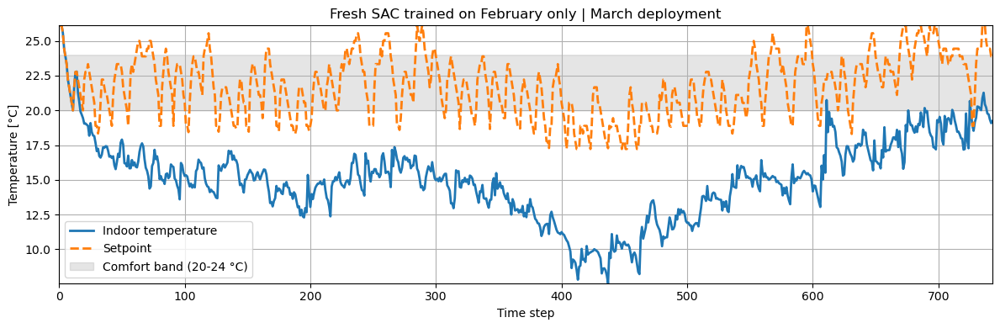

In [37]:
# 3.5) Fresh SAC trained on February only, then deployed on February and March
MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

FRESH_FEB_PASSES = 2
FRESH_FEB_TIMESTEPS = make_period_env_raw(FEB_START, FEB_END).unwrapped.time_steps - 1
fresh_train_steps = FRESH_FEB_PASSES * FRESH_FEB_TIMESTEPS

fresh_feb_env = make_period_env_raw(FEB_START, FEB_END)
fresh_feb_model = SAC(
    policy="MlpPolicy",
    env=fresh_feb_env,
    seed=RANDOM_SEED,
    learning_starts=0,
    # learning_rate=1e-4,
    batch_size=256,
    buffer_size=50_000,
    train_freq=(1, "step"),
    # gradient_steps=1,
    ent_coef="auto",
    verbose=1,
)

print("Training fresh SAC on February only")
print("February passes:", FRESH_FEB_PASSES)
print("Training env steps:", fresh_train_steps)

fresh_feb_model.learn(total_timesteps=fresh_train_steps)

fresh_feb_eval_env, fresh_feb_reward, fresh_feb_kpis = rollout_and_kpis(
    fresh_feb_model,
    FEB_START,
    FEB_END,
)
print("Fresh February-trained SAC | February reward:", fresh_feb_reward)
print("Fresh February-trained SAC | February KPIs:")
print(fresh_feb_kpis)
plot_comfort(fresh_feb_eval_env, title='Fresh SAC trained on February only | February deployment')

fresh_mar_env, fresh_mar_reward, fresh_mar_kpis = rollout_and_kpis(
    fresh_feb_model,
    MAR_START,
    MAR_END,
)
print("Fresh February-trained SAC | March reward:", fresh_mar_reward)
print("Fresh February-trained SAC | March KPIs:")
print(fresh_mar_kpis)
plot_comfort(fresh_mar_env, title='Fresh SAC trained on February only | March deployment')


In [ ]:
# 4) Extensive online hyperparameter grid search on February
import itertools

# Baseline (deployment/inference only)
_, feb_reward_offline_baseline, feb_kpis_offline_baseline = rollout_and_kpis(
    jan_checkpoint,
    FEB_START,
    FEB_END,
)

LR_GRID = [1e-3, 1e-5, 1e-4, 1e-2]
ENT_GRID = [0.005, 0.01, 0.1, 1, 10, 15, 5]
FRACTION_GRID = [0.05, 0.1, 0.25, 0.5, 1.0]
BUFFER_GRID = [100_000, 250_000]

BATCH_SIZE = 256
GRADIENT_STEPS = 1
TRAIN_FREQ = (1, "step")

FEB_TIMESTEPS = make_period_env_raw(FEB_START, FEB_END).unwrapped.time_steps - 1

search_results = []
combos = list(itertools.product(LR_GRID, ENT_GRID, FRACTION_GRID, BUFFER_GRID))

for lr, ent, frac, buf in tqdm(combos, desc="Online grid search"):
    env_trial = make_period_env_raw(FEB_START, FEB_END)
    model_trial = SAC(
        policy="MlpPolicy",
        env=env_trial,
        seed=RANDOM_SEED,
        learning_starts=0,
        learning_rate=lr,
        batch_size=BATCH_SIZE,
        buffer_size=buf,
        train_freq=TRAIN_FREQ,
        gradient_steps=GRADIENT_STEPS,
        ent_coef=ent,
        verbose=0,
    )
    model_trial.policy.load_state_dict(jan_checkpoint.policy.state_dict())

    seeded_size, seeded_mode = seed_online_replay_buffer(
        model_trial,
        # replay_buffer_path="sac_jumpstart_offline_jan_replay.pkl",
        replay_buffer_path=str(OFFLINE_REPLAY_PATH),
        # dataset_path="january_pi_dataset.npz",
        dataset_path=str(JAN_PI_DATASET_PATH),
    )

    online_steps = max(24, int(FEB_TIMESTEPS * frac))
    model_trial.learn(total_timesteps=online_steps, reset_num_timesteps=False)

    _, reward_online, kpis_online = rollout_and_kpis(model_trial, FEB_START, FEB_END)

    search_results.append({
        "lr": lr,
        "ent_coef": ent,
        "online_fraction": frac,
        "buffer_size": buf,
        "online_steps": online_steps,
        "seeded_size": int(seeded_size),
        "seeded_mode": seeded_mode,
        "reward_offline": float(feb_reward_offline_baseline),
        "reward_online": float(reward_online),
        "reward_delta": float(reward_online - feb_reward_offline_baseline),
        "kpis_online": kpis_online,
    })

grid_df = pd.DataFrame(search_results).sort_values("reward_delta", ascending=False).reset_index(drop=True)
display(grid_df[["lr", "ent_coef", "online_fraction", "buffer_size", "online_steps", "reward_offline", "reward_online", "reward_delta", "seeded_mode"]])

best_cfg = grid_df.iloc[0]
print("Best config:")
print(best_cfg[["lr", "ent_coef", "online_fraction", "buffer_size", "online_steps", "reward_delta"]])


In [ ]:
# 3) February weekly deployment + end-of-week batch updates
feb_train_env = make_period_env_raw(FEB_START, FEB_END)

# ---- Tunable weekly online SAC knobs ----
ONLINE_LR = 1e-5
ONLINE_ENT_COEF = 'auto'
ONLINE_BATCH_SIZE = 256
ONLINE_BUFFER_SIZE = 250_000
WEEKLY_GRADIENT_STEPS = 250
WEEK_DAYS = 7
DEPLOY_DETERMINISTIC = True

# A) Offline-only February deployment baseline
feb_offline_env, feb_reward_offline_only, feb_kpis_offline_only = rollout_and_kpis(
    jan_checkpoint,
    FEB_START,
    FEB_END,
)

print("February OFFLINE-only reward:", feb_reward_offline_only)
print("February OFFLINE-only KPIs:")
print(feb_kpis_offline_only)
plot_comfort(feb_offline_env)

# B) Online model: deploy one week, then update heavily from replay at week end
warm_model = SAC(
    policy="MlpPolicy",
    env=feb_train_env,
    seed=RANDOM_SEED,
    learning_starts=0,
    learning_rate=ONLINE_LR,
    batch_size=ONLINE_BATCH_SIZE,
    buffer_size=ONLINE_BUFFER_SIZE,
    train_freq=(1, "step"),
    gradient_steps=1,
    ent_coef=ONLINE_ENT_COEF,
    verbose=1,
)
warm_model.policy.load_state_dict(jan_checkpoint.policy.state_dict())
seeded_size, seeded_mode = seed_online_replay_buffer(
    warm_model,
    # replay_buffer_path="sac_jumpstart_offline_jan_replay.pkl",
    replay_buffer_path=str(OFFLINE_REPLAY_PATH),
    # dataset_path="january_pi_dataset.npz",
    dataset_path=str(JAN_PI_DATASET_PATH),
)
print(f"Initial replay buffer size: {seeded_size} ({seeded_mode}).")

week_results = []
feb_online_eval_env = None
feb_reward_online = None
feb_kpis_online = None

for week_idx in range(4):
    week_start = FEB_START + week_idx * WEEK_DAYS * 24
    week_end = min(FEB_END, week_start + WEEK_DAYS * 24 - 1)
    if week_start > FEB_END:
        break

    deploy_env, deploy_reward, deploy_kpis, week_transitions = collect_period_into_replay(
        warm_model,
        week_start,
        week_end,
        deterministic=DEPLOY_DETERMINISTIC,
    )

    warm_model.train(batch_size=ONLINE_BATCH_SIZE, gradient_steps=WEEKLY_GRADIENT_STEPS)

    feb_online_eval_env, feb_reward_online, feb_kpis_online = rollout_and_kpis(
        warm_model,
        FEB_START,
        FEB_END,
    )

    week_results.append({
        "week": week_idx + 1,
        "week_start": week_start,
        "week_end": week_end,
        "week_reward": deploy_reward,
        "week_transitions": week_transitions,
        "replay_size": int(warm_model.replay_buffer.size()),
        "full_feb_reward_after_update": float(feb_reward_online),
    })

weekly_df = pd.DataFrame(week_results)
display(weekly_df)

print("February ONLINE-weekly-updated reward:", feb_reward_online)
print("February ONLINE-weekly-updated KPIs:")
print(feb_kpis_online)
plot_comfort(feb_online_eval_env)

print("Reward delta (online weekly - offline):", feb_reward_online - feb_reward_offline_only)

warm_model.save("sac_jumpstart_plus_feb_online_weekly")


In [ ]:
# 4) Sanity check: in-memory offline model vs loaded checkpoint should match on February
debug_env = make_period_env_raw(FEB_START, FEB_END)
obs, _ = debug_env.reset()

action_jump, _ = jump_model.predict(obs, deterministic=True)
action_ckpt, _ = jan_checkpoint.predict(obs, deterministic=True)

print("max |action_jump - action_ckpt|:", np.max(np.abs(action_jump - action_ckpt)))

_, reward_jump_debug, _ = rollout_and_kpis(jump_model, FEB_START, FEB_END)
_, reward_ckpt_debug, _ = rollout_and_kpis(jan_checkpoint, FEB_START, FEB_END)

print("jump_model February reward:", reward_jump_debug)
print("jan_checkpoint February reward:", reward_ckpt_debug)
print("reward diff:", reward_ckpt_debug - reward_jump_debug)


In [ ]:
# 5) Weekly ent_coef schedule experiment: [4, 1, 'auto', 'auto']
WEEKLY_ENT_COEFS = [4.0, 1.0, "auto", "auto"]
ONLINE_LR = 1e-5
ONLINE_BATCH_SIZE = 256
ONLINE_BUFFER_SIZE = 250_000
WEEKLY_GRADIENT_STEPS = 250
WEEK_DAYS = 7
DEPLOY_DETERMINISTIC = True

feb_schedule_offline_env, feb_schedule_offline_reward, feb_schedule_offline_kpis = rollout_and_kpis(
    jan_checkpoint,
    FEB_START,
    FEB_END,
)
print("February OFFLINE-only reward:", feb_schedule_offline_reward)

current_policy_state = {
    k: v.detach().cpu().clone() for k, v in jan_checkpoint.policy.state_dict().items()
}
current_replay_buffer = None
schedule_week_results = []
schedule_final_model = None

for week_idx, week_ent_coef in enumerate(WEEKLY_ENT_COEFS):
    week_start = FEB_START + week_idx * WEEK_DAYS * 24
    week_end = min(FEB_END, week_start + WEEK_DAYS * 24 - 1)
    if week_start > FEB_END:
        break

    week_model_env = make_period_env_raw(FEB_START, FEB_END)
    week_model = SAC(
        policy="MlpPolicy",
        env=week_model_env,
        seed=RANDOM_SEED,
        learning_starts=0,
        learning_rate=ONLINE_LR,
        batch_size=ONLINE_BATCH_SIZE,
        buffer_size=ONLINE_BUFFER_SIZE,
        train_freq=(1, "step"),
        gradient_steps=1,
        ent_coef=week_ent_coef,
        verbose=1,
    )
    week_model._setup_learn(total_timesteps=1)
    week_model.policy.load_state_dict(current_policy_state)

    if current_replay_buffer is None:
        replay_size, replay_mode = seed_online_replay_buffer(
            week_model,
            # replay_buffer_path="sac_jumpstart_offline_jan_replay.pkl",
            replay_buffer_path=str(OFFLINE_REPLAY_PATH),
            # dataset_path="january_pi_dataset.npz",
            dataset_path=str(JAN_PI_DATASET_PATH),
        )
    else:
        week_model.replay_buffer = current_replay_buffer
        replay_size, replay_mode = int(week_model.replay_buffer.size()), "carried_from_previous_week"

    deploy_env, deploy_reward, deploy_kpis, week_transitions = collect_period_into_replay(
        week_model,
        week_start,
        week_end,
        deterministic=DEPLOY_DETERMINISTIC,
    )

    print(f"Week {week_idx + 1} pre-update ent_coef: {week_ent_coef}")
    print(f"Week {week_idx + 1} deployment reward before update: {deploy_reward}")
    print(deploy_kpis)
    plot_comfort(deploy_env)

    week_model.train(batch_size=ONLINE_BATCH_SIZE, gradient_steps=WEEKLY_GRADIENT_STEPS)

    _, full_feb_reward_after_update, full_feb_kpis_after_update = rollout_and_kpis(
        week_model,
        FEB_START,
        FEB_END,
    )

    schedule_week_results.append({
        "week": week_idx + 1,
        "ent_coef": str(week_ent_coef),
        "week_start": week_start,
        "week_end": week_end,
        "replay_mode": replay_mode,
        "replay_size_before_week": int(replay_size),
        "week_transitions": week_transitions,
        "week_reward_before_update": float(deploy_reward),
        "full_feb_reward_after_update": float(full_feb_reward_after_update),
    })

    current_policy_state = {
        k: v.detach().cpu().clone() for k, v in week_model.policy.state_dict().items()
    }
    current_replay_buffer = week_model.replay_buffer
    schedule_final_model = week_model

schedule_weekly_df = pd.DataFrame(schedule_week_results)
display(schedule_weekly_df)

schedule_final_env, schedule_final_reward, schedule_final_kpis = rollout_and_kpis(
    schedule_final_model,
    FEB_START,
    FEB_END,
)

print("February scheduled-online final reward:", schedule_final_reward)
print("February scheduled-online final KPIs:")
print(schedule_final_kpis)
plot_comfort(schedule_final_env)

print("Reward delta (scheduled online - offline):", schedule_final_reward - feb_schedule_offline_reward)


In [ ]:
# 6) Canonical offline pretraining: 200000 gradient steps, then January plot
jan_env_200k = make_period_env_raw(SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP)

jump_model_200k = SAC(
    policy="MlpPolicy",
    env=jan_env_200k,
    seed=RANDOM_SEED,
    learning_starts=0,
    learning_rate=1e-4,
    batch_size=256,
    buffer_size=250_000,
    ent_coef="auto",
    verbose=1,
)

jump_model_200k._setup_learn(total_timesteps=1)
# buffer_size_200k = prefill_replay_buffer_from_npz(jump_model_200k, "january_pi_dataset.npz")
buffer_size_200k = prefill_replay_buffer_from_npz(jump_model_200k, str(JAN_PI_DATASET_PATH))
print(f"Replay buffer size: {buffer_size_200k}")

OFFLINE_GRADIENT_STEPS_200K = 250_000
for _ in tqdm(range(OFFLINE_GRADIENT_STEPS_200K), desc="Offline SAC updates (200k)"):
    jump_model_200k.train(batch_size=jump_model_200k.batch_size, gradient_steps=1)

jump_model_200k.save("sac_jumpstart_offline_jan_200k")
jump_model_200k.save_replay_buffer("sac_jumpstart_offline_jan_200k_replay.pkl")
print("Saved model: sac_jumpstart_offline_jan_200k")
print("Saved replay buffer: sac_jumpstart_offline_jan_200k_replay.pkl")

jan_plot_env_200k, jan_reward_200k, jan_kpis_200k = rollout_and_kpis(
    jump_model_200k,
    SIMULATION_START_TIME_STEP,
    SIMULATION_END_TIME_STEP,
)

print("January offline reward (200k):", jan_reward_200k)
print("January offline KPIs (200k):")
print(jan_kpis_200k)
plot_comfort(jan_plot_env_200k)


In [ ]:
# 7) Weekly February experiment using the 200k offline checkpoint
#    Keep one persistent SAC model, use ent_coef='auto' for the whole run,
#    and decrease learning rate each week while plotting before every update.
jan_checkpoint_200k = SAC.load("sac_jumpstart_offline_jan_200k", env=None)
print("Loaded checkpoint: sac_jumpstart_offline_jan_200k")

WEEKLY_LRS_200K = [1e-4, 5e-5, 1e-6, 5e-6]
ONLINE_BATCH_SIZE_200K = 256
ONLINE_BUFFER_SIZE_200K = 250_000
WEEKLY_GRADIENT_STEPS_200K = 250
WEEK_DAYS_200K = 7
DEPLOY_DETERMINISTIC_200K = True

def set_sac_learning_rate(model, lr):
    optimizers = [model.actor.optimizer, model.critic.optimizer]
    if model.ent_coef_optimizer is not None:
        optimizers.append(model.ent_coef_optimizer)
    for optimizer in optimizers:
        for group in optimizer.param_groups:
            group["lr"] = lr

def current_sac_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

feb_offline_env_200k, feb_offline_reward_200k, feb_offline_kpis_200k = rollout_and_kpis(
    jan_checkpoint_200k,
    FEB_START,
    FEB_END,
)
print("February OFFLINE-only reward (200k):", feb_offline_reward_200k)
print("February OFFLINE-only KPIs (200k):")
print(feb_offline_kpis_200k)
plot_comfort(feb_offline_env_200k)

scheduled_env_200k = make_period_env_raw(FEB_START, FEB_END)
scheduled_model_200k = SAC(
    policy="MlpPolicy",
    env=scheduled_env_200k,
    seed=RANDOM_SEED,
    learning_starts=0,
    learning_rate=WEEKLY_LRS_200K[0],
    batch_size=ONLINE_BATCH_SIZE_200K,
    buffer_size=ONLINE_BUFFER_SIZE_200K,
    train_freq=(1, "step"),
    gradient_steps=1,
    ent_coef="auto",
    verbose=1,
)
scheduled_model_200k._setup_learn(total_timesteps=1)
scheduled_model_200k.policy.load_state_dict(jan_checkpoint_200k.policy.state_dict())
replay_size_200k, replay_mode_200k = seed_online_replay_buffer(
    scheduled_model_200k,
    replay_buffer_path="sac_jumpstart_offline_jan_200k_replay.pkl",
    # dataset_path="january_pi_dataset.npz",
    dataset_path=str(JAN_PI_DATASET_PATH),
)
print(f"Initial replay buffer size: {replay_size_200k} ({replay_mode_200k})")

weekly_schedule_results_200k = []

for week_idx, week_lr in enumerate(WEEKLY_LRS_200K):
    week_start = FEB_START + week_idx * WEEK_DAYS_200K * 24
    week_end = min(FEB_END, week_start + WEEK_DAYS_200K * 24 - 1)
    if week_start > FEB_END:
        break

    set_sac_learning_rate(scheduled_model_200k, week_lr)
    ent_before_update = current_sac_ent_coef(scheduled_model_200k)

    deploy_env_200k, deploy_reward_200k, deploy_kpis_200k, week_transitions_200k = collect_period_into_replay(
        scheduled_model_200k,
        week_start,
        week_end,
        deterministic=DEPLOY_DETERMINISTIC_200K,
    )

    print(f"Week {week_idx + 1} pre-update learning_rate: {week_lr}")
    print(f"Week {week_idx + 1} current auto ent_coef before update: {ent_before_update}")
    print(f"Week {week_idx + 1} deployment reward before update: {deploy_reward_200k}")
    print(deploy_kpis_200k)
    plot_comfort(deploy_env_200k)

    scheduled_model_200k.train(batch_size=ONLINE_BATCH_SIZE_200K, gradient_steps=WEEKLY_GRADIENT_STEPS_200K)
    ent_after_update = current_sac_ent_coef(scheduled_model_200k)

    _, full_feb_reward_after_update_200k, _ = rollout_and_kpis(
        scheduled_model_200k,
        FEB_START,
        FEB_END,
    )

    weekly_schedule_results_200k.append({
        "week": week_idx + 1,
        "learning_rate": float(week_lr),
        "auto_ent_before_update": ent_before_update,
        "auto_ent_after_update": ent_after_update,
        "week_start": week_start,
        "week_end": week_end,
        "replay_size_after_collection": int(scheduled_model_200k.replay_buffer.size()),
        "week_transitions": week_transitions_200k,
        "week_reward_before_update": float(deploy_reward_200k),
        "full_feb_reward_after_update": float(full_feb_reward_after_update_200k),
    })

weekly_schedule_df_200k = pd.DataFrame(weekly_schedule_results_200k)
display(weekly_schedule_df_200k)

final_schedule_env_200k, final_schedule_reward_200k, final_schedule_kpis_200k = rollout_and_kpis(
    scheduled_model_200k,
    FEB_START,
    FEB_END,
)

print("February scheduled-online final reward (200k):", final_schedule_reward_200k)
print("February scheduled-online final KPIs (200k):")
print(final_schedule_kpis_200k)
plot_comfort(final_schedule_env_200k)
print("Reward delta (scheduled online 200k - offline 200k):", final_schedule_reward_200k - feb_offline_reward_200k)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/jan14d_off800_continuous_online_mar_pi_dataset_comfort_raw.npz
Experiment label: jan14d_off800_continuous_online_mar
Offline seed window: Jan 1-14 (0, 335)
Online deployment window: Jan 15 - Mar 31 (336, 2159)
Offline PI dataset mode: rebuilt
Offline PI dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/jan14d_off800_continuous_online_mar_pi_dataset_comfort_raw.npz


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Offline replay buffer size: 335
Offline gradient updates: 800


Offline seed SAC updates: 100%|██████████| 800/800 [00:04<00:00, 189.50it/s]


Saved offline seed checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off800_continuous_online_mar
Saved offline seed replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off800_continuous_online_mar_replay.pkl


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Offline seed reward: -3959.666867273824
Offline seed KPIs:
                                    cost_function         value  \
0                           all_time_peak_average  9.979191e-01   
1         annual_normalized_unserved_energy_total  4.781047e-10   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  9.176415e-01   
5                              daily_peak_average  1.050875e+00   
6                   discomfort_cold_delta_average  8.518163e-01   
7                   discomfort_cold_delta_maximum  7.316436e+00   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  1.604938e-01   
10                   discomfort_hot_delta_average  1.812166e+00   
11                   discomfort_hot_delta_maximum  7.812897e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13 

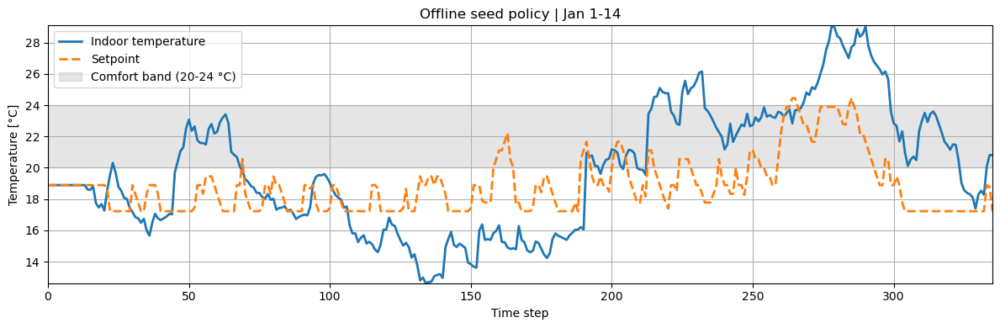

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 15-21 | reward: -3119.6728979786394
                                    cost_function      value  \
0                           all_time_peak_average   0.954244   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.106929   
5                              daily_peak_average   0.973972   
6                   discomfort_cold_delta_average   3.146105   
7                   discomfort_cold_delta_maximum  10.140082   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.546012   
10                   discomfort_hot_delta_average   0.102742   
11                   discomfort_hot_delta_maximum   2.634476   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion 

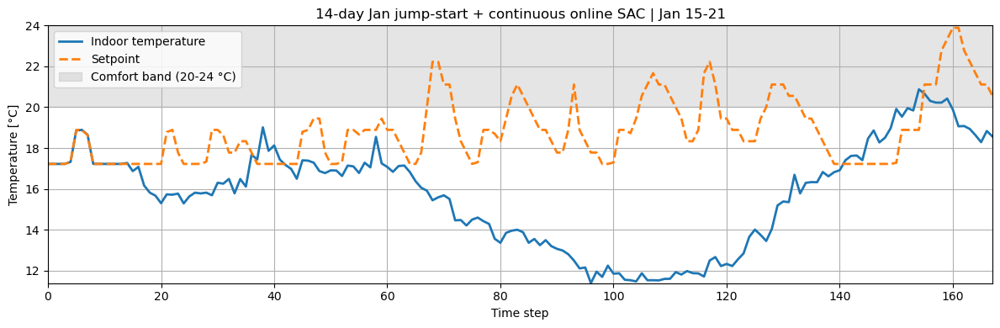

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 22-28 | reward: -17894.511369726664
                                    cost_function      value  \
0                           all_time_peak_average   0.801350   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.282986   
5                              daily_peak_average   0.817534   
6                   discomfort_cold_delta_average   8.627132   
7                   discomfort_cold_delta_maximum  16.615120   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.879747   
10                   discomfort_hot_delta_average   0.001733   
11                   discomfort_hot_delta_maximum   0.262094   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion 

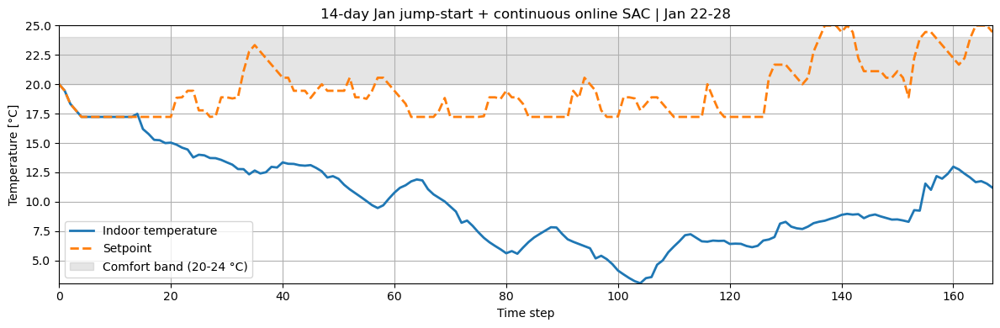

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 29 - Feb 4 | reward: -19638.938096554873
                                    cost_function      value  \
0                           all_time_peak_average   1.000000   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.304191   
5                              daily_peak_average   0.859608   
6                   discomfort_cold_delta_average   8.674218   
7                   discomfort_cold_delta_maximum  19.382652   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.857143   
10                   discomfort_hot_delta_average   0.000706   
11                   discomfort_hot_delta_maximum   0.027727   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_propor

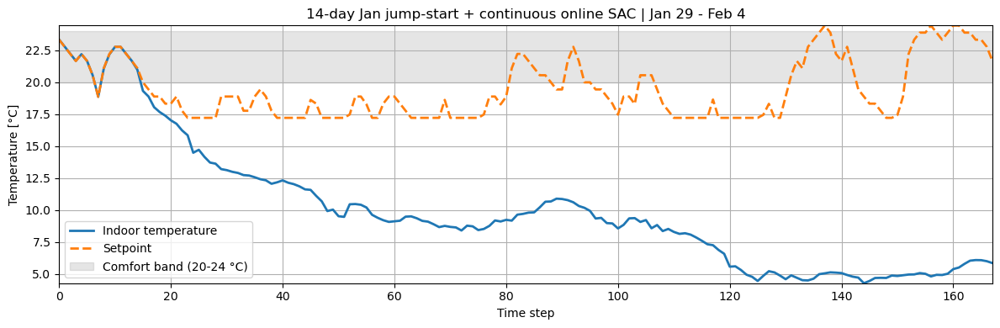

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 5-11 | reward: -6458.252283359231
                                    cost_function      value  \
0                           all_time_peak_average   0.870578   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.101973   
5                              daily_peak_average   0.830100   
6                   discomfort_cold_delta_average   5.297039   
7                   discomfort_cold_delta_maximum  11.826043   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.814371   
10                   discomfort_hot_delta_average   0.014625   
11                   discomfort_hot_delta_maximum   1.208038   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion   

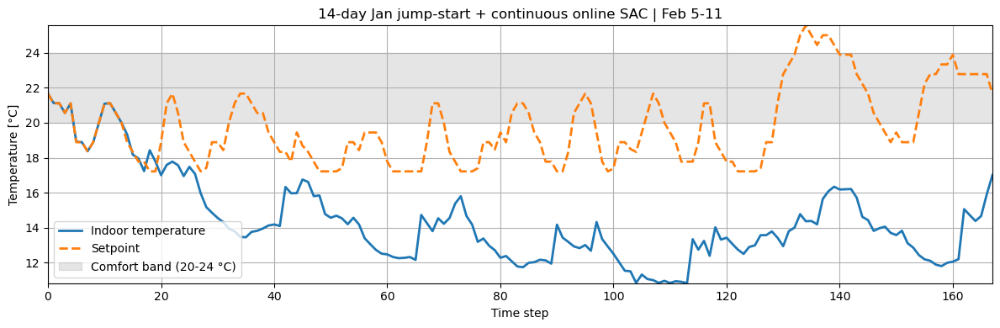

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 12-18 | reward: -2091.618751864852
                                    cost_function     value  \
0                           all_time_peak_average  0.945211   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.188633   
5                              daily_peak_average  1.005324   
6                   discomfort_cold_delta_average  2.819234   
7                   discomfort_cold_delta_maximum  8.231099   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.648485   
10                   discomfort_hot_delta_average  0.007288   
11                   discomfort_hot_delta_maximum  0.599140   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.000000   
14

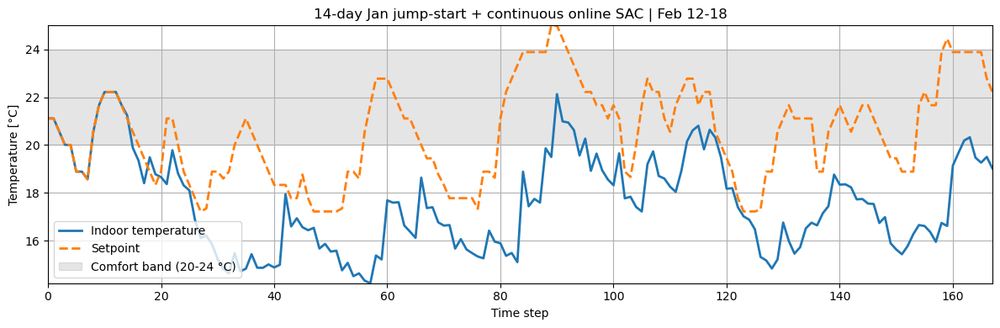

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 19-25 | reward: -618.536145388196
                                    cost_function     value  \
0                           all_time_peak_average  0.986317   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.059882   
5                              daily_peak_average  0.998308   
6                   discomfort_cold_delta_average  1.356348   
7                   discomfort_cold_delta_maximum  5.532314   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.296296   
10                   discomfort_hot_delta_average  0.062707   
11                   discomfort_hot_delta_maximum  1.761044   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.000000   
14 

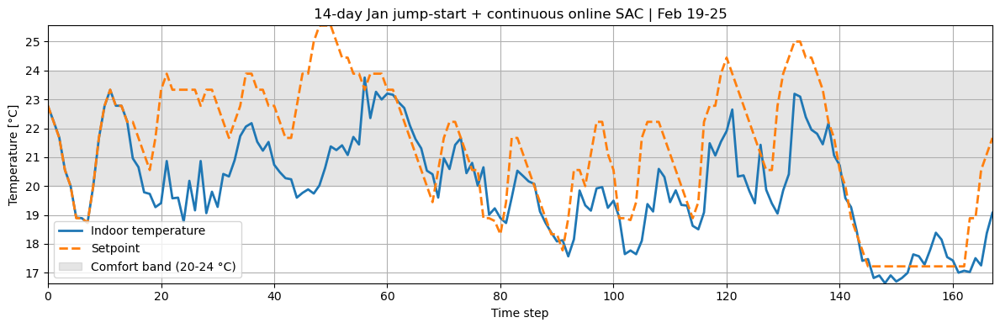

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 26 - Mar 4 | reward: -412.17093090134586
                                    cost_function     value  \
0                           all_time_peak_average  1.191243   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.129413   
5                              daily_peak_average  1.067689   
6                   discomfort_cold_delta_average  0.901977   
7                   discomfort_cold_delta_maximum  4.345951   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.175000   
10                   discomfort_hot_delta_average  0.232075   
11                   discomfort_hot_delta_maximum  4.130816   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.025000

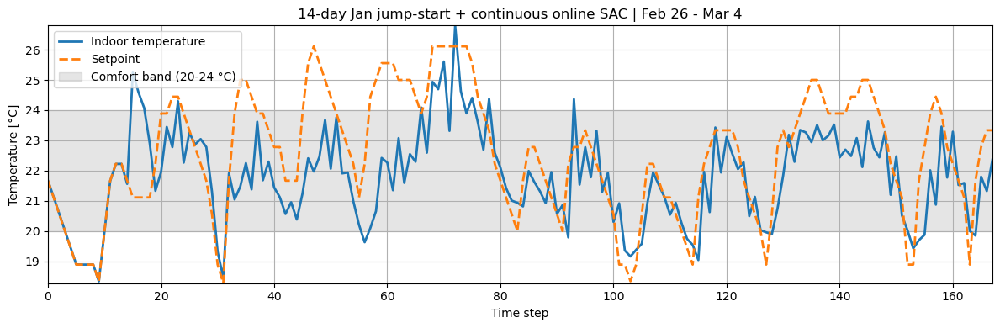

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full February eval after online learning: -2272.6302721994143
                                    cost_function     value  \
0                           all_time_peak_average  1.059863   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.097178   
5                              daily_peak_average  1.086776   
6                   discomfort_cold_delta_average  0.481036   
7                   discomfort_cold_delta_maximum  3.919737   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.088550   
10                   discomfort_hot_delta_average  0.906866   
11                   discomfort_hot_delta_maximum  6.288540   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.192

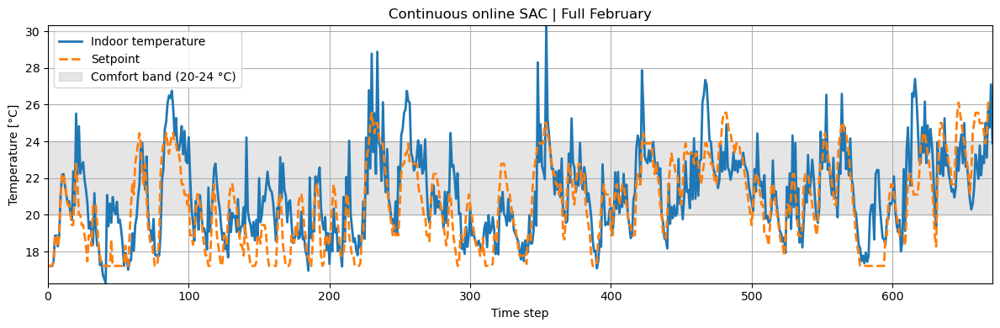

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 5-11 | reward: -395.6251328346734
                                    cost_function     value  \
0                           all_time_peak_average  0.840399   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.043810   
5                              daily_peak_average  0.962659   
6                   discomfort_cold_delta_average  0.780408   
7                   discomfort_cold_delta_maximum  3.554583   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.175000   
10                   discomfort_hot_delta_average  0.387992   
11                   discomfort_hot_delta_maximum  4.511486   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.062500   
14 

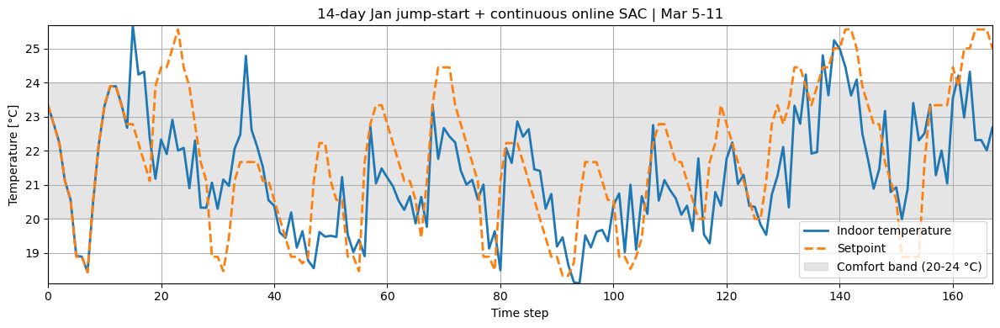

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 12-18 | reward: -431.5599850424587
                                    cost_function     value  \
0                           all_time_peak_average  0.753339   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.032984   
5                              daily_peak_average  0.898668   
6                   discomfort_cold_delta_average  0.606671   
7                   discomfort_cold_delta_maximum  4.066216   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.105590   
10                   discomfort_hot_delta_average  0.557788   
11                   discomfort_hot_delta_maximum  5.099955   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.099379   
14

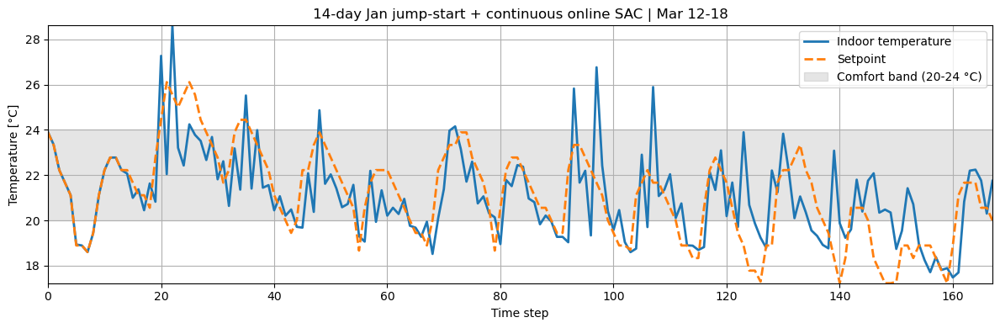

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 19-25 | reward: -582.9491498982497
                                    cost_function     value  \
0                           all_time_peak_average  0.965091   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.044268   
5                              daily_peak_average  0.968182   
6                   discomfort_cold_delta_average  1.139026   
7                   discomfort_cold_delta_maximum  5.187662   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.285714   
10                   discomfort_hot_delta_average  0.283815   
11                   discomfort_hot_delta_maximum  3.469309   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.049689   
14

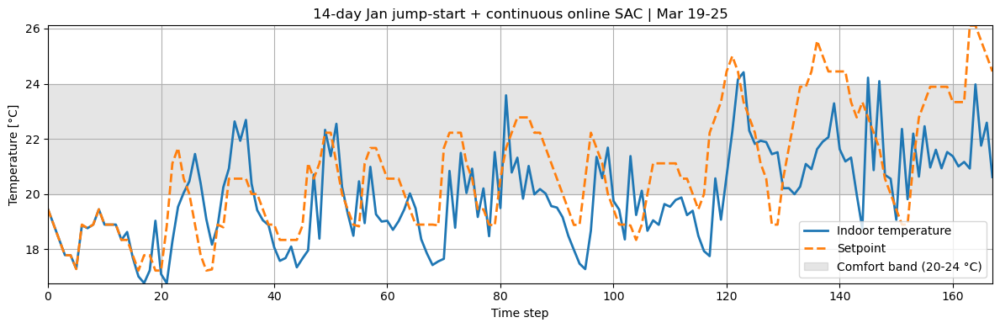

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 26-31 | reward: -502.11771502091506
                                    cost_function     value  \
0                           all_time_peak_average  0.948406   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.046883   
5                              daily_peak_average  0.975670   
6                   discomfort_cold_delta_average  1.290921   
7                   discomfort_cold_delta_maximum  4.237862   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.288732   
10                   discomfort_hot_delta_average  0.189547   
11                   discomfort_hot_delta_maximum  4.016739   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.028169   
1

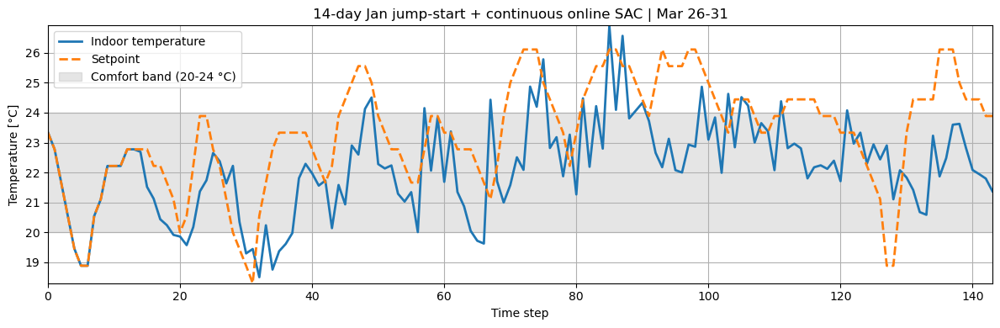

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full March eval after online learning: -2488.6267760905757
                                    cost_function     value  \
0                           all_time_peak_average  0.968131   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.084727   
5                              daily_peak_average  1.040671   
6                   discomfort_cold_delta_average  0.690184   
7                   discomfort_cold_delta_maximum  3.946360   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.132022   
10                   discomfort_hot_delta_average  0.686695   
11                   discomfort_hot_delta_maximum  7.655670   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.147472

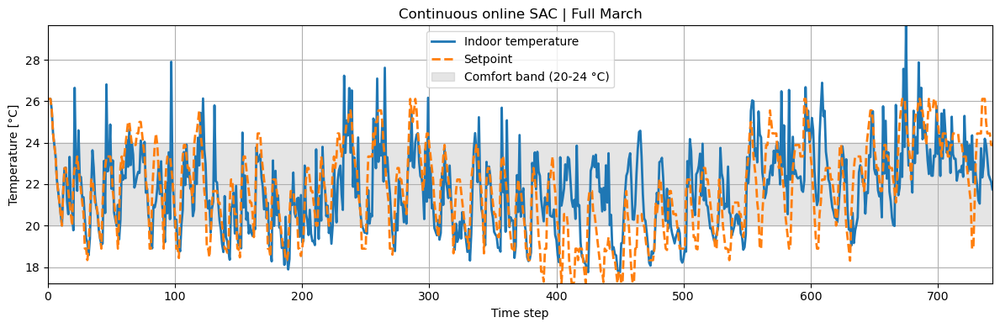

,week_idx,week_label,week_start,week_end,online_steps,auto_ent_before_update,auto_ent_after_update,eval_reward_after_update,replay_size_after_update
0,1,Jan 15-21,336,503,168,0.819816,0.781224,-3119.672898,503
1,2,Jan 22-28,504,671,168,0.781224,0.753596,-17894.511370,671
2,3,Jan 29 - Feb 4,672,839,168,0.753596,0.740315,-19638.938097,839
3,4,Feb 5-11,840,1007,168,0.740315,0.725631,-6458.252283,1007
4,5,Feb 12-18,1008,1175,168,0.725631,0.697434,-2091.618752,1175
5,6,Feb 19-25,1176,1343,168,0.697434,0.673863,-618.536145,1343
6,7,Feb 26 - Mar 4,1344,1511,168,0.673863,0.659105,-412.170931,1511
7,8,Mar 5-11,1512,1679,168,0.659105,0.650705,-395.625133,1679
8,9,Mar 12-18,1680,1847,168,0.650705,0.660245,-431.559985,1847
9,10,Mar 19-25,1848,2015,168,0.660245,0.664974,-582.949150,2015


,month,month_start,month_end,eval_reward,replay_size_after_update
0,February,744,1415,-2272.630272,1511
1,March,1416,2159,-2488.626776,2158


Saved continuous-online checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off800_continuous_online_mar
Saved continuous-online replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off800_continuous_online_mar_replay.pkl


In [92]:
# 7) January offline seed -> continuous online SAC through end of March (weekly evals)
MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

# --- Tunable experiment knobs ---
EXPERIMENT_OFFLINE_DAYS = 14
EXPERIMENT_OFFLINE_GRADIENT_STEPS = 800
EXPERIMENT_WEEK_DAYS = 7
EXPERIMENT_FORCE_REBUILD = True
EXPERIMENT_PROGRESS_BAR = False

# experiment_label = f"jan{EXPERIMENT_OFFLINE_DAYS}d_off{EXPERIMENT_OFFLINE_GRADIENT_STEPS}_continuous_online_mar"
# experiment_dataset_path = NOTEBOOK_DIR / f"{experiment_label}_pi_dataset_comfort_raw.npz"
# experiment_ckpt_path = NOTEBOOK_DIR / f"sac_{experiment_label}"
# experiment_replay_path = NOTEBOOK_DIR / f"sac_{experiment_label}_replay.pkl"

experiment_label = f"jan{EXPERIMENT_OFFLINE_DAYS}d_off{EXPERIMENT_OFFLINE_GRADIENT_STEPS}_continuous_online_mar_mpc"
experiment_source_dataset_path = NOTEBOOK_DIR / "january_mpc_dataset_comfort_raw.npz"
experiment_dataset_path = NOTEBOOK_DIR / f"{experiment_label}_seed_dataset_comfort_raw.npz"
experiment_ckpt_path = NOTEBOOK_DIR / f"sac_{experiment_label}"
experiment_replay_path = NOTEBOOK_DIR / f"sac_{experiment_label}_replay.pkl"

offline_seed_start = JAN_START
offline_seed_end = min(JAN_END, offline_seed_start + EXPERIMENT_OFFLINE_DAYS * 24 - 1)
online_start = offline_seed_end + 1
online_end = MAR_END

if online_start > online_end:
    raise ValueError("Online start is after the requested March end window.")

MONTH_LABELS = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec",
}

def step_to_month_day(step):
    for month, (start, end) in MONTH_TO_RANGE.items():
        if start <= step <= end:
            day = int((step - start) // 24 + 1)
            return MONTH_LABELS.get(month, str(month)), day
    raise ValueError(f"Step {step} is outside MONTH_TO_RANGE.")

def format_window_label(start, end):
    start_month, start_day = step_to_month_day(start)
    end_month, end_day = step_to_month_day(end)
    if start_month == end_month:
        return f"{start_month} {start_day}-{end_day}"
    return f"{start_month} {start_day} - {end_month} {end_day}"

def current_auto_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

# seed_env, seed_dataset, seed_dataset_mode = build_pi_period_dataset(
#     offline_seed_start,
#     offline_seed_end,
#     experiment_dataset_path,
#     force_rebuild=EXPERIMENT_FORCE_REBUILD,
# )

if not experiment_source_dataset_path.exists():
    raise FileNotFoundError(
        f"Missing MPC January dataset at {experiment_source_dataset_path}. "
        "Run the January learned-MPC rollout cell in my_mpc.ipynb first."
    )

seed_transition_start = int(offline_seed_start - JAN_START)
seed_transition_stop = int(offline_seed_end - JAN_START)

if seed_transition_start < 0:
    raise ValueError("Offline seed window must start within January.")

if EXPERIMENT_FORCE_REBUILD or not experiment_dataset_path.exists():
    full_mpc_npz = np.load(experiment_source_dataset_path)
    full_mpc_dataset = {key: np.asarray(full_mpc_npz[key]) for key in full_mpc_npz.files}

    if seed_transition_stop > len(full_mpc_dataset["states"]):
        raise ValueError(
            f"Requested offline seed stop {seed_transition_stop} exceeds MPC dataset length "
            f"{len(full_mpc_dataset['states'])}."
        )

    seed_dataset = {
        key: np.asarray(value[seed_transition_start:seed_transition_stop])
        for key, value in full_mpc_dataset.items()
    }
    np.savez_compressed(experiment_dataset_path, **seed_dataset)
    seed_dataset_mode = f"derived_from_{experiment_source_dataset_path.name}"
else:
    derived_seed_npz = np.load(experiment_dataset_path)
    seed_dataset = {key: np.asarray(derived_seed_npz[key]) for key in derived_seed_npz.files}
    seed_dataset_mode = "loaded_existing"

print("Experiment label:", experiment_label)
print("Offline seed window:", format_window_label(offline_seed_start, offline_seed_end), (offline_seed_start, offline_seed_end))
print("Online deployment window:", format_window_label(online_start, online_end), (online_start, online_end))
print("Offline MPC source dataset path:", experiment_source_dataset_path)
print("Offline MPC seed dataset mode:", seed_dataset_mode)
print("Offline MPC seed dataset path:", experiment_dataset_path)

seed_train_env = make_period_env(offline_seed_start, offline_seed_end)
REFERENCE_OBSERVATION_SPACE = seed_train_env.observation_space
REFERENCE_ACTION_SPACE = seed_train_env.action_space

# Use the default SB3 SAC hyperparameters here; only the seed/verbosity are pinned.
seasonal_model = SAC(
    policy="MlpPolicy",
    env=seed_train_env,
    seed=RANDOM_SEED,
    verbose=1,
)
seasonal_model._setup_learn(total_timesteps=1)

offline_replay_size = prefill_replay_buffer_from_npz(seasonal_model, experiment_dataset_path)
print(f"Offline replay buffer size: {offline_replay_size}")
print(f"Offline gradient updates: {EXPERIMENT_OFFLINE_GRADIENT_STEPS}")

for _ in tqdm(range(EXPERIMENT_OFFLINE_GRADIENT_STEPS), desc="Offline seed SAC updates"):
    seasonal_model.train(batch_size=seasonal_model.batch_size, gradient_steps=1)

seasonal_model.save(str(experiment_ckpt_path))
seasonal_model.save_replay_buffer(str(experiment_replay_path))
print(f"Saved offline seed checkpoint: {experiment_ckpt_path}")
print(f"Saved offline seed replay: {experiment_replay_path}")

seed_eval_env, seed_eval_reward, seed_eval_kpis = rollout_and_kpis(
    seasonal_model,
    offline_seed_start,
    offline_seed_end,
)
print("Offline seed reward:", seed_eval_reward)
print("Offline seed KPIs:")
print(seed_eval_kpis)
plot_comfort(seed_eval_env, title=f"Offline MPC seed policy | {format_window_label(offline_seed_start, offline_seed_end)}")

# Match the old online SAC setup: keep one continuous env and continue learn() across calls.
online_env = make_period_env(online_start, online_end)
seasonal_model.set_env(online_env)
seasonal_model.learning_starts = 0

weekly_results = []
monthly_results = []
feb_logged = False
mar_logged = False

for week_idx, week_start in enumerate(range(online_start, online_end + 1, EXPERIMENT_WEEK_DAYS * 24), start=1):
    week_end = min(online_end, week_start + EXPERIMENT_WEEK_DAYS * 24 - 1)
    week_label = format_window_label(week_start, week_end)
    is_last_week = week_end >= online_end
    # Because online_env is continuous and does not reset between learn() calls,
    # each non-final chunk must also consume the boundary transition into the next week.
    week_online_steps = int(week_end - week_start + (0 if is_last_week else 1))

    ent_before = current_auto_ent_coef(seasonal_model)
    if week_online_steps > 0:
        seasonal_model.learn(
            total_timesteps=week_online_steps,
            reset_num_timesteps=False,
            progress_bar=EXPERIMENT_PROGRESS_BAR,
        )
    ent_after = current_auto_ent_coef(seasonal_model)

    week_eval_env, week_eval_reward, week_eval_kpis = rollout_and_kpis(
        seasonal_model,
        week_start,
        week_end,
    )

    print(f"Weekly eval | {week_label} | reward: {week_eval_reward}")
    print(week_eval_kpis)
    plot_comfort(
        week_eval_env,
        title=f"{EXPERIMENT_OFFLINE_DAYS}-day Jan jump-start + continuous online SAC | {week_label}",
    )

    weekly_results.append({
        "week_idx": week_idx,
        "week_label": week_label,
        "week_start": week_start,
        "week_end": week_end,
        "online_steps": week_online_steps,
        "auto_ent_before_update": ent_before,
        "auto_ent_after_update": ent_after,
        "eval_reward_after_update": float(week_eval_reward),
        "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
    })

    if not feb_logged and online_start <= FEB_START and week_end >= FEB_END:
        feb_eval_env, feb_eval_reward, feb_eval_kpis = rollout_and_kpis(
            seasonal_model,
            FEB_START,
            FEB_END,
        )
        print("Full February eval after online learning:", feb_eval_reward)
        print(feb_eval_kpis)
        plot_comfort(feb_eval_env, title="Continuous online SAC | Full February")
        monthly_results.append({
            "month": "February",
            "month_start": FEB_START,
            "month_end": FEB_END,
            "eval_reward": float(feb_eval_reward),
            "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
        })
        feb_logged = True

    if not mar_logged and week_end >= MAR_END:
        mar_eval_env, mar_eval_reward, mar_eval_kpis = rollout_and_kpis(
            seasonal_model,
            MAR_START,
            MAR_END,
        )
        print("Full March eval after online learning:", mar_eval_reward)
        print(mar_eval_kpis)
        plot_comfort(mar_eval_env, title="Continuous online SAC | Full March")
        monthly_results.append({
            "month": "March",
            "month_start": MAR_START,
            "month_end": MAR_END,
            "eval_reward": float(mar_eval_reward),
            "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
        })
        mar_logged = True

weekly_df = pd.DataFrame(weekly_results)
display(weekly_df)

monthly_df = pd.DataFrame(monthly_results)
display(monthly_df)

seasonal_model.save(str(experiment_ckpt_path))
seasonal_model.save_replay_buffer(str(experiment_replay_path))
print(f"Saved continuous-online checkpoint: {experiment_ckpt_path}")
print(f"Saved continuous-online replay: {experiment_replay_path}")


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Dataset saved to: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/jan14d_off1500_continuous_online_mar_pi_pi_dataset_comfort_raw.npz
Experiment label: jan14d_off1500_continuous_online_mar_pi
Offline seed window: Jan 1-14 (0, 335)
Online deployment window: Jan 15 - Mar 31 (336, 2159)
Offline PI seed dataset mode: rebuilt
Offline PI seed dataset path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/jan14d_off1500_continuous_online_mar_pi_pi_dataset_comfort_raw.npz


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Offline replay buffer size: 335
Offline gradient updates: 1500


Offline seed SAC updates: 100%|██████████| 1500/1500 [00:07<00:00, 201.90it/s]


Saved offline seed checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off1500_continuous_online_mar_pi
Saved offline seed replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off1500_continuous_online_mar_pi_replay.pkl


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Offline seed reward: -3241.670667830682
Offline seed KPIs:
                                    cost_function     value  \
0                           all_time_peak_average  0.929223   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.954560   
5                              daily_peak_average  0.986385   
6                   discomfort_cold_delta_average  1.342727   
7                   discomfort_cold_delta_maximum  9.889220   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.271605   
10                   discomfort_hot_delta_average  0.933223   
11                   discomfort_hot_delta_maximum  5.760014   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.216049

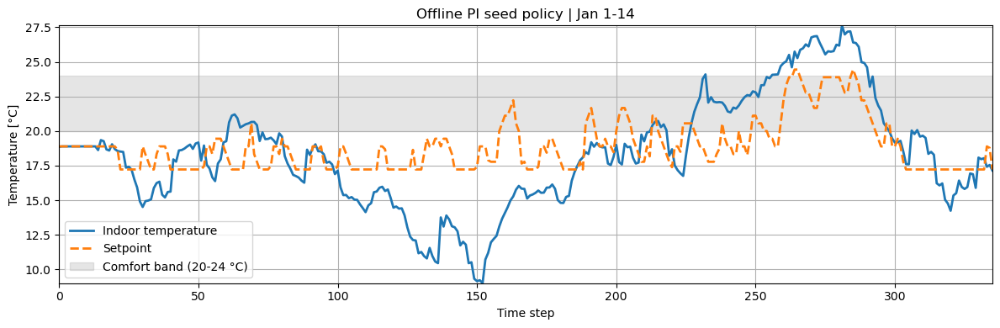

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 15-21 | reward: -4409.742720692001
                                    cost_function      value  \
0                           all_time_peak_average   0.954042   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.128360   
5                              daily_peak_average   0.925589   
6                   discomfort_cold_delta_average   4.174503   
7                   discomfort_cold_delta_maximum  10.717607   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.748466   
10                   discomfort_hot_delta_average   0.004349   
11                   discomfort_hot_delta_maximum   0.656237   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion  

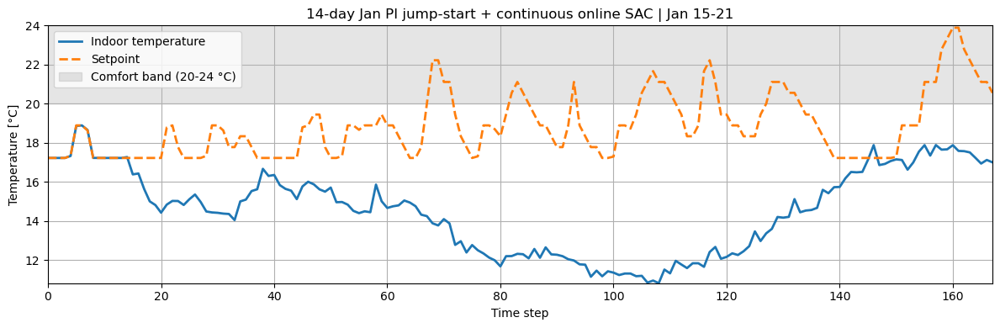

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 22-28 | reward: -16065.290353672364
                                    cost_function      value  \
0                           all_time_peak_average   0.910035   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.249565   
5                              daily_peak_average   0.804287   
6                   discomfort_cold_delta_average   8.105473   
7                   discomfort_cold_delta_maximum  16.016781   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.892405   
10                   discomfort_hot_delta_average   0.001733   
11                   discomfort_hot_delta_maximum   0.262094   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_proportion 

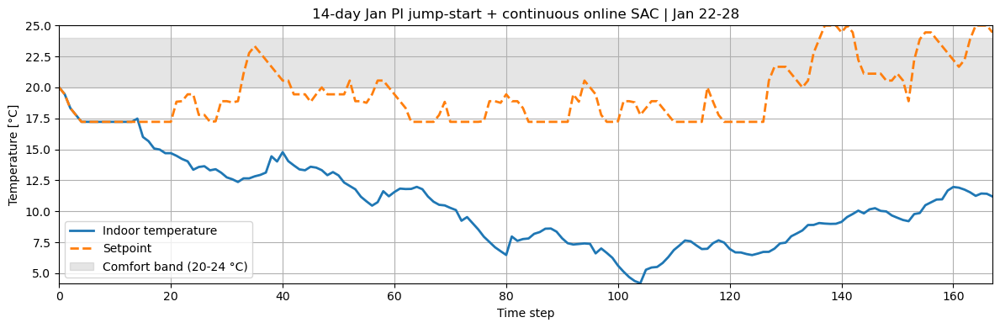

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Jan 29 - Feb 4 | reward: -15397.190274482695
                                    cost_function      value  \
0                           all_time_peak_average   1.000000   
1         annual_normalized_unserved_energy_total   0.000000   
2                          carbon_emissions_total        NaN   
3                                      cost_total        NaN   
4             daily_one_minus_load_factor_average   1.256360   
5                              daily_peak_average   0.860526   
6                   discomfort_cold_delta_average   7.621596   
7                   discomfort_cold_delta_maximum  18.091446   
8                   discomfort_cold_delta_minimum   0.000000   
9                      discomfort_cold_proportion   0.857143   
10                   discomfort_hot_delta_average   0.000706   
11                   discomfort_hot_delta_maximum   0.027727   
12                   discomfort_hot_delta_minimum   0.000000   
13                      discomfort_hot_propor

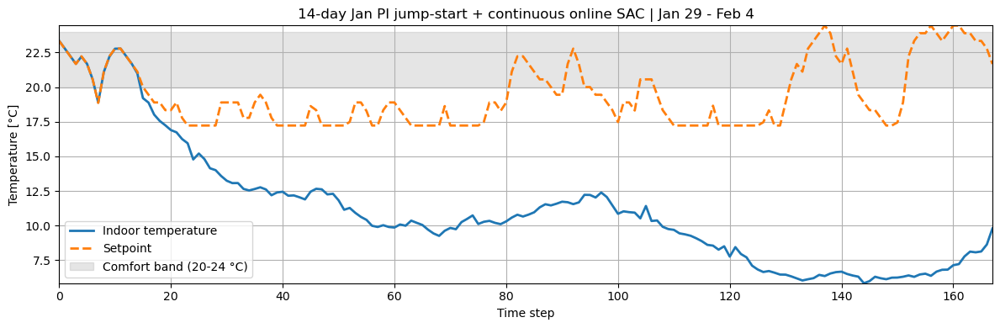

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 5-11 | reward: -1977.198543616144
                                    cost_function     value  \
0                           all_time_peak_average  0.913953   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.050546   
5                              daily_peak_average  0.868841   
6                   discomfort_cold_delta_average  2.816114   
7                   discomfort_cold_delta_maximum  7.654894   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.622754   
10                   discomfort_hot_delta_average  0.029547   
11                   discomfort_hot_delta_maximum  1.364542   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.000000   
14 

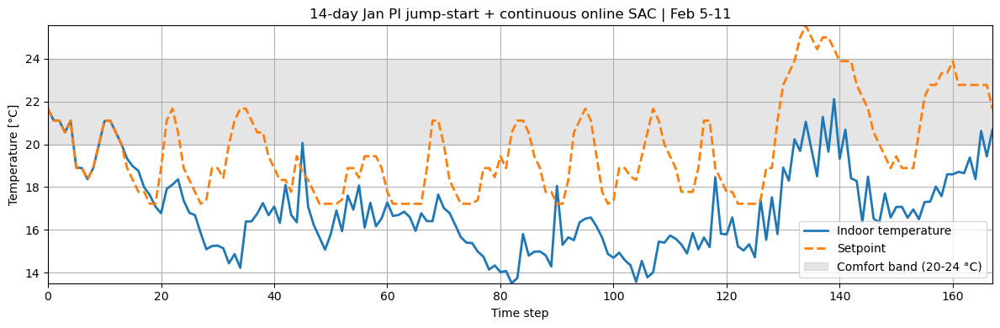

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 12-18 | reward: -538.2055767162437
                                    cost_function     value  \
0                           all_time_peak_average  0.882358   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.072247   
5                              daily_peak_average  0.961783   
6                   discomfort_cold_delta_average  1.330317   
7                   discomfort_cold_delta_maximum  4.276012   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.290909   
10                   discomfort_hot_delta_average  0.067147   
11                   discomfort_hot_delta_maximum  1.428680   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.000000   
14

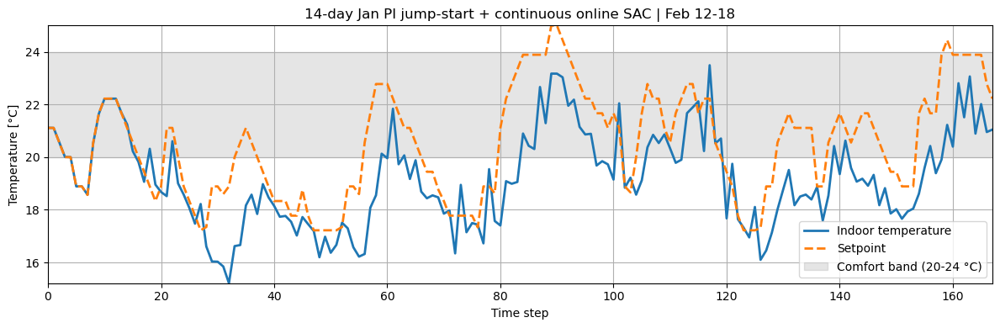

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 19-25 | reward: -339.91385483083286
                                    cost_function     value  \
0                           all_time_peak_average  1.028253   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.095530   
5                              daily_peak_average  1.011274   
6                   discomfort_cold_delta_average  0.621062   
7                   discomfort_cold_delta_maximum  4.222637   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.111111   
10                   discomfort_hot_delta_average  0.383450   
11                   discomfort_hot_delta_maximum  3.536131   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.061728   
1

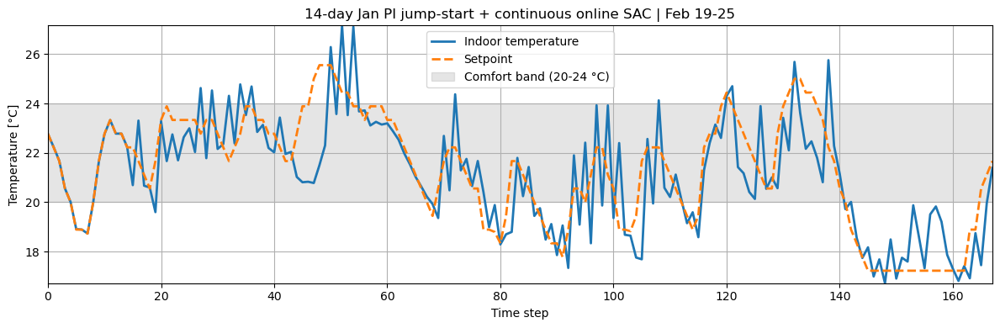

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Feb 26 - Mar 4 | reward: -472.54934440991565
                                    cost_function     value  \
0                           all_time_peak_average  1.097423   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.134833   
5                              daily_peak_average  1.019620   
6                   discomfort_cold_delta_average  0.721589   
7                   discomfort_cold_delta_maximum  4.770103   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.137500   
10                   discomfort_hot_delta_average  0.463605   
11                   discomfort_hot_delta_maximum  4.490568   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.087500

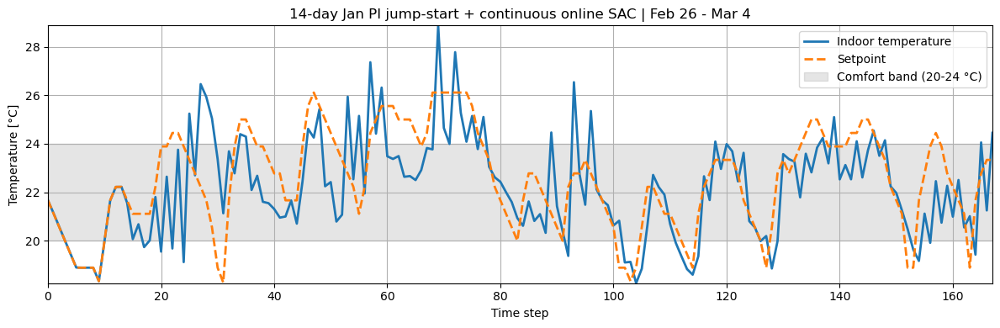

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full February eval after online learning: -3061.6967671639977
                                    cost_function     value  \
0                           all_time_peak_average  0.944985   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.150652   
5                              daily_peak_average  1.117304   
6                   discomfort_cold_delta_average  0.522212   
7                   discomfort_cold_delta_maximum  4.307365   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.070229   
10                   discomfort_hot_delta_average  1.014780   
11                   discomfort_hot_delta_maximum  8.344242   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.213

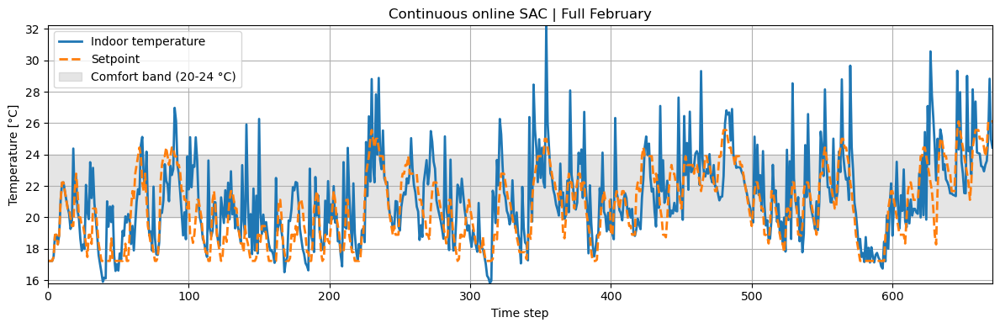

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 5-11 | reward: -564.712580396972
                                    cost_function     value  \
0                           all_time_peak_average  0.810902   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.052650   
5                              daily_peak_average  0.943321   
6                   discomfort_cold_delta_average  0.435783   
7                   discomfort_cold_delta_maximum  3.086838   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.050000   
10                   discomfort_hot_delta_average  0.911342   
11                   discomfort_hot_delta_maximum  5.572008   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.187500   
14  

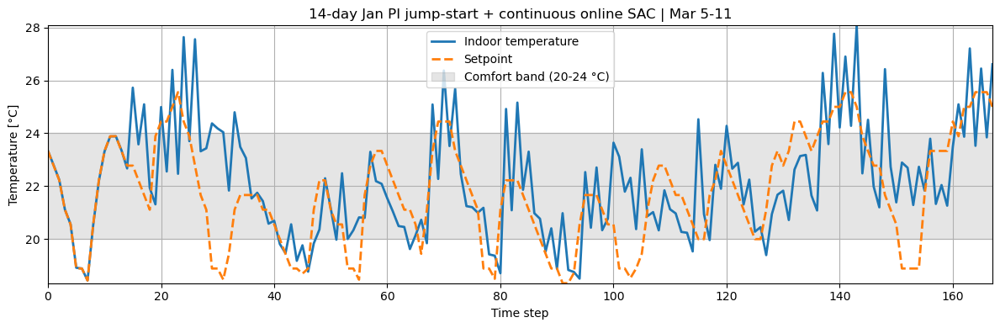

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 12-18 | reward: -392.637482970531
                                    cost_function         value  \
0                           all_time_peak_average  7.679302e-01   
1         annual_normalized_unserved_energy_total  6.476999e-10   
2                          carbon_emissions_total           NaN   
3                                      cost_total           NaN   
4             daily_one_minus_load_factor_average  1.024266e+00   
5                              daily_peak_average  8.979884e-01   
6                   discomfort_cold_delta_average  5.924935e-01   
7                   discomfort_cold_delta_maximum  3.539879e+00   
8                   discomfort_cold_delta_minimum  0.000000e+00   
9                      discomfort_cold_proportion  9.937888e-02   
10                   discomfort_hot_delta_average  5.833691e-01   
11                   discomfort_hot_delta_maximum  4.127172e+00   
12                   discomfort_hot_delta_minimum  0.000000e+00   
13        

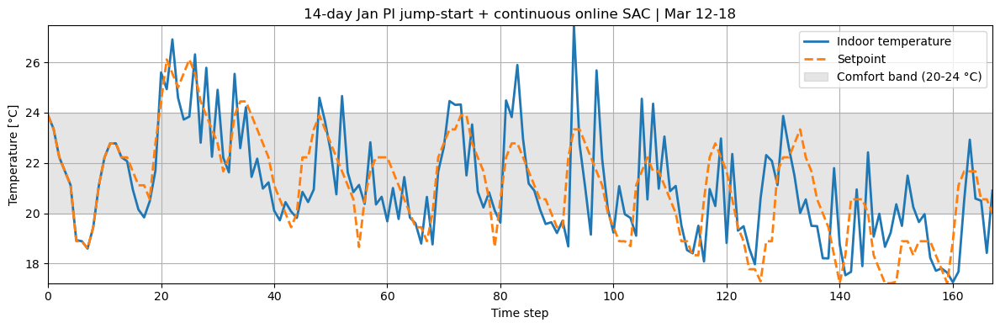

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 19-25 | reward: -697.9476238559146
                                    cost_function     value  \
0                           all_time_peak_average  0.964277   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.046474   
5                              daily_peak_average  0.982641   
6                   discomfort_cold_delta_average  0.905385   
7                   discomfort_cold_delta_maximum  4.188475   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.223602   
10                   discomfort_hot_delta_average  0.711295   
11                   discomfort_hot_delta_maximum  6.848377   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.161491   
14

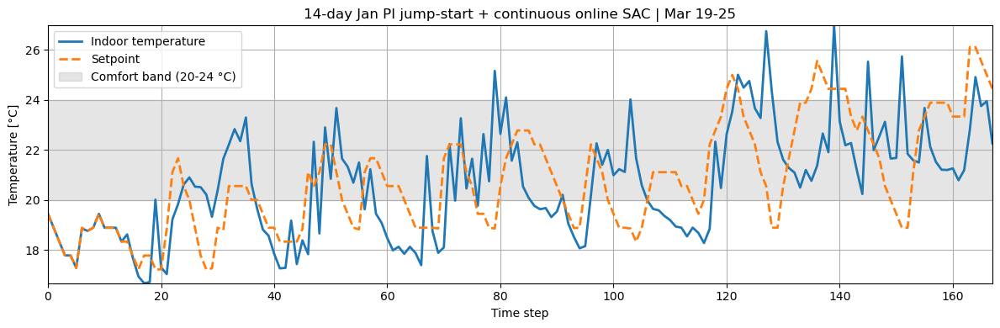

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Weekly eval | Mar 26-31 | reward: -450.25017670858506
                                    cost_function     value  \
0                           all_time_peak_average  0.975308   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.112734   
5                              daily_peak_average  1.018918   
6                   discomfort_cold_delta_average  1.125619   
7                   discomfort_cold_delta_maximum  4.438658   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.218310   
10                   discomfort_hot_delta_average  0.297626   
11                   discomfort_hot_delta_maximum  4.906364   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.049296   
1

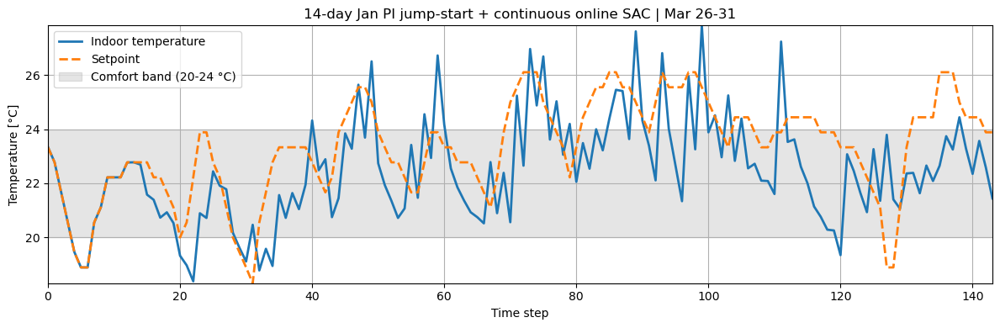

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Full March eval after online learning: -2461.46331028409
                                    cost_function     value  \
0                           all_time_peak_average  0.864269   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.118425   
5                              daily_peak_average  1.029209   
6                   discomfort_cold_delta_average  0.749435   
7                   discomfort_cold_delta_maximum  4.811129   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.127809   
10                   discomfort_hot_delta_average  0.604932   
11                   discomfort_hot_delta_maximum  7.938223   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.108146  

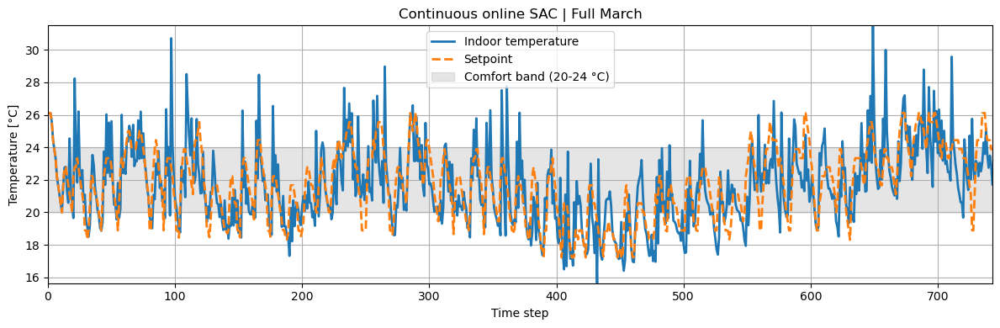

,week_idx,week_label,week_start,week_end,online_steps,auto_ent_before_update,auto_ent_after_update,eval_reward_after_update,replay_size_after_update
0,1,Jan 15-21,336,503,168,0.666732,0.635367,-4409.742721,503
1,2,Jan 22-28,504,671,168,0.635367,0.625366,-16065.290354,671
2,3,Jan 29 - Feb 4,672,839,168,0.625366,0.623630,-15397.190274,839
3,4,Feb 5-11,840,1007,168,0.623630,0.610361,-1977.198544,1007
4,5,Feb 12-18,1008,1175,168,0.610361,0.598710,-538.205577,1175
5,6,Feb 19-25,1176,1343,168,0.598710,0.600465,-339.913855,1343
6,7,Feb 26 - Mar 4,1344,1511,168,0.600465,0.613023,-472.549344,1511
7,8,Mar 5-11,1512,1679,168,0.613023,0.628567,-564.712580,1679
8,9,Mar 12-18,1680,1847,168,0.628567,0.654900,-392.637483,1847
9,10,Mar 19-25,1848,2015,168,0.654900,0.678262,-697.947624,2015


,month,month_start,month_end,eval_reward,replay_size_after_update
0,February,744,1415,-3061.696767,1511
1,March,1416,2159,-2461.463310,2158


Saved continuous-online checkpoint: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off1500_continuous_online_mar_pi
Saved continuous-online replay: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks/sac_jan14d_off1500_continuous_online_mar_pi_replay.pkl


In [27]:
# 7b) January PI offline seed -> continuous online SAC through end of March (weekly evals)
MAR_MONTH = 3
MAR_START, MAR_END = MONTH_TO_RANGE[MAR_MONTH]

# --- Tunable experiment knobs ---
EXPERIMENT_OFFLINE_DAYS = 14
EXPERIMENT_OFFLINE_GRADIENT_STEPS = 1500
EXPERIMENT_WEEK_DAYS = 7
EXPERIMENT_FORCE_REBUILD = True
EXPERIMENT_PROGRESS_BAR = False

experiment_label = f"jan{EXPERIMENT_OFFLINE_DAYS}d_off{EXPERIMENT_OFFLINE_GRADIENT_STEPS}_continuous_online_mar_pi"
experiment_dataset_path = NOTEBOOK_DIR / f"{experiment_label}_pi_dataset_comfort_raw.npz"
experiment_ckpt_path = NOTEBOOK_DIR / f"sac_{experiment_label}"
experiment_replay_path = NOTEBOOK_DIR / f"sac_{experiment_label}_replay.pkl"

offline_seed_start = JAN_START
offline_seed_end = min(JAN_END, offline_seed_start + EXPERIMENT_OFFLINE_DAYS * 24 - 1)
online_start = offline_seed_end + 1
online_end = MAR_END

if online_start > online_end:
    raise ValueError("Online start is after the requested March end window.")

MONTH_LABELS = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec",
}

def step_to_month_day(step):
    for month, (start, end) in MONTH_TO_RANGE.items():
        if start <= step <= end:
            day = int((step - start) // 24 + 1)
            return MONTH_LABELS.get(month, str(month)), day
    raise ValueError(f"Step {step} is outside MONTH_TO_RANGE.")

def format_window_label(start, end):
    start_month, start_day = step_to_month_day(start)
    end_month, end_day = step_to_month_day(end)
    if start_month == end_month:
        return f"{start_month} {start_day}-{end_day}"
    return f"{start_month} {start_day} - {end_month} {end_day}"

def current_auto_ent_coef(model):
    if hasattr(model, "log_ent_coef") and model.log_ent_coef is not None:
        return float(model.log_ent_coef.detach().exp().cpu().item())
    if hasattr(model, "ent_coef_tensor") and model.ent_coef_tensor is not None:
        return float(model.ent_coef_tensor.detach().cpu().item())
    return None

seed_env, seed_dataset, seed_dataset_mode = build_pi_period_dataset(
    offline_seed_start,
    offline_seed_end,
    experiment_dataset_path,
    force_rebuild=EXPERIMENT_FORCE_REBUILD,
)

print("Experiment label:", experiment_label)
print("Offline seed window:", format_window_label(offline_seed_start, offline_seed_end), (offline_seed_start, offline_seed_end))
print("Online deployment window:", format_window_label(online_start, online_end), (online_start, online_end))
print("Offline PI seed dataset mode:", seed_dataset_mode)
print("Offline PI seed dataset path:", experiment_dataset_path)

seed_train_env = make_period_env(offline_seed_start, offline_seed_end)
REFERENCE_OBSERVATION_SPACE = seed_train_env.observation_space
REFERENCE_ACTION_SPACE = seed_train_env.action_space

# Use the default SB3 SAC hyperparameters here; only the seed/verbosity are pinned.
seasonal_model = SAC(
    policy="MlpPolicy",
    env=seed_train_env,
    seed=RANDOM_SEED,
    verbose=1,
)
seasonal_model._setup_learn(total_timesteps=1)

offline_replay_size = prefill_replay_buffer_from_npz(seasonal_model, experiment_dataset_path)
print(f"Offline replay buffer size: {offline_replay_size}")
print(f"Offline gradient updates: {EXPERIMENT_OFFLINE_GRADIENT_STEPS}")

for _ in tqdm(range(EXPERIMENT_OFFLINE_GRADIENT_STEPS), desc="Offline seed SAC updates"):
    seasonal_model.train(batch_size=seasonal_model.batch_size, gradient_steps=1)

seasonal_model.save(str(experiment_ckpt_path))
seasonal_model.save_replay_buffer(str(experiment_replay_path))
print(f"Saved offline seed checkpoint: {experiment_ckpt_path}")
print(f"Saved offline seed replay: {experiment_replay_path}")

seed_eval_env, seed_eval_reward, seed_eval_kpis = rollout_and_kpis(
    seasonal_model,
    offline_seed_start,
    offline_seed_end,
)
print("Offline seed reward:", seed_eval_reward)
print("Offline seed KPIs:")
print(seed_eval_kpis)
plot_comfort(seed_eval_env, title=f"Offline PI seed policy | {format_window_label(offline_seed_start, offline_seed_end)}")

# Match the old online SAC setup: keep one continuous env and continue learn() across calls.
online_env = make_period_env(online_start, online_end)
seasonal_model.set_env(online_env)
seasonal_model.learning_starts = 0

weekly_results = []
monthly_results = []
feb_logged = False
mar_logged = False

for week_idx, week_start in enumerate(range(online_start, online_end + 1, EXPERIMENT_WEEK_DAYS * 24), start=1):
    week_end = min(online_end, week_start + EXPERIMENT_WEEK_DAYS * 24 - 1)
    week_label = format_window_label(week_start, week_end)
    is_last_week = week_end >= online_end
    # Because online_env is continuous and does not reset between learn() calls,
    # each non-final chunk must also consume the boundary transition into the next week.
    week_online_steps = int(week_end - week_start + (0 if is_last_week else 1))

    ent_before = current_auto_ent_coef(seasonal_model)
    if week_online_steps > 0:
        seasonal_model.learn(
            total_timesteps=week_online_steps,
            reset_num_timesteps=False,
            progress_bar=EXPERIMENT_PROGRESS_BAR,
        )
    ent_after = current_auto_ent_coef(seasonal_model)

    week_eval_env, week_eval_reward, week_eval_kpis = rollout_and_kpis(
        seasonal_model,
        week_start,
        week_end,
    )

    print(f"Weekly eval | {week_label} | reward: {week_eval_reward}")
    print(week_eval_kpis)
    plot_comfort(
        week_eval_env,
        title=f"{EXPERIMENT_OFFLINE_DAYS}-day Jan PI jump-start + continuous online SAC | {week_label}",
    )

    weekly_results.append({
        "week_idx": week_idx,
        "week_label": week_label,
        "week_start": week_start,
        "week_end": week_end,
        "online_steps": week_online_steps,
        "auto_ent_before_update": ent_before,
        "auto_ent_after_update": ent_after,
        "eval_reward_after_update": float(week_eval_reward),
        "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
    })

    if not feb_logged and online_start <= FEB_START and week_end >= FEB_END:
        feb_eval_env, feb_eval_reward, feb_eval_kpis = rollout_and_kpis(
            seasonal_model,
            FEB_START,
            FEB_END,
        )
        print("Full February eval after online learning:", feb_eval_reward)
        print(feb_eval_kpis)
        plot_comfort(feb_eval_env, title="Continuous online SAC | Full February")
        monthly_results.append({
            "month": "February",
            "month_start": FEB_START,
            "month_end": FEB_END,
            "eval_reward": float(feb_eval_reward),
            "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
        })
        feb_logged = True

    if not mar_logged and week_end >= MAR_END:
        mar_eval_env, mar_eval_reward, mar_eval_kpis = rollout_and_kpis(
            seasonal_model,
            MAR_START,
            MAR_END,
        )
        print("Full March eval after online learning:", mar_eval_reward)
        print(mar_eval_kpis)
        plot_comfort(mar_eval_env, title="Continuous online SAC | Full March")
        monthly_results.append({
            "month": "March",
            "month_start": MAR_START,
            "month_end": MAR_END,
            "eval_reward": float(mar_eval_reward),
            "replay_size_after_update": int(seasonal_model.replay_buffer.size()),
        })
        mar_logged = True

weekly_df = pd.DataFrame(weekly_results)
display(weekly_df)

monthly_df = pd.DataFrame(monthly_results)
display(monthly_df)

seasonal_model.save(str(experiment_ckpt_path))
seasonal_model.save_replay_buffer(str(experiment_replay_path))
print(f"Saved continuous-online checkpoint: {experiment_ckpt_path}")
print(f"Saved continuous-online replay: {experiment_replay_path}")


## SAC Occupant Stress Test

Train SAC from scratch for 120 repeated January episodes with each occupant active, then evaluate on a fresh February month and compare overrides against a February PI baseline.


In [18]:
# 8) SAC repeated-January occupant stress test helpers

from collections import deque
from copy import deepcopy
from stable_baselines3 import SAC
import gymnasium as gym

if 'Occupant' not in globals():
    class Occupant:
        def __init__(self, T_pref, b, max_prob=0.4, duration=3):
            self.T_pref = T_pref
            self.b = b
            self.max_prob = max_prob
            self.duration = duration
            self.override_timer = 0
            self.override_setpoint = None
            self.last_override_started = False

        def prob_increase(self, Tin):
            delta = max(0.0, self.T_pref - Tin)
            return min(0.002 * np.exp(self.b * delta), self.max_prob)

        def prob_decrease(self, Tin):
            delta = max(0.0, Tin - self.T_pref)
            return min(0.002 * np.exp(self.b * delta), self.max_prob)

        def override_delta(self, p_override):
            if p_override < 0.2:
                return 0.5
            if p_override < 0.4:
                return 1.0
            return 2.0

        def step(self, Tin, scheduled_Tsp):
            self.last_override_started = False

            if self.override_timer > 0:
                self.override_timer -= 1
                return self.override_setpoint

            p_inc = self.prob_increase(Tin)
            p_dec = self.prob_decrease(Tin)
            r = np.random.rand()

            if r < p_inc:
                new_sp = scheduled_Tsp + self.override_delta(p_inc)
            elif r < p_inc + p_dec:
                new_sp = scheduled_Tsp - self.override_delta(p_dec)
            else:
                self.override_setpoint = None
                return scheduled_Tsp

            self.override_setpoint = new_sp
            self.override_timer = max(self.duration - 1, 0)
            self.last_override_started = True
            return new_sp

from collections import deque
import numpy as np
from citylearn.reward_function import RewardFunction


class CurrentOccupantFeedbackReward(RewardFunction):
    """
    Paper-aligned reward:

        C_t^total = beta * C_t^discomfort + (1 - beta) * C_t^energy
        r_t = - C_t^total

    Discomfort cost:
        - if occupied and current feedback != 0:
              weighted sum of recent |feedback| values
        - if occupied and current feedback == 0:
              -epsilon
        - if unoccupied:
              0

    Notes:
    - The current feedback is appended BEFORE computing discomfort,
      so a fresh override is penalized immediately.
    - Energy cost is implemented using HVAC electricity consumption,
      normalized by nominal power, since that is what is directly
      available in CityLearn observations.
    """

    def __init__(
        self,
        env_metadata,
        beta=0.75,
        epsilon=0.05,
        feedback_horizon=4,
    ):
        super().__init__(env_metadata)
        self.beta = float(beta)
        self.epsilon = float(epsilon)
        self.feedback_horizon = int(feedback_horizon)

        self.feedback_buffers = []
        self.energy_scales = []

        if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])

        self.feedback_buffers = [
            deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
            for _ in range(n_buildings)
        ]

        self.energy_scales = []
        for i in range(n_buildings):
            building_metadata = self.env_metadata['buildings'][i]
            nominal_power = float(
                building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0
            )
            self.energy_scales.append(max(nominal_power, 1.0))

    def _discomfort_from_buffer(self, feedback_buffer):
        """
        Paper weighting:
            w_i = e - exp(i / h_f)

        We apply it from most recent to oldest.
        If h_f = H and the buffer contains:
            [oldest, ..., newest]
        then newest gets lag = 0, next lag = 1, etc.
        """
        discomfort = 0.0
        H = max(1, self.feedback_horizon)

        for lag, feedback in enumerate(reversed(feedback_buffer)):
            weight = np.e - np.exp((lag + 1) / H)
            discomfort += weight * abs(float(feedback))

        return float(discomfort)

    def calculate(self, observations):
        if len(self.feedback_buffers) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            feedback = float(o.get('occupant_feedback_signal', 0.0))
            occupied = float(o.get('occupant_count', 0.0)) > 0.0

            # Append first so current override is penalized immediately.
            self.feedback_buffers[i].append(feedback)

            if occupied and abs(feedback) > 0.0:
                discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
            elif occupied:
                discomfort_cost = -self.epsilon
            else:
                discomfort_cost = 0.0

            hvac_electricity = max(
                float(
                    o.get(
                        'heating_electricity_consumption',
                        o.get('net_electricity_consumption', 0.0)
                    )
                ),
                0.0,
            )

            energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
            energy_cost = hvac_electricity / max(energy_scale, 1.0)

            total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
            reward_list.append(-total_cost)

        if self.central_agent:
            return [sum(reward_list)]

        return reward_list

class OccupantSACWrapper(gym.Wrapper):
    def __init__(self, env, occupant):
        super().__init__(env)
        self.observation_names = getattr(env, 'observation_names', None)
        self.shared_observations = getattr(env, 'shared_observations', [])
        self.occupant = occupant
        self.episode_override_history = []
        self.override_count = 0
        self.effective_setpoints = []
        self.baseline_setpoints = []

    def __getattr__(self, name):
        if name.startswith('__'):
            raise AttributeError(name)
        return getattr(self.env, name)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0
        self.effective_setpoints = []
        self.baseline_setpoints = []

        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation._indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step
        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])

        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1,
        )
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp)
        else:
            self.occupant.override_timer = 0
            self.occupant.override_setpoint = None
            self.occupant.last_override_started = False
            new_Tsp = scheduled_next_Tsp

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0

        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        if terminated or truncated:
            self.episode_override_history.append(int(self.override_count))

        return obs, reward, terminated, truncated, info

def plot_comfort(
    env: CityLearnEnv,
    building_idx: int = 0,
    T_low: float = 20.0,
    T_high: float = 24.0,
    title: str = None
):
    b = env.unwrapped.buildings[building_idx]

    T_in = np.array(b.indoor_dry_bulb_temperature)

    if hasattr(env, "effective_setpoints") and len(env.effective_setpoints) > 0:
        T_sp = np.array(env.effective_setpoints)
    else:
        T_sp = np.array(b.indoor_dry_bulb_temperature_heating_set_point)

    if hasattr(env, "baseline_setpoints") and len(env.baseline_setpoints) > 0:
        T_sp_base = np.array(env.baseline_setpoints)
    else:
        T_sp_base = np.array(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[:len(T_in)])

    timesteps = np.arange(len(T_in))

    plt.figure(figsize=(12, 4))
    plt.plot(timesteps, T_in, label='Indoor temperature', linewidth=2)
    plt.plot(timesteps, T_sp_base, ':', label='Baseline schedule', linewidth=1.8, color='gray')
    plt.plot(timesteps, T_sp, '--', label='Effective setpoint', linewidth=2)

    plt.fill_between(
        timesteps,
        T_low,
        T_high,
        color='gray',
        alpha=0.2,
        label=f'Comfort band ({T_low:.0f}-{T_high:.0f} °C)'
    )

    plt.xlabel('Time step')
    plt.ylabel('Temperature [°C]')
    plt.title(title or b.name)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def _scalar_reward(reward):
    reward_arr = np.asarray(reward, dtype=np.float32).reshape(-1)
    return float(reward_arr[0])

def _district_metric(kpis, cost_name):
    rows = kpis[(kpis['level'] == 'district') & (kpis['cost_function'] == cost_name)]['value']
    return float(rows.iloc[0]) if len(rows) > 0 else np.nan

def make_occ_sac_env(start, end, occupant, normalize_obs=True, seed=None):
    env = make_env(
        reward_function=CurrentOccupantFeedbackReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )
    occ_env = OccupantSACWrapper(env, deepcopy(occupant))
    rl_env = occ_env

    if normalize_obs:
        rl_env = NormalizedObservationWrapper(rl_env)

    rl_env = StableBaselines3Wrapper(rl_env)
    return occ_env, rl_env

def rollout_sb3_env(model, rl_env, deterministic=True, seed=None):
    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, _ = rl_env.reset(seed=seed)
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=deterministic)
        obs, reward, terminated, truncated, _ = rl_env.step(action)
        reward_sum += _scalar_reward(reward)

    return reward_sum

def rollout_pi_occ_baseline(start, end, occupant, seed=None):
    env = make_env(
        reward_function=CurrentOccupantFeedbackReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )
    occ_env = OccupantSACWrapper(env, deepcopy(occupant))
    controller = PITemperatureController(occ_env)

    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, _ = occ_env.reset(seed=seed)
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action = controller.predict(obs)
        obs, reward, terminated, truncated, _ = occ_env.step(action)
        reward_sum += _scalar_reward(reward)

    return occ_env, reward_sum

JAN_START_SAC = SIMULATION_START_TIME_STEP
JAN_END_SAC = SIMULATION_END_TIME_STEP
JAN_STEPS_SAC = JAN_END_SAC - JAN_START_SAC + 1
FEB_START_SAC = JAN_END_SAC + 1
FEB_END_SAC = FEB_START_SAC + JAN_STEPS_SAC - 1
SAC_OCCUPANT_EPISODES = 50

SAC_OCCUPANT_SPECS = {
    'occ1_tolerant': Occupant(T_pref=22, b=1.2, max_prob=0.4),
    'occ2_sensitive': Occupant(T_pref=23, b=3.5, max_prob=0.4),
    'occ3_cold': Occupant(T_pref=20, b=2.5, max_prob=0.4),
    'occ4_hot': Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

SAC_OCCUPANT_KWARGS = dict(
    policy='MlpPolicy',
    learning_starts=0,
    learning_rate=3e-4,
    batch_size=256,
    buffer_size=300_000,
    tau=0.005,
    gamma=0.99,
    train_freq=(1, 'step'),
    gradient_steps=1,
    ent_coef='auto_0.2',
    verbose=0,
)

print(f'January training window: {JAN_START_SAC}-{JAN_END_SAC} | steps={JAN_STEPS_SAC}')
print(f'February evaluation window: {FEB_START_SAC}-{FEB_END_SAC} | steps={JAN_STEPS_SAC}')


January training window: 0-743 | steps=744
February evaluation window: 744-1487 | steps=744


In [20]:
# 8) SAC repeated-January occupant stress test helpers

from collections import deque
from copy import deepcopy
from stable_baselines3 import SAC
import gymnasium as gym

if 'Occupant' not in globals():
    class Occupant:
        def __init__(self, T_pref, b, max_prob=0.4, duration=3):
            self.T_pref = T_pref
            self.b = b
            self.max_prob = max_prob
            self.duration = duration
            self.override_timer = 0
            self.override_setpoint = None
            self.last_override_started = False

        def prob_increase(self, Tin):
            delta = max(0.0, self.T_pref - Tin)
            return min(0.002 * np.exp(self.b * delta), self.max_prob)

        def prob_decrease(self, Tin):
            delta = max(0.0, Tin - self.T_pref)
            return min(0.002 * np.exp(self.b * delta), self.max_prob)

        def override_delta(self, p_override):
            if p_override < 0.2:
                return 0.5
            if p_override < 0.4:
                return 1.0
            return 2.0

        def step(self, Tin, scheduled_Tsp):
            self.last_override_started = False

            if self.override_timer > 0:
                self.override_timer -= 1
                return self.override_setpoint

            p_inc = self.prob_increase(Tin)
            p_dec = self.prob_decrease(Tin)
            r = np.random.rand()

            if r < p_inc:
                new_sp = scheduled_Tsp + self.override_delta(p_inc)
            elif r < p_inc + p_dec:
                new_sp = scheduled_Tsp - self.override_delta(p_dec)
            else:
                self.override_setpoint = None
                return scheduled_Tsp

            self.override_setpoint = new_sp
            self.override_timer = max(self.duration - 1, 0)
            self.last_override_started = True
            return new_sp

from collections import deque
import numpy as np
from citylearn.reward_function import RewardFunction


class CurrentOccupantFeedbackReward(RewardFunction):
    """
    Paper-aligned reward:

        C_t^total = beta * C_t^discomfort + (1 - beta) * C_t^energy
        r_t = - C_t^total

    Discomfort cost:
        - if occupied and current feedback != 0:
              weighted sum of recent |feedback| values
        - if occupied and current feedback == 0:
              -epsilon
        - if unoccupied:
              0

    Notes:
    - The current feedback is appended BEFORE computing discomfort,
      so a fresh override is penalized immediately.
    - Energy cost is implemented using HVAC electricity consumption,
      normalized by nominal power, since that is what is directly
      available in CityLearn observations.
    """

    def __init__(
        self,
        env_metadata,
        beta=0.75,
        epsilon=0.05,
        feedback_horizon=4,
    ):
        super().__init__(env_metadata)
        self.beta = float(beta)
        self.epsilon = float(epsilon)
        self.feedback_horizon = int(feedback_horizon)

        self.feedback_buffers = []
        self.energy_scales = []

        if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])

        self.feedback_buffers = [
            deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
            for _ in range(n_buildings)
        ]

        self.energy_scales = []
        for i in range(n_buildings):
            building_metadata = self.env_metadata['buildings'][i]
            nominal_power = float(
                building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0
            )
            self.energy_scales.append(max(nominal_power, 1.0))

    def _discomfort_from_buffer(self, feedback_buffer):
        """
        Paper weighting:
            w_i = e - exp(i / h_f)

        We apply it from most recent to oldest.
        If h_f = H and the buffer contains:
            [oldest, ..., newest]
        then newest gets lag = 0, next lag = 1, etc.
        """
        discomfort = 0.0
        H = max(1, self.feedback_horizon)

        for lag, feedback in enumerate(reversed(feedback_buffer)):
            weight = np.e - np.exp((lag + 1) / H)
            discomfort += weight * abs(float(feedback))

        return float(discomfort)

    def calculate(self, observations):
        if len(self.feedback_buffers) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            feedback = float(o.get('occupant_feedback_signal', 0.0))
            occupied = float(o.get('occupant_count', 0.0)) > 0.0

            # Append first so current override is penalized immediately.
            self.feedback_buffers[i].append(feedback)

            if occupied and abs(feedback) > 0.0:
                discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
            elif occupied:
                discomfort_cost = -self.epsilon
            else:
                discomfort_cost = 0.0

            hvac_electricity = max(
                float(
                    o.get(
                        'heating_electricity_consumption',
                        o.get('net_electricity_consumption', 0.0)
                    )
                ),
                0.0,
            )

            energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
            energy_cost = hvac_electricity / max(energy_scale, 1.0)

            total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
            reward_list.append(-total_cost)

        if self.central_agent:
            return [sum(reward_list)]

        return reward_list

class OccupantSACWrapper(gym.Wrapper):
    def __init__(self, env, occupant):
        super().__init__(env)
        self.observation_names = getattr(env, 'observation_names', None)
        self.shared_observations = getattr(env, 'shared_observations', [])
        self.occupant = occupant
        self.episode_override_history = []
        self.override_count = 0
        self.effective_setpoints = []
        self.baseline_setpoints = []

    def __getattr__(self, name):
        if name.startswith('__'):
            raise AttributeError(name)
        return getattr(self.env, name)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0
        self.effective_setpoints = []
        self.baseline_setpoints = []

        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation._indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step
        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])

        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1,
        )
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp)
        else:
            self.occupant.override_timer = 0
            self.occupant.override_setpoint = None
            self.occupant.last_override_started = False
            new_Tsp = scheduled_next_Tsp

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0

        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        if terminated or truncated:
            self.episode_override_history.append(int(self.override_count))

        return obs, reward, terminated, truncated, info

def plot_comfort(
    env: CityLearnEnv,
    building_idx: int = 0,
    T_low: float = 20.0,
    T_high: float = 24.0,
    title: str = None
):
    b = env.unwrapped.buildings[building_idx]

    T_in = np.array(b.indoor_dry_bulb_temperature)

    if hasattr(env, "effective_setpoints") and len(env.effective_setpoints) > 0:
        T_sp = np.array(env.effective_setpoints)
    else:
        T_sp = np.array(b.indoor_dry_bulb_temperature_heating_set_point)

    if hasattr(env, "baseline_setpoints") and len(env.baseline_setpoints) > 0:
        T_sp_base = np.array(env.baseline_setpoints)
    else:
        T_sp_base = np.array(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[:len(T_in)]
        )

    timesteps = np.arange(len(T_in))

    plt.figure(figsize=(12, 4))
    plt.plot(timesteps, T_in, label='Indoor temperature', linewidth=2)
    plt.plot(timesteps, T_sp_base, ':', label='Baseline schedule', linewidth=1.8, color='gray')
    plt.plot(timesteps, T_sp, '--', label='Effective setpoint', linewidth=2)

    plt.fill_between(
        timesteps,
        T_low,
        T_high,
        color='gray',
        alpha=0.2,
        label=f'Comfort band ({T_low:.0f}-{T_high:.0f} °C)'
    )

    plt.xlabel('Time step')
    plt.ylabel('Temperature [°C]')
    plt.title(title or b.name)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def _scalar_reward(reward):
    reward_arr = np.asarray(reward, dtype=np.float32).reshape(-1)
    return float(reward_arr[0])

def _district_metric(kpis, cost_name):
    rows = kpis[(kpis['level'] == 'district') & (kpis['cost_function'] == cost_name)]['value']
    return float(rows.iloc[0]) if len(rows) > 0 else np.nan

def make_occ_sac_env(start, end, occupant, normalize_obs=True, seed=None):
    env = make_env(
        reward_function=CurrentOccupantFeedbackReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )
    occ_env = OccupantSACWrapper(env, deepcopy(occupant))
    rl_env = occ_env

    if normalize_obs:
        rl_env = NormalizedObservationWrapper(rl_env)

    rl_env = StableBaselines3Wrapper(rl_env)
    return occ_env, rl_env

def rollout_sb3_env(model, rl_env, deterministic=True, seed=None):
    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, _ = rl_env.reset(seed=seed)
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=deterministic)
        obs, reward, terminated, truncated, _ = rl_env.step(action)
        reward_sum += _scalar_reward(reward)

    return reward_sum

def rollout_pi_occ_baseline(start, end, occupant, seed=None):
    env = make_env(
        reward_function=CurrentOccupantFeedbackReward,
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )
    occ_env = OccupantSACWrapper(env, deepcopy(occupant))
    controller = PITemperatureController(occ_env)

    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, _ = occ_env.reset(seed=seed)
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action = controller.predict(obs)
        obs, reward, terminated, truncated, _ = occ_env.step(action)
        reward_sum += _scalar_reward(reward)

    return occ_env, reward_sum

JAN_START_SAC = SIMULATION_START_TIME_STEP
JAN_END_SAC = SIMULATION_END_TIME_STEP
JAN_STEPS_SAC = JAN_END_SAC - JAN_START_SAC + 1

FEB_START_SAC = JAN_END_SAC + 1
FEB_END_SAC = FEB_START_SAC + JAN_STEPS_SAC - 1

# FIX 1: training window spans January + February, so the training episode length
# must also span January + February.
TRAIN_START_SAC = JAN_START_SAC
TRAIN_END_SAC = FEB_END_SAC
TRAIN_STEPS_SAC = TRAIN_END_SAC - TRAIN_START_SAC + 1

SAC_OCCUPANT_EPISODES = 10

SAC_OCCUPANT_SPECS = {
    'occ1_tolerant': Occupant(T_pref=22, b=1.2, max_prob=0.4),
    'occ2_sensitive': Occupant(T_pref=23, b=3.5, max_prob=0.4),
    'occ3_cold': Occupant(T_pref=20, b=2.5, max_prob=0.4),
    'occ4_hot': Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

SAC_OCCUPANT_KWARGS = dict(
    policy='MlpPolicy',
    learning_starts=0,
    # learning_rate=3e-4,
    batch_size=256,
    # buffer_size=300_000,
    # tau=0.005,
    # gamma=0.99,
    train_freq=(1, 'step'),
    gradient_steps=1,
    ent_coef='auto_0.2',
    verbose=0,
)

print(f'January window: {JAN_START_SAC}-{JAN_END_SAC} | steps={JAN_STEPS_SAC}')
print(f'February window: {FEB_START_SAC}-{FEB_END_SAC} | steps={JAN_STEPS_SAC}')
print(f'Training window (Jan+Feb): {TRAIN_START_SAC}-{TRAIN_END_SAC} | steps={TRAIN_STEPS_SAC}')

# 9) Run the 4-occupant January+February SAC sweep with February evaluation kept unchanged

sac_occupant_results = {}
sac_occupant_summary_rows = []

for occ_idx, (label, occupant) in enumerate(SAC_OCCUPANT_SPECS.items(), start=1):
    print(f"\n{'=' * 80}\n🔥 {label}\n{'=' * 80}")

    seed_local = int(RANDOM_SEED + occ_idx)
    np.random.seed(seed_local)
    random.seed(seed_local)

    train_occ_env, train_rl_env = make_occ_sac_env(
        TRAIN_START_SAC,
        TRAIN_END_SAC,
        occupant,
        normalize_obs=True,
        seed=seed_local,
    )

    model = SAC(
        env=train_rl_env,
        seed=seed_local,
        **SAC_OCCUPANT_KWARGS,
    )

    january_override_history = []

    for episode in range(1, SAC_OCCUPANT_EPISODES + 1):
        model.learn(
            total_timesteps=TRAIN_STEPS_SAC,
            reset_num_timesteps=False,
        )

        if len(train_occ_env.episode_override_history) < episode:
            raise RuntimeError(f'Episode {episode} finished but no override count was recorded for {label}.')

        overrides_ep = int(train_occ_env.episode_override_history[-1])
        january_override_history.append(overrides_ep)
        print(f'{label} | January+February episode {episode:03d}/{SAC_OCCUPANT_EPISODES} | overrides={overrides_ep}')

    plt.figure(figsize=(10, 3))
    plt.plot(np.arange(1, SAC_OCCUPANT_EPISODES + 1), january_override_history, linewidth=2)
    plt.xlabel('January+February training episode')
    plt.ylabel('Override count')
    plt.title(f'{label} | January+February override count during SAC training')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    np.random.seed(seed_local + 10_000)
    random.seed(seed_local + 10_000)
    feb_pi_env, feb_pi_reward = rollout_pi_occ_baseline(
        FEB_START_SAC,
        FEB_END_SAC,
        occupant,
        seed=seed_local + 10_000,
    )
    feb_pi_overrides = int(getattr(feb_pi_env, 'override_count', 0))
    print(f'{label} | February PI overrides={feb_pi_overrides} | reward={feb_pi_reward:.3f}')

    np.random.seed(seed_local + 10_000)
    random.seed(seed_local + 10_000)
    feb_sac_occ_env, feb_sac_rl_env = make_occ_sac_env(
        FEB_START_SAC,
        FEB_END_SAC,
        occupant,
        normalize_obs=True,
        seed=seed_local + 10_000,
    )
    feb_sac_reward = rollout_sb3_env(
        model,
        feb_sac_rl_env,
        deterministic=True,
        seed=seed_local + 10_000,
    )
    feb_sac_overrides = int(getattr(feb_sac_occ_env, 'override_count', 0))
    feb_kpis = feb_sac_occ_env.unwrapped.evaluate().copy()

    print(f'{label} | February SAC overrides={feb_sac_overrides} | reward={feb_sac_reward:.3f}')
    plot_comfort(feb_sac_occ_env, title=f'{label} | February SAC comfort')

    sac_occupant_results[label] = {
        'january_override_history': january_override_history,
        'feb_pi_overrides': feb_pi_overrides,
        'feb_pi_reward': float(feb_pi_reward),
        'feb_sac_overrides': feb_sac_overrides,
        'feb_sac_reward': float(feb_sac_reward),
        'feb_kpis': feb_kpis,
        'train_env': train_occ_env,
        'feb_pi_env': feb_pi_env,
        'feb_sac_env': feb_sac_occ_env,
    }

    sac_occupant_summary_rows.append({
        'occupant': label,
        'jan_ep1_overrides': int(january_override_history[0]),
        'jan_ep120_overrides': int(january_override_history[-1]),
        'jan_best_overrides': int(np.min(january_override_history)),
        'jan_last10_mean': float(np.mean(january_override_history[-10:])),
        'feb_pi_overrides': int(feb_pi_overrides),
        'feb_sac_overrides': int(feb_sac_overrides),
        'feb_override_delta_vs_pi': int(feb_sac_overrides - feb_pi_overrides),
        'feb_reward': float(feb_sac_reward),
        'electricity_consumption_total': _district_metric(feb_kpis, 'electricity_consumption_total'),
        'discomfort_proportion': _district_metric(feb_kpis, 'discomfort_proportion'),
        'discomfort_cold_proportion': _district_metric(feb_kpis, 'discomfort_cold_proportion'),
        'discomfort_hot_proportion': _district_metric(feb_kpis, 'discomfort_hot_proportion'),
        'daily_peak_average': _district_metric(feb_kpis, 'daily_peak_average'),
    })

sac_occupant_summary = pd.DataFrame(sac_occupant_summary_rows)
display(sac_occupant_summary)

January window: 0-743 | steps=744
February window: 744-1487 | steps=744
Training window (Jan+Feb): 0-1487 | steps=1488

🔥 occ1_tolerant


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

KeyboardInterrupt: 


🔥 occ1_tolerant | DynamicComfortReward


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ1_tolerant | Jan+Feb episode 001/10 | overrides=260
occ1_tolerant | Jan+Feb episode 002/10 | overrides=195
occ1_tolerant | Jan+Feb episode 003/10 | overrides=105
occ1_tolerant | Jan+Feb episode 004/10 | overrides=48
occ1_tolerant | Jan+Feb episode 005/10 | overrides=39
occ1_tolerant | Jan+Feb episode 006/10 | overrides=52
occ1_tolerant | Jan+Feb episode 007/10 | overrides=59
occ1_tolerant | Jan+Feb episode 008/10 | overrides=29
occ1_tolerant | Jan+Feb episode 009/10 | overrides=18
occ1_tolerant | Jan+Feb episode 010/10 | overrides=13


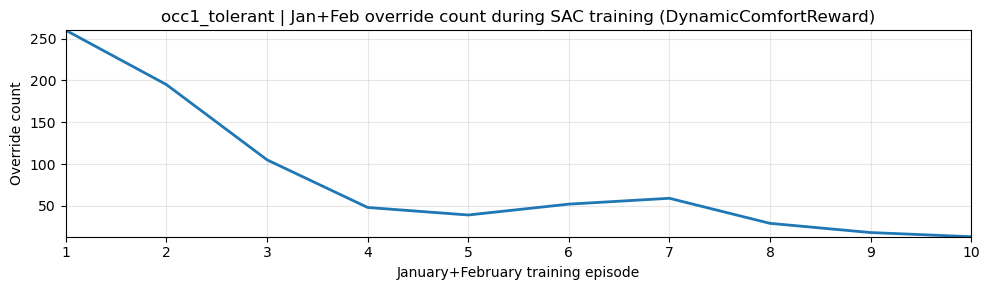

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ1_tolerant | February PI overrides=67 | reward=-18722.073


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ1_tolerant | February SAC overrides=9 | reward=-7422.051


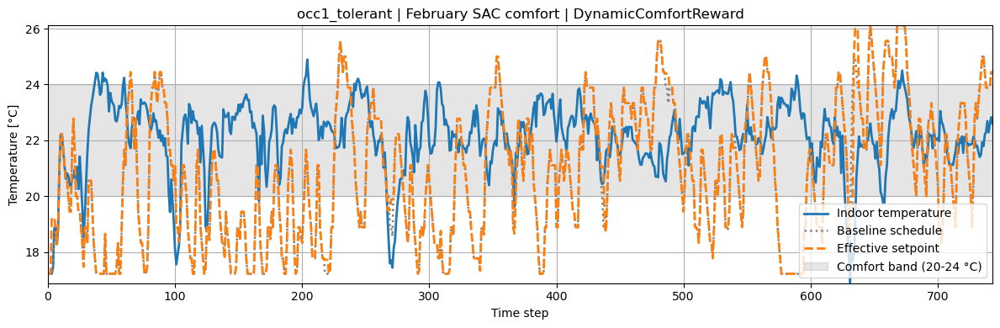


🔥 occ2_sensitive | DynamicComfortReward


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ2_sensitive | Jan+Feb episode 001/10 | overrides=297
occ2_sensitive | Jan+Feb episode 002/10 | overrides=247
occ2_sensitive | Jan+Feb episode 003/10 | overrides=188
occ2_sensitive | Jan+Feb episode 004/10 | overrides=199
occ2_sensitive | Jan+Feb episode 005/10 | overrides=237
occ2_sensitive | Jan+Feb episode 006/10 | overrides=175
occ2_sensitive | Jan+Feb episode 007/10 | overrides=146
occ2_sensitive | Jan+Feb episode 008/10 | overrides=161
occ2_sensitive | Jan+Feb episode 009/10 | overrides=138
occ2_sensitive | Jan+Feb episode 010/10 | overrides=132


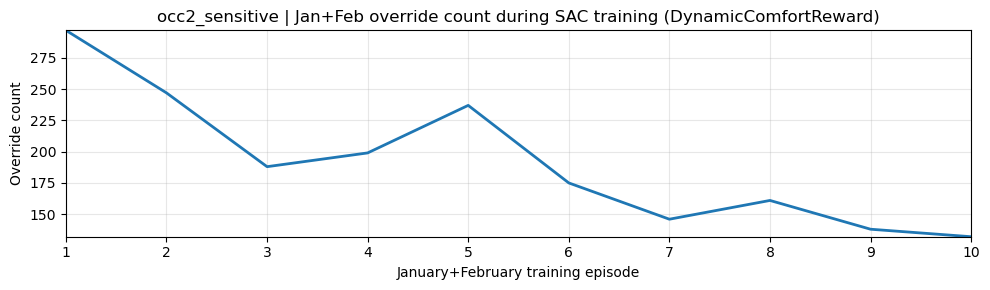

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ2_sensitive | February PI overrides=146 | reward=-19815.953


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ2_sensitive | February SAC overrides=79 | reward=-4580.263


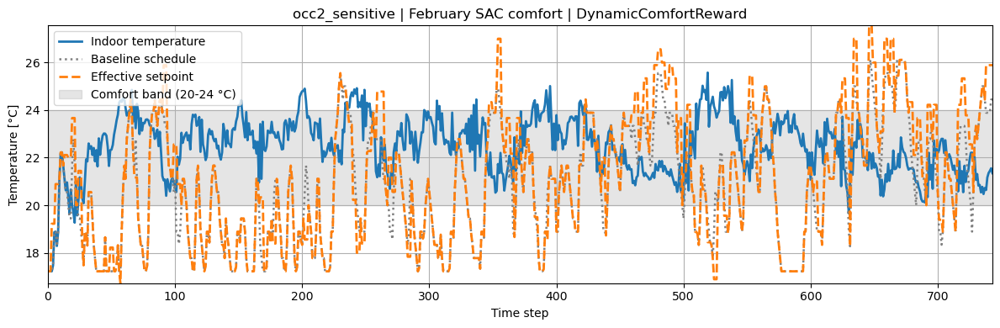


🔥 occ3_cold | DynamicComfortReward


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ3_cold | Jan+Feb episode 001/10 | overrides=236
occ3_cold | Jan+Feb episode 002/10 | overrides=119
occ3_cold | Jan+Feb episode 003/10 | overrides=120
occ3_cold | Jan+Feb episode 004/10 | overrides=71
occ3_cold | Jan+Feb episode 005/10 | overrides=64
occ3_cold | Jan+Feb episode 006/10 | overrides=92
occ3_cold | Jan+Feb episode 007/10 | overrides=113
occ3_cold | Jan+Feb episode 008/10 | overrides=108
occ3_cold | Jan+Feb episode 009/10 | overrides=100
occ3_cold | Jan+Feb episode 010/10 | overrides=83


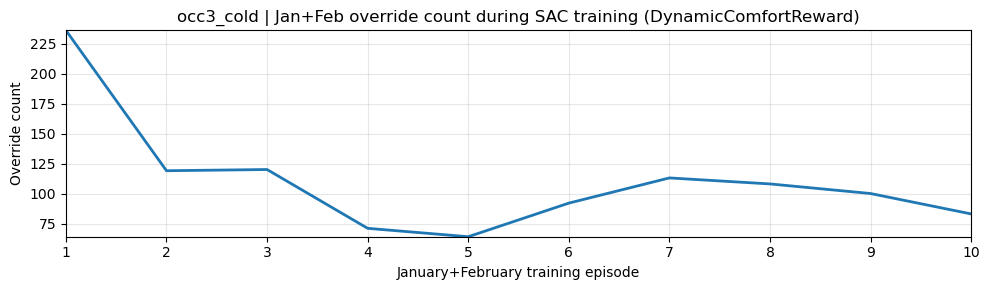

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ3_cold | February PI overrides=105 | reward=-13014.844


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ3_cold | February SAC overrides=33 | reward=-6981.257


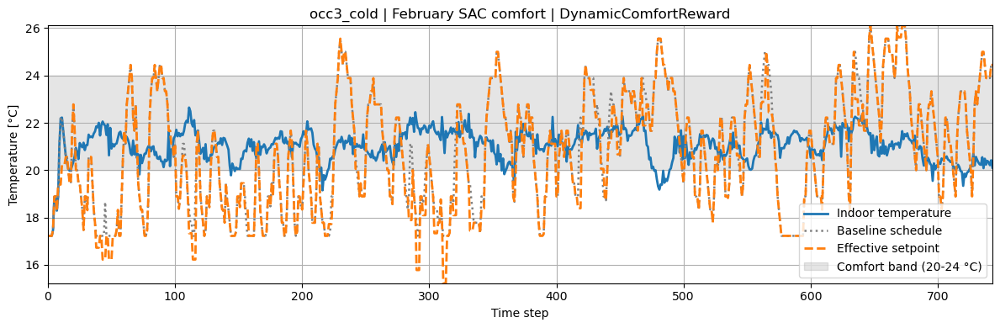


🔥 occ4_hot | DynamicComfortReward


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ4_hot | Jan+Feb episode 001/10 | overrides=299
occ4_hot | Jan+Feb episode 002/10 | overrides=252
occ4_hot | Jan+Feb episode 003/10 | overrides=215
occ4_hot | Jan+Feb episode 004/10 | overrides=189
occ4_hot | Jan+Feb episode 005/10 | overrides=179
occ4_hot | Jan+Feb episode 006/10 | overrides=178
occ4_hot | Jan+Feb episode 007/10 | overrides=165
occ4_hot | Jan+Feb episode 008/10 | overrides=148
occ4_hot | Jan+Feb episode 009/10 | overrides=148
occ4_hot | Jan+Feb episode 010/10 | overrides=141


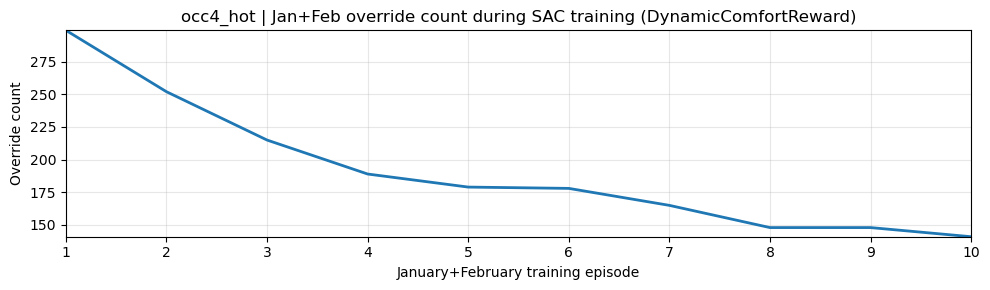

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ4_hot | February PI overrides=146 | reward=-18903.078


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

occ4_hot | February SAC overrides=64 | reward=-5310.988


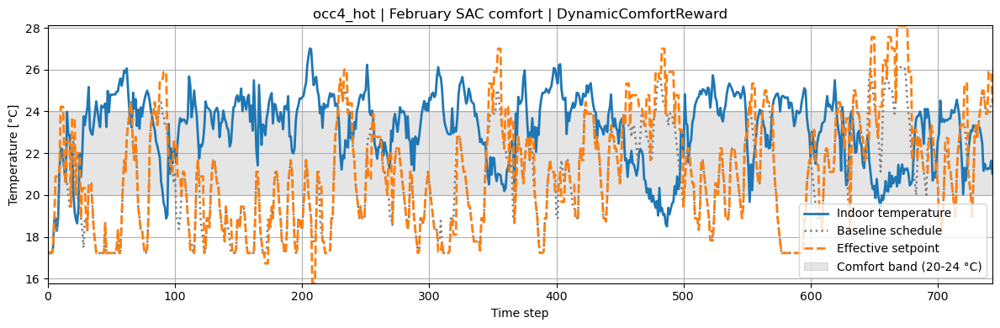

,occupant,jan_ep1_overrides,jan_ep_last_overrides,jan_best_overrides,jan_last10_mean,feb_pi_overrides,feb_sac_overrides,feb_override_delta_vs_pi,feb_reward,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,occ1_tolerant,260,13,13,81.8,67,9,-58,-7422.051018,1.099476,0.473684,0.103878,0.369806,1.040531
1,occ2_sensitive,297,132,132,192.0,146,79,-67,-4580.263489,1.110641,0.652355,0.198061,0.454294,1.068544
2,occ3_cold,236,83,64,110.6,105,33,-72,-6981.257288,1.016974,0.472299,0.198061,0.274238,1.003674
3,occ4_hot,299,141,141,191.4,146,64,-82,-5310.987843,1.167000,0.750693,0.189751,0.562327,1.110247


In [23]:
# 10) SAME SAC January+February sweep, but with DynamicComfortReward
# Drop-in cell. Assumes cells 8 and 9 already ran.

from typing import Any, List, Mapping, Union
from copy import deepcopy
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import gymnasium as gym
from stable_baselines3 import SAC
from citylearn.reward_function import ComfortReward

# ------------------------------------------------------------
# Fallbacks
# ------------------------------------------------------------
if 'RANDOM_SEED' not in globals():
    RANDOM_SEED = 42

if 'TRAIN_START_SAC' not in globals():
    TRAIN_START_SAC = JAN_START_SAC
if 'TRAIN_END_SAC' not in globals():
    TRAIN_END_SAC = FEB_END_SAC
if 'TRAIN_STEPS_SAC' not in globals():
    TRAIN_STEPS_SAC = TRAIN_END_SAC - TRAIN_START_SAC + 1

# ------------------------------------------------------------
# Dynamic comfort reward using persistent T_dyn
# ------------------------------------------------------------
class DynamicComfortReward(ComfortReward):
    """
    ComfortReward but with persistent T_dyn instead of the thermostat setpoint.

    T_dyn logic:
      - initialize from schedule or occupant T_pref
      - update only when occupant_feedback_signal is a NEW override event
      - warmer override -> T_dyn += delta_up
      - cooler override -> T_dyn -= delta_down
      - optional slow drift toward T_pref
    """

    def __init__(
        self,
        env_metadata: Mapping[str, Any],
        occupant=None,
        band: float = None,
        lower_exponent: float = None,
        higher_exponent: float = None,
        t_dyn_init_mode: str = "schedule",
        delta_up: float = 0.5,
        delta_down: float = 0.5,
        drift_to_pref: float = 0.0,
        t_dyn_min: float = 18.0,
        t_dyn_max: float = 26.0,
    ):
        super().__init__(
            env_metadata=env_metadata,
            band=band,
            lower_exponent=lower_exponent,
            higher_exponent=higher_exponent,
        )
        self.occupant = deepcopy(occupant)
        self.t_dyn_init_mode = t_dyn_init_mode
        self.delta_up = float(delta_up)
        self.delta_down = float(delta_down)
        self.drift_to_pref = float(drift_to_pref)
        self.t_dyn_min = float(t_dyn_min)
        self.t_dyn_max = float(t_dyn_max)

        self._t_dyn = None

        if self.env_metadata is not None and self.env_metadata.get("buildings") is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata["buildings"])
        self._t_dyn = [None] * n_buildings

    def _pref(self, default_sp: float) -> float:
        if self.occupant is None:
            return float(default_sp)
        return float(self.occupant.T_pref)

    def _init_t_dyn_if_needed(self, i: int, o: Mapping[str, Union[int, float]]):
        if self._t_dyn[i] is not None:
            return

        heating_sp = float(o.get("indoor_dry_bulb_temperature_heating_set_point", 21.0))
        if self.t_dyn_init_mode == "schedule":
            t_dyn = heating_sp
        elif self.t_dyn_init_mode == "pref":
            t_dyn = self._pref(heating_sp)
        else:
            raise ValueError("t_dyn_init_mode must be 'schedule' or 'pref'")

        self._t_dyn[i] = float(np.clip(t_dyn, self.t_dyn_min, self.t_dyn_max))

    def _update_t_dyn(self, i: int, o: Mapping[str, Union[int, float]]):
        self._init_t_dyn_if_needed(i, o)

        heating_sp = float(o.get("indoor_dry_bulb_temperature_heating_set_point", 21.0))
        t_pref = self._pref(heating_sp)

        if self.drift_to_pref > 0.0:
            self._t_dyn[i] = (1.0 - self.drift_to_pref) * self._t_dyn[i] + self.drift_to_pref * t_pref

        # In your wrappers, occupant_feedback_signal is only nonzero at NEW override starts.
        feedback = float(o.get("occupant_feedback_signal", 0.0))
        if feedback > 0.0:
            self._t_dyn[i] += self.delta_up
        elif feedback < 0.0:
            self._t_dyn[i] -= self.delta_down

        self._t_dyn[i] = float(np.clip(self._t_dyn[i], self.t_dyn_min, self.t_dyn_max))

    def calculate(self, observations: List[Mapping[str, Union[int, float]]]) -> List[float]:
        if self._t_dyn is None or len(self._t_dyn) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            self._update_t_dyn(i, o)

            heating_demand = float(o.get('heating_demand', 0.0))
            cooling_demand = float(o.get('cooling_demand', 0.0))
            heating = heating_demand > cooling_demand
            hvac_mode = int(o['hvac_mode'])
            indoor_dry_bulb_temperature = float(o['indoor_dry_bulb_temperature'])

            set_point = float(self._t_dyn[i])
            band = self.band if self.band is not None else float(o['comfort_band'])
            lower_bound = set_point - band
            upper_bound = set_point + band
            delta = abs(indoor_dry_bulb_temperature - set_point)

            if hvac_mode in [1, 2]:
                if indoor_dry_bulb_temperature < lower_bound:
                    exponent = self.lower_exponent if hvac_mode == 2 else self.higher_exponent
                    reward = -(delta**exponent)

                elif lower_bound <= indoor_dry_bulb_temperature < set_point:
                    reward = 0.0 if heating else -delta

                elif set_point <= indoor_dry_bulb_temperature <= upper_bound:
                    reward = -delta if heating else 0.0

                else:
                    exponent = self.higher_exponent if heating else self.lower_exponent
                    reward = -(delta**exponent)

            else:
                if indoor_dry_bulb_temperature < lower_bound:
                    exponent = self.lower_exponent if heating else self.higher_exponent
                    reward = -(delta**exponent)

                elif lower_bound <= indoor_dry_bulb_temperature <= upper_bound:
                    reward = 0.0

                else:
                    exponent = self.higher_exponent if heating else self.lower_exponent
                    reward = -(delta**exponent)

            reward_list.append(float(reward))

        if self.central_agent:
            return [sum(reward_list)]
        return reward_list


# ------------------------------------------------------------
# Wrapper with same override logic + plotting traces
# ------------------------------------------------------------
class OccupantSACWrapperDynamic(gym.Wrapper):
    def __init__(self, env, occupant):
        super().__init__(env)
        self.observation_names = getattr(env, 'observation_names', None)
        self.shared_observations = getattr(env, 'shared_observations', [])
        self.occupant = occupant
        self.episode_override_history = []
        self.override_count = 0
        self.effective_setpoints = []
        self.baseline_setpoints = []

    def __getattr__(self, name):
        if name.startswith('__'):
            raise AttributeError(name)
        return getattr(self.env, name)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0
        self.effective_setpoints = []
        self.baseline_setpoints = []

        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation._indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)

        self.effective_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])
        ]
        self.baseline_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])
        ]
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step
        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])

        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1,
        )
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp)
        else:
            self.occupant.override_timer = 0
            self.occupant.override_setpoint = None
            self.occupant.last_override_started = False
            new_Tsp = scheduled_next_Tsp

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0

        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)

        if terminated or truncated:
            self.episode_override_history.append(int(self.override_count))

        return obs, reward, terminated, truncated, info


# ------------------------------------------------------------
# Builders using reward_function_kwargs
# ------------------------------------------------------------
def make_occ_sac_env_dynamic_comfort(
    start,
    end,
    occupant,
    normalize_obs=True,
    seed=None,
    t_dyn_init_mode="schedule",
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,
    t_dyn_min=18.0,
    t_dyn_max=26.0,
):
    env = make_env(
        reward_function=DynamicComfortReward,
        reward_function_kwargs=dict(
            occupant=deepcopy(occupant),
            t_dyn_init_mode=t_dyn_init_mode,
            delta_up=delta_up,
            delta_down=delta_down,
            drift_to_pref=drift_to_pref,
            t_dyn_min=t_dyn_min,
            t_dyn_max=t_dyn_max,
        ),
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )

    occ_env = OccupantSACWrapperDynamic(env, deepcopy(occupant))
    rl_env = occ_env

    if normalize_obs:
        rl_env = NormalizedObservationWrapper(rl_env)

    rl_env = StableBaselines3Wrapper(rl_env)
    return occ_env, rl_env


def rollout_pi_occ_baseline_dynamic_comfort(
    start,
    end,
    occupant,
    seed=None,
    t_dyn_init_mode="schedule",
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,
    t_dyn_min=18.0,
    t_dyn_max=26.0,
):
    env = make_env(
        reward_function=DynamicComfortReward,
        reward_function_kwargs=dict(
            occupant=deepcopy(occupant),
            t_dyn_init_mode=t_dyn_init_mode,
            delta_up=delta_up,
            delta_down=delta_down,
            drift_to_pref=drift_to_pref,
            t_dyn_min=t_dyn_min,
            t_dyn_max=t_dyn_max,
        ),
        simulation_start_time_step=start,
        simulation_end_time_step=end,
        random_seed=RANDOM_SEED if seed is None else int(seed),
    )

    occ_env = OccupantSACWrapperDynamic(env, deepcopy(occupant))
    controller = PITemperatureController(occ_env)

    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, _ = occ_env.reset(seed=seed)
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action = controller.predict(obs)
        obs, reward, terminated, truncated, _ = occ_env.step(action)
        reward_sum += _scalar_reward(reward)

    return occ_env, reward_sum


# ------------------------------------------------------------
# SAME experiment, only reward changed
# ------------------------------------------------------------
DYNAMIC_COMFORT_KWARGS = dict(
    t_dyn_init_mode="schedule",
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,
    t_dyn_min=18.0,
    t_dyn_max=26.0,
)

sac_dynamic_comfort_results = {}
sac_dynamic_comfort_summary_rows = []

for occ_idx, (label, occupant) in enumerate(SAC_OCCUPANT_SPECS.items(), start=1):
    print(f"\n{'=' * 80}\n🔥 {label} | DynamicComfortReward\n{'=' * 80}")

    seed_local = int(RANDOM_SEED + occ_idx)
    np.random.seed(seed_local)
    random.seed(seed_local)

    train_occ_env, train_rl_env = make_occ_sac_env_dynamic_comfort(
        TRAIN_START_SAC,
        TRAIN_END_SAC,
        occupant,
        normalize_obs=True,
        seed=seed_local,
        **DYNAMIC_COMFORT_KWARGS,
    )

    model = SAC(
        env=train_rl_env,
        seed=seed_local,
        **SAC_OCCUPANT_KWARGS,
    )

    override_history = []

    for episode in range(1, SAC_OCCUPANT_EPISODES + 1):
        model.learn(
            total_timesteps=TRAIN_STEPS_SAC,
            reset_num_timesteps=False,
        )

        if len(train_occ_env.episode_override_history) < episode:
            raise RuntimeError(f'Episode {episode} finished but no override count was recorded for {label}.')

        overrides_ep = int(train_occ_env.episode_override_history[-1])
        override_history.append(overrides_ep)
        print(f'{label} | Jan+Feb episode {episode:03d}/{SAC_OCCUPANT_EPISODES} | overrides={overrides_ep}')

    plt.figure(figsize=(10, 3))
    plt.plot(np.arange(1, SAC_OCCUPANT_EPISODES + 1), override_history, linewidth=2)
    plt.xlabel('January+February training episode')
    plt.ylabel('Override count')
    plt.title(f'{label} | Jan+Feb override count during SAC training (DynamicComfortReward)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    np.random.seed(seed_local + 10_000)
    random.seed(seed_local + 10_000)
    feb_pi_env, feb_pi_reward = rollout_pi_occ_baseline_dynamic_comfort(
        FEB_START_SAC,
        FEB_END_SAC,
        occupant,
        seed=seed_local + 10_000,
        **DYNAMIC_COMFORT_KWARGS,
    )
    feb_pi_overrides = int(getattr(feb_pi_env, 'override_count', 0))
    print(f'{label} | February PI overrides={feb_pi_overrides} | reward={feb_pi_reward:.3f}')

    np.random.seed(seed_local + 10_000)
    random.seed(seed_local + 10_000)
    feb_sac_occ_env, feb_sac_rl_env = make_occ_sac_env_dynamic_comfort(
        FEB_START_SAC,
        FEB_END_SAC,
        occupant,
        normalize_obs=True,
        seed=seed_local + 10_000,
        **DYNAMIC_COMFORT_KWARGS,
    )
    feb_sac_reward = rollout_sb3_env(
        model,
        feb_sac_rl_env,
        deterministic=True,
        seed=seed_local + 10_000,
    )
    feb_sac_overrides = int(getattr(feb_sac_occ_env, 'override_count', 0))
    feb_kpis = feb_sac_occ_env.unwrapped.evaluate().copy()

    print(f'{label} | February SAC overrides={feb_sac_overrides} | reward={feb_sac_reward:.3f}')
    plot_comfort(feb_sac_occ_env, title=f'{label} | February SAC comfort | DynamicComfortReward')

    sac_dynamic_comfort_results[label] = {
        'override_history': override_history,
        'feb_pi_overrides': feb_pi_overrides,
        'feb_pi_reward': float(feb_pi_reward),
        'feb_sac_overrides': feb_sac_overrides,
        'feb_sac_reward': float(feb_sac_reward),
        'feb_kpis': feb_kpis,
        'train_env': train_occ_env,
        'feb_pi_env': feb_pi_env,
        'feb_sac_env': feb_sac_occ_env,
    }

    sac_dynamic_comfort_summary_rows.append({
        'occupant': label,
        'jan_ep1_overrides': int(override_history[0]),
        'jan_ep_last_overrides': int(override_history[-1]),
        'jan_best_overrides': int(np.min(override_history)),
        'jan_last10_mean': float(np.mean(override_history[-10:])),
        'feb_pi_overrides': int(feb_pi_overrides),
        'feb_sac_overrides': int(feb_sac_overrides),
        'feb_override_delta_vs_pi': int(feb_sac_overrides - feb_pi_overrides),
        'feb_reward': float(feb_sac_reward),
        'electricity_consumption_total': _district_metric(feb_kpis, 'electricity_consumption_total'),
        'discomfort_proportion': _district_metric(feb_kpis, 'discomfort_proportion'),
        'discomfort_cold_proportion': _district_metric(feb_kpis, 'discomfort_cold_proportion'),
        'discomfort_hot_proportion': _district_metric(feb_kpis, 'discomfort_hot_proportion'),
        'daily_peak_average': _district_metric(feb_kpis, 'daily_peak_average'),
    })

sac_dynamic_comfort_summary = pd.DataFrame(sac_dynamic_comfort_summary_rows)
display(sac_dynamic_comfort_summary)

In [22]:
# 9) Run the 4-occupant January SAC -> February transfer sweep

sac_occupant_results = {}
sac_occupant_summary_rows = []

for occ_idx, (label, occupant) in enumerate(SAC_OCCUPANT_SPECS.items(), start=1):
    print(f"\n{'=' * 80}\n🔥 {label}\n{'=' * 80}")

    seed_local = int(RANDOM_SEED + occ_idx)
    np.random.seed(seed_local)
    random.seed(seed_local)

    train_occ_env, train_rl_env = make_occ_sac_env(
        JAN_START_SAC,
        FEB_END_SAC,
        occupant,
        normalize_obs=True,
        seed=seed_local,
    )

    model = SAC(
        env=train_rl_env,
        seed=seed_local,
        **SAC_OCCUPANT_KWARGS,
    )

    january_override_history = []

    for episode in range(1, SAC_OCCUPANT_EPISODES + 1):
        model.learn(
            total_timesteps=JAN_STEPS_SAC,
            reset_num_timesteps=False,
        )

        if len(train_occ_env.episode_override_history) < episode:
            raise RuntimeError(f'Episode {episode} finished but no override count was recorded for {label}.')

        overrides_ep = int(train_occ_env.episode_override_history[-1])
        january_override_history.append(overrides_ep)
        print(f'{label} | January episode {episode:03d}/{SAC_OCCUPANT_EPISODES} | overrides={overrides_ep}')

    plt.figure(figsize=(10, 3))
    plt.plot(np.arange(1, SAC_OCCUPANT_EPISODES + 1), january_override_history, linewidth=2)
    plt.xlabel('January training episode')
    plt.ylabel('Override count')
    plt.title(f'{label} | January override count during SAC training')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    np.random.seed(seed_local + 10_000)
    random.seed(seed_local + 10_000)
    feb_pi_env, feb_pi_reward = rollout_pi_occ_baseline(
        FEB_START_SAC,
        FEB_END_SAC,
        occupant,
        seed=seed_local + 10_000,
    )
    feb_pi_overrides = int(getattr(feb_pi_env, 'override_count', 0))
    print(f'{label} | February PI overrides={feb_pi_overrides} | reward={feb_pi_reward:.3f}')

    np.random.seed(seed_local + 10_000)
    random.seed(seed_local + 10_000)
    feb_sac_occ_env, feb_sac_rl_env = make_occ_sac_env(
        FEB_START_SAC,
        FEB_END_SAC,
        occupant,
        normalize_obs=True,
        seed=seed_local + 10_000,
    )
    feb_sac_reward = rollout_sb3_env(
        model,
        feb_sac_rl_env,
        deterministic=True,
        seed=seed_local + 10_000,
    )
    feb_sac_overrides = int(getattr(feb_sac_occ_env, 'override_count', 0))
    feb_kpis = feb_sac_occ_env.unwrapped.evaluate().copy()

    print(f'{label} | February SAC overrides={feb_sac_overrides} | reward={feb_sac_reward:.3f}')
    plot_comfort(feb_sac_occ_env, title=f'{label} | February SAC comfort')

    sac_occupant_results[label] = {
        'january_override_history': january_override_history,
        'feb_pi_overrides': feb_pi_overrides,
        'feb_pi_reward': float(feb_pi_reward),
        'feb_sac_overrides': feb_sac_overrides,
        'feb_sac_reward': float(feb_sac_reward),
        'feb_kpis': feb_kpis,
        'train_env': train_occ_env,
        'feb_pi_env': feb_pi_env,
        'feb_sac_env': feb_sac_occ_env,
    }

    sac_occupant_summary_rows.append({
        'occupant': label,
        'jan_ep1_overrides': int(january_override_history[0]),
        'jan_ep120_overrides': int(january_override_history[-1]),
        'jan_best_overrides': int(np.min(january_override_history)),
        'jan_last10_mean': float(np.mean(january_override_history[-10:])),
        'feb_pi_overrides': int(feb_pi_overrides),
        'feb_sac_overrides': int(feb_sac_overrides),
        'feb_override_delta_vs_pi': int(feb_sac_overrides - feb_pi_overrides),
        'feb_reward': float(feb_sac_reward),
        'electricity_consumption_total': _district_metric(feb_kpis, 'electricity_consumption_total'),
        'discomfort_proportion': _district_metric(feb_kpis, 'discomfort_proportion'),
        'discomfort_cold_proportion': _district_metric(feb_kpis, 'discomfort_cold_proportion'),
        'discomfort_hot_proportion': _district_metric(feb_kpis, 'discomfort_hot_proportion'),
        'daily_peak_average': _district_metric(feb_kpis, 'daily_peak_average'),
    })

sac_occupant_summary = pd.DataFrame(sac_occupant_summary_rows)
display(sac_occupant_summary)



🔥 occ1_tolerant


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

RuntimeError: Episode 1 finished but no override count was recorded for occ1_tolerant.

## Occupant Bias MLP For Frozen DiffMPC

Train one supervised MLP per occupant on January PI rollout data, using
\(b_k^* = T^{eff}_{sp,k} - T^{sched}_{sp,k}\) as the target bias.


In [116]:
# 10) Occupant bias MLP helpers
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

BIAS_SHORT_TO_LONG = {
    'occ1': 'occ1_tolerant',
    'occ2': 'occ2_sensitive',
    'occ3': 'occ3_cold',
    'occ4': 'occ4_hot',
}
BIAS_LONG_TO_SHORT = {v: k for k, v in BIAS_SHORT_TO_LONG.items()}


@dataclass
class BiasFeatureConfig:
    history_len: int = 6
    bias_max: float = 2.0
    hidden_dim: int = 64
    num_hidden_layers: int = 2
    dropout: float = 0.0


class OccupantBiasMLP(nn.Module):
    def __init__(
        self,
        in_dim: int,
        hidden_dim: int = 64,
        num_hidden_layers: int = 2,
        dropout: float = 0.0,
        bias_max: float = 2.0,
    ):
        super().__init__()

        layers = []
        dim_prev = in_dim
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(dim_prev, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0.0:
                layers.append(nn.Dropout(dropout))
            dim_prev = hidden_dim

        layers.append(nn.Linear(dim_prev, 1))
        self.net = nn.Sequential(*layers)
        self.bias_max = float(bias_max)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        raw = self.net(z)
        return self.bias_max * torch.tanh(raw)


class BiasSupervisedDataset(Dataset):
    def __init__(self, df: pd.DataFrame, feature_cols: List[str], target_col: str = 'target_bias'):
        self.feature_cols = feature_cols
        self.target_col = target_col
        self.X = df[feature_cols].to_numpy(dtype=np.float32)
        self.y = df[target_col].to_numpy(dtype=np.float32).reshape(-1, 1)

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, idx: int):
        return {
            'x': torch.from_numpy(self.X[idx]),
            'y': torch.from_numpy(self.y[idx]),
        }


REQUIRED_COLUMNS = [
    'Tin',
    'scheduled_sp_raw',
    'effective_sp_observed',
    'Tout',
    'Solar',
]

BIAS_FEATURE_COLUMNS = [
    'Tin',
    'scheduled_sp_raw',
    'Tout',
    'Solar',
    'delta_t_sched',
    'u_prev',
    'u_mean_hist',
    'override_prev',
    'override_mean_hist',
    'discomfort_mean_hist',
    'hour_sin',
    'hour_cos',
]


def _hour_sin_cos_from_index(idx: int, steps_per_day: int = 24) -> Tuple[float, float]:
    hour = idx % steps_per_day
    angle = 2.0 * np.pi * float(hour) / float(steps_per_day)
    return float(np.sin(angle)), float(np.cos(angle))


def _safe_series(df: pd.DataFrame, col: str, default: float = 0.0) -> pd.Series:
    if col in df.columns:
        return df[col].astype(float)
    return pd.Series(np.full(len(df), default, dtype=np.float32), index=df.index)


def build_january_bias_rollout_dataframe(env, dataset) -> pd.DataFrame:
    b = env.unwrapped.buildings[0]

    Tin = np.asarray(b.energy_simulation.indoor_dry_bulb_temperature, dtype=np.float32)
    scheduled_sp_raw = np.asarray(
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control,
        dtype=np.float32,
    )
    effective_sp_observed = np.asarray(
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point,
        dtype=np.float32,
    )
    Tout = np.asarray(b.weather.outdoor_dry_bulb_temperature, dtype=np.float32)
    Solar = np.asarray(b.weather.direct_solar_irradiance, dtype=np.float32)
    override_signal = np.asarray(b.energy_simulation.occupant_feedback_signal, dtype=np.float32)

    actions = np.asarray(dataset['actions'], dtype=np.float32)
    if actions.ndim == 3:
        hp_action = actions[:, 0, 0]
    elif actions.ndim == 2:
        hp_action = actions[:, 0]
    else:
        hp_action = actions.reshape(-1)

    n = min(
        len(hp_action),
        len(Tin),
        len(scheduled_sp_raw),
        len(effective_sp_observed),
        len(Tout),
        len(Solar),
        len(override_signal),
    )

    df = pd.DataFrame({
        'Tin': Tin[:n],
        'scheduled_sp_raw': scheduled_sp_raw[:n],
        'effective_sp_observed': effective_sp_observed[:n],
        'Tout': Tout[:n],
        'Solar': Solar[:n],
        'hp_action': hp_action[:n],
        'override_dir': np.sign(override_signal[:n]).astype(np.float32),
        'override_flag': (np.abs(override_signal[:n]) > 0.0).astype(np.float32),
        'occupant_feedback_signal': override_signal[:n],
    })
    return df


def build_bias_training_dataframe(
    january_df: pd.DataFrame,
    history_len: int = 6,
    bias_max: float = 2.0,
    steps_per_day: int = 24,
) -> pd.DataFrame:
    missing = [c for c in REQUIRED_COLUMNS if c not in january_df.columns]
    if len(missing) > 0:
        raise ValueError(f'Missing required columns in january_df: {missing}')

    df = january_df.copy().reset_index(drop=True)
    df['hp_action'] = _safe_series(df, 'hp_action', default=0.0)

    if 'override_dir' in df.columns:
        df['override_signal'] = df['override_dir'].astype(float)
    elif 'override_flag' in df.columns:
        df['override_signal'] = df['override_flag'].astype(float)
    else:
        diff = df['effective_sp_observed'].astype(float) - df['scheduled_sp_raw'].astype(float)
        df['override_signal'] = np.sign(diff).astype(float)

    df['delta_t_sched'] = df['Tin'].astype(float) - df['scheduled_sp_raw'].astype(float)
    df['target_bias'] = (
        df['effective_sp_observed'].astype(float) - df['scheduled_sp_raw'].astype(float)
    ).clip(-bias_max, bias_max)
    df['discomfort_proxy'] = np.abs(
        df['Tin'].astype(float) - df['effective_sp_observed'].astype(float)
    )

    hour_sin = []
    hour_cos = []
    for k in range(len(df)):
        s, c = _hour_sin_cos_from_index(k, steps_per_day=steps_per_day)
        hour_sin.append(s)
        hour_cos.append(c)
    df['hour_sin'] = hour_sin
    df['hour_cos'] = hour_cos

    # Strictly causal features only: shift by one so the model cannot peek at the target step.
    df['u_prev'] = df['hp_action'].shift(1).fillna(0.0)
    df['override_prev'] = df['override_signal'].shift(1).fillna(0.0)

    roll = history_len
    df['u_mean_hist'] = (
        df['hp_action'].shift(1).rolling(roll, min_periods=1).mean().fillna(0.0)
    )
    df['override_mean_hist'] = (
        df['override_signal'].shift(1).rolling(roll, min_periods=1).mean().fillna(0.0)
    )
    df['discomfort_mean_hist'] = (
        df['discomfort_proxy'].shift(1).rolling(roll, min_periods=1).mean().fillna(0.0)
    )

    return df[BIAS_FEATURE_COLUMNS + ['target_bias']].copy()


def compute_feature_stats(df: pd.DataFrame, feature_cols: List[str]) -> Tuple[np.ndarray, np.ndarray]:
    mean = df[feature_cols].mean(axis=0).to_numpy(dtype=np.float32)
    std = df[feature_cols].std(axis=0).replace(0.0, 1.0).to_numpy(dtype=np.float32)
    return mean, std


def predict_bias_mlp_on_dataframe(model, df: pd.DataFrame, feature_cols: List[str], feature_mean, feature_std, device):
    model.eval()
    x = torch.tensor(df[feature_cols].to_numpy(dtype=np.float32), dtype=torch.float32, device=device)
    feature_mean_t = torch.tensor(feature_mean, dtype=torch.float32, device=device)
    feature_std_t = torch.tensor(feature_std, dtype=torch.float32, device=device)

    with torch.no_grad():
        x = (x - feature_mean_t) / torch.clamp(feature_std_t, min=1e-6)
        pred = model(x).detach().cpu().numpy().reshape(-1)

    out = df.copy()
    out['pred_bias'] = pred.astype(np.float32)
    out['bias_error'] = out['pred_bias'] - out['target_bias']

    target = out['target_bias'].to_numpy(dtype=np.float32)
    err = out['bias_error'].to_numpy(dtype=np.float32)
    if len(out) > 1 and float(np.std(target)) > 1e-8 and float(np.std(pred)) > 1e-8:
        corr = float(np.corrcoef(target, pred.astype(np.float32))[0, 1])
    else:
        corr = np.nan

    metrics = {
        'mae': float(np.mean(np.abs(err))),
        'rmse': float(np.sqrt(np.mean(err ** 2))),
        'corr': corr,
    }
    return out, metrics


def train_bias_mlp_on_january(
    january_train_df: pd.DataFrame,
    january_val_df: pd.DataFrame,
    config: BiasFeatureConfig,
    device: torch.device,
    batch_size: int = 256,
    lr: float = 1e-3,
    weight_decay: float = 1e-5,
    epochs: int = 50,
):
    train_mean, train_std = compute_feature_stats(january_train_df, BIAS_FEATURE_COLUMNS)

    train_ds = BiasSupervisedDataset(january_train_df, feature_cols=BIAS_FEATURE_COLUMNS)
    val_ds = BiasSupervisedDataset(january_val_df, feature_cols=BIAS_FEATURE_COLUMNS)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)

    model = OccupantBiasMLP(
        in_dim=len(BIAS_FEATURE_COLUMNS),
        hidden_dim=config.hidden_dim,
        num_hidden_layers=config.num_hidden_layers,
        dropout=config.dropout,
        bias_max=config.bias_max,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.HuberLoss(delta=0.25)

    feature_mean_t = torch.tensor(train_mean, dtype=torch.float32, device=device)
    feature_std_t = torch.tensor(train_std, dtype=torch.float32, device=device)

    best_val = np.inf
    best_state = None
    history = []
    best_constant_bias = float(np.clip(january_train_df['target_bias'].mean(), -config.bias_max, config.bias_max))

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_n = 0

        for batch in train_loader:
            x = batch['x'].to(device)
            y = batch['y'].to(device)
            x = (x - feature_mean_t) / torch.clamp(feature_std_t, min=1e-6)

            pred = model(x)
            loss = loss_fn(pred, y)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            bs = x.shape[0]
            train_loss_sum += float(loss.item()) * bs
            train_n += bs

        train_loss = train_loss_sum / max(train_n, 1)

        model.eval()
        val_loss_sum = 0.0
        val_n = 0
        with torch.no_grad():
            for batch in val_loader:
                x = batch['x'].to(device)
                y = batch['y'].to(device)
                x = (x - feature_mean_t) / torch.clamp(feature_std_t, min=1e-6)
                pred = model(x)
                loss = loss_fn(pred, y)

                bs = x.shape[0]
                val_loss_sum += float(loss.item()) * bs
                val_n += bs

        val_loss = val_loss_sum / max(val_n, 1)
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'val_loss': val_loss,
        })
        print(f"[BiasMLP] epoch={epoch:03d} train_loss={train_loss:.6f} val_loss={val_loss:.6f}")

        if val_loss < best_val:
            best_val = val_loss
            best_state = {
                'model_state_dict': model.state_dict(),
                'feature_cols': BIAS_FEATURE_COLUMNS,
                'feature_mean': train_mean,
                'feature_std': train_std,
                'config': config.__dict__,
                'best_constant_bias': best_constant_bias,
                'best_val_loss': float(best_val),
            }

    if best_state is None:
        raise RuntimeError('Training failed: no best checkpoint was captured.')

    model.load_state_dict(best_state['model_state_dict'])
    history_df = pd.DataFrame(history)
    return model, best_state, history_df


def save_bias_mlp_checkpoint(best_state: Dict, path: str) -> None:
    torch.save(best_state, path)
    print(f'Saved bias MLP checkpoint to: {path}')


def load_bias_mlp_checkpoint(path: str, device: torch.device):
    ckpt = torch.load(path, map_location=device)
    config_dict = ckpt['config']
    feature_cols = ckpt['feature_cols']
    feature_mean = ckpt['feature_mean']
    feature_std = ckpt['feature_std']

    model = OccupantBiasMLP(
        in_dim=len(feature_cols),
        hidden_dim=config_dict['hidden_dim'],
        num_hidden_layers=config_dict['num_hidden_layers'],
        dropout=config_dict['dropout'],
        bias_max=config_dict['bias_max'],
    ).to(device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    return model, feature_cols, feature_mean, feature_std, ckpt



🔥 Training bias MLP for occ1_tolerant | rows=743 train=594 val=149
[BiasMLP] epoch=001 train_loss=0.096909 val_loss=0.087856
[BiasMLP] epoch=002 train_loss=0.086988 val_loss=0.082168
[BiasMLP] epoch=003 train_loss=0.080211 val_loss=0.080520
[BiasMLP] epoch=004 train_loss=0.075600 val_loss=0.080015
[BiasMLP] epoch=005 train_loss=0.071733 val_loss=0.079708
[BiasMLP] epoch=006 train_loss=0.069610 val_loss=0.079672
[BiasMLP] epoch=007 train_loss=0.068168 val_loss=0.079422
[BiasMLP] epoch=008 train_loss=0.066905 val_loss=0.079565
[BiasMLP] epoch=009 train_loss=0.065783 val_loss=0.079557
[BiasMLP] epoch=010 train_loss=0.064878 val_loss=0.079156
[BiasMLP] epoch=011 train_loss=0.064131 val_loss=0.077257
[BiasMLP] epoch=012 train_loss=0.063321 val_loss=0.075695
[BiasMLP] epoch=013 train_loss=0.062750 val_loss=0.075712
[BiasMLP] epoch=014 train_loss=0.062230 val_loss=0.075132
[BiasMLP] epoch=015 train_loss=0.061748 val_loss=0.074529
[BiasMLP] epoch=016 train_loss=0.061268 val_loss=0.075115
[Bia

,target_bias,pred_bias,bias_error
0,0.0,0.026316,0.026316
1,0.0,0.021831,0.021831
2,0.0,0.015414,0.015414
3,0.0,0.020392,0.020392
4,0.0,0.037413,0.037413
5,0.0,0.077481,0.077481
6,0.0,0.143980,0.143980
7,0.5,0.219488,-0.280512
8,0.5,0.494653,-0.005347
9,0.5,0.242631,-0.257369


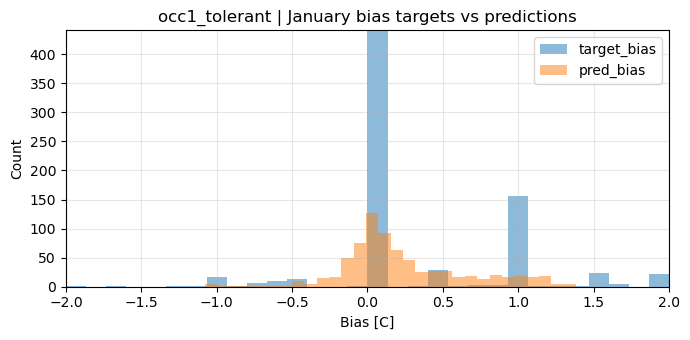


🔥 Training bias MLP for occ2_sensitive | rows=743 train=594 val=149
[BiasMLP] epoch=001 train_loss=0.134201 val_loss=0.138598
[BiasMLP] epoch=002 train_loss=0.124059 val_loss=0.130855
[BiasMLP] epoch=003 train_loss=0.116021 val_loss=0.123753
[BiasMLP] epoch=004 train_loss=0.110305 val_loss=0.118915
[BiasMLP] epoch=005 train_loss=0.106563 val_loss=0.115879
[BiasMLP] epoch=006 train_loss=0.104001 val_loss=0.113786
[BiasMLP] epoch=007 train_loss=0.101927 val_loss=0.112331
[BiasMLP] epoch=008 train_loss=0.100203 val_loss=0.111159
[BiasMLP] epoch=009 train_loss=0.098550 val_loss=0.110257
[BiasMLP] epoch=010 train_loss=0.097288 val_loss=0.109424
[BiasMLP] epoch=011 train_loss=0.096251 val_loss=0.108776
[BiasMLP] epoch=012 train_loss=0.095191 val_loss=0.107683
[BiasMLP] epoch=013 train_loss=0.094220 val_loss=0.107154
[BiasMLP] epoch=014 train_loss=0.093778 val_loss=0.107261
[BiasMLP] epoch=015 train_loss=0.093093 val_loss=0.106800
[BiasMLP] epoch=016 train_loss=0.092313 val_loss=0.106530
[Bi

,target_bias,pred_bias,bias_error
0,0.0,0.978695,0.978695
1,1.0,0.968186,-0.031814
2,1.0,0.953789,-0.046211
3,1.0,1.075495,0.075495
4,1.0,0.863975,-0.136025
5,1.0,0.865010,-0.134990
6,1.0,0.725810,-0.274190
7,0.0,0.433446,0.433446
8,0.0,0.484790,0.484790
9,1.0,0.785644,-0.214356


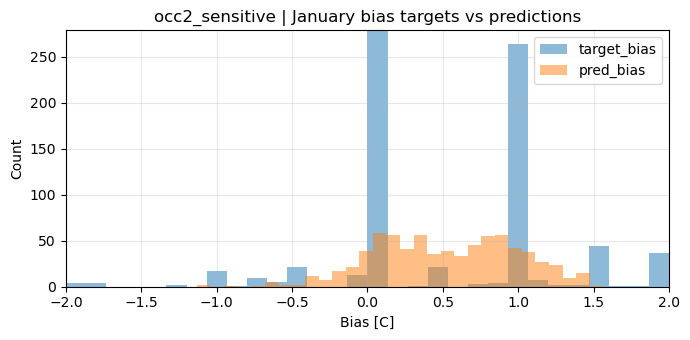


🔥 Training bias MLP for occ3_cold | rows=743 train=594 val=149
[BiasMLP] epoch=001 train_loss=0.104218 val_loss=0.097116
[BiasMLP] epoch=002 train_loss=0.095270 val_loss=0.090042
[BiasMLP] epoch=003 train_loss=0.089413 val_loss=0.085427
[BiasMLP] epoch=004 train_loss=0.085604 val_loss=0.081731
[BiasMLP] epoch=005 train_loss=0.082757 val_loss=0.078916
[BiasMLP] epoch=006 train_loss=0.081022 val_loss=0.076620
[BiasMLP] epoch=007 train_loss=0.079279 val_loss=0.075474
[BiasMLP] epoch=008 train_loss=0.077550 val_loss=0.075538
[BiasMLP] epoch=009 train_loss=0.076429 val_loss=0.074788
[BiasMLP] epoch=010 train_loss=0.075118 val_loss=0.073023
[BiasMLP] epoch=011 train_loss=0.074360 val_loss=0.072675
[BiasMLP] epoch=012 train_loss=0.073939 val_loss=0.072990
[BiasMLP] epoch=013 train_loss=0.072990 val_loss=0.074425
[BiasMLP] epoch=014 train_loss=0.072760 val_loss=0.074280
[BiasMLP] epoch=015 train_loss=0.072205 val_loss=0.073028
[BiasMLP] epoch=016 train_loss=0.071529 val_loss=0.072777
[BiasMLP

,target_bias,pred_bias,bias_error
0,0.0,-0.032129,-0.032129
1,0.0,-0.014795,-0.014795
2,0.0,0.019086,0.019086
3,0.0,0.068931,0.068931
4,0.0,0.105798,0.105798
5,0.5,0.163548,-0.336452
6,0.5,0.621941,0.121941
7,0.5,0.325324,-0.174676
8,0.0,0.140989,0.140989
9,0.0,0.003324,0.003324


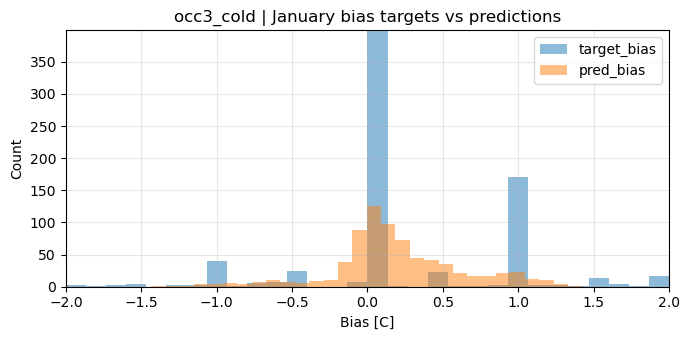


🔥 Training bias MLP for occ4_hot | rows=743 train=594 val=149
[BiasMLP] epoch=001 train_loss=0.141099 val_loss=0.150329
[BiasMLP] epoch=002 train_loss=0.124297 val_loss=0.145588
[BiasMLP] epoch=003 train_loss=0.118962 val_loss=0.142772
[BiasMLP] epoch=004 train_loss=0.114242 val_loss=0.139686
[BiasMLP] epoch=005 train_loss=0.111281 val_loss=0.136441
[BiasMLP] epoch=006 train_loss=0.108902 val_loss=0.133252
[BiasMLP] epoch=007 train_loss=0.105909 val_loss=0.131021
[BiasMLP] epoch=008 train_loss=0.104197 val_loss=0.129942
[BiasMLP] epoch=009 train_loss=0.102889 val_loss=0.129444
[BiasMLP] epoch=010 train_loss=0.102470 val_loss=0.129032
[BiasMLP] epoch=011 train_loss=0.101317 val_loss=0.127949
[BiasMLP] epoch=012 train_loss=0.100072 val_loss=0.127128
[BiasMLP] epoch=013 train_loss=0.099012 val_loss=0.126742
[BiasMLP] epoch=014 train_loss=0.098218 val_loss=0.126524
[BiasMLP] epoch=015 train_loss=0.097606 val_loss=0.126089
[BiasMLP] epoch=016 train_loss=0.096878 val_loss=0.125446
[BiasMLP]

,target_bias,pred_bias,bias_error
0,0.0,-0.004602,-0.004602
1,0.0,-0.038018,-0.038018
2,0.0,-0.061307,-0.061307
3,0.0,-0.060305,-0.060305
4,0.0,-0.033310,-0.033310
5,0.0,-0.002062,-0.002062
6,0.0,0.030221,0.030221
7,0.0,0.070484,0.070484
8,1.0,0.582061,-0.417939
9,1.0,1.073330,0.073330


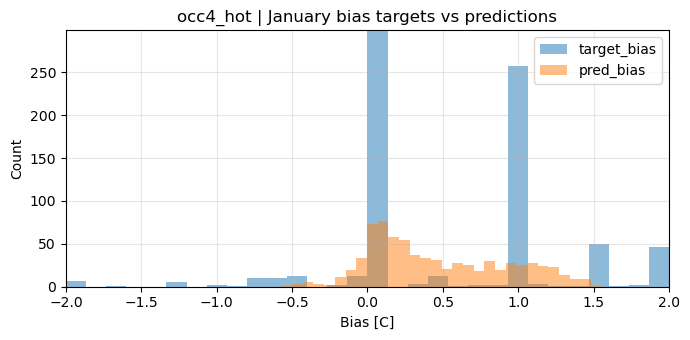

,occupant,checkpoint_path,raw_csv_path,supervised_csv_path,pred_csv_path,rows,target_bias_mean,target_bias_abs_mean,target_bias_std,pred_bias_mean,pred_bias_std,prediction_mae,prediction_rmse,prediction_corr,best_constant_bias,best_val_loss
0,occ1_tolerant,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,743,0.304727,0.420274,0.637853,0.240840,0.415473,0.311350,0.470027,0.684181,0.320699,0.074529
1,occ2_sensitive,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,743,0.516774,0.665570,0.742861,0.519365,0.466081,0.429771,0.578490,0.627366,0.534029,0.104500
2,occ3_cold,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,743,0.227955,0.459686,0.687068,0.193723,0.434793,0.338419,0.502190,0.686373,0.238426,0.072076
3,occ4_hot,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,/home/kostas/school/Y2/Zoltan/annex96_common_e...,743,0.544464,0.663576,0.748137,0.463249,0.449397,0.441518,0.613585,0.582634,0.552415,0.118134


In [117]:
# 11) Train occupant-specific January bias MLPs
if 'january_occ_envs' not in globals() or 'january_occ_datasets' not in globals():
    raise RuntimeError('Run the January occupant PI rollout cell first so january_occ_envs and january_occ_datasets exist.')

BIAS_MLP_DEVICE = device if 'device' in globals() else torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BIAS_MLP_CONFIG = BiasFeatureConfig(
    history_len=6,
    bias_max=2.0,
    hidden_dim=64,
    num_hidden_layers=2,
    dropout=0.0,
)
BIAS_MLP_EPOCHS = 50
BIAS_MLP_BATCH = 256
BIAS_MLP_LR = 1e-3
BIAS_MLP_WEIGHT_DECAY = 1e-5

january_bias_raw_frames = {}
january_bias_supervised_frames = {}
january_bias_prediction_frames = {}
bias_mlp_histories = {}
bias_mlp_checkpoints = {}
bias_mlp_summary_rows = []

for occ_idx, (short_label, env) in enumerate(january_occ_envs.items()):
    if short_label not in january_occ_datasets:
        raise KeyError(f'Missing January dataset for {short_label}.')

    seed_local = int(globals().get('RANDOM_SEED', 0)) + occ_idx
    np.random.seed(seed_local)
    random.seed(seed_local)
    torch.manual_seed(seed_local)

    long_label = BIAS_SHORT_TO_LONG.get(short_label, short_label)
    dataset = january_occ_datasets[short_label]

    raw_df = build_january_bias_rollout_dataframe(env, dataset)
    supervised_df = build_bias_training_dataframe(
        raw_df,
        history_len=BIAS_MLP_CONFIG.history_len,
        bias_max=BIAS_MLP_CONFIG.bias_max,
        steps_per_day=24,
    )

    n_total = len(supervised_df)
    n_train = max(1, int(0.8 * n_total))
    train_df = supervised_df.iloc[:n_train].reset_index(drop=True)
    val_df = supervised_df.iloc[n_train:].reset_index(drop=True)
    if len(val_df) == 0:
        val_df = train_df.copy()

    print()
    print(f"🔥 Training bias MLP for {long_label} | rows={n_total} train={len(train_df)} val={len(val_df)}")
    model, best_state, hist_df = train_bias_mlp_on_january(
        january_train_df=train_df,
        january_val_df=val_df,
        config=BIAS_MLP_CONFIG,
        device=BIAS_MLP_DEVICE,
        batch_size=BIAS_MLP_BATCH,
        lr=BIAS_MLP_LR,
        weight_decay=BIAS_MLP_WEIGHT_DECAY,
        epochs=BIAS_MLP_EPOCHS,
    )

    pred_df, pred_metrics = predict_bias_mlp_on_dataframe(
        model=model,
        df=supervised_df,
        feature_cols=best_state['feature_cols'],
        feature_mean=best_state['feature_mean'],
        feature_std=best_state['feature_std'],
        device=BIAS_MLP_DEVICE,
    )

    ckpt_path = NOTEBOOK_DIR / f'occ_bias_mlp_{long_label}.pt'
    raw_csv_path = NOTEBOOK_DIR / f'january_bias_raw_{long_label}.csv'
    supervised_csv_path = NOTEBOOK_DIR / f'january_bias_supervised_{long_label}.csv'
    pred_csv_path = NOTEBOOK_DIR / f'january_bias_predictions_{long_label}.csv'

    save_bias_mlp_checkpoint(best_state, ckpt_path)
    raw_df.to_csv(raw_csv_path, index=False)
    supervised_df.to_csv(supervised_csv_path, index=False)
    pred_df.to_csv(pred_csv_path, index=False)

    january_bias_raw_frames[long_label] = raw_df
    january_bias_supervised_frames[long_label] = supervised_df
    january_bias_prediction_frames[long_label] = pred_df
    bias_mlp_histories[long_label] = hist_df
    bias_mlp_checkpoints[long_label] = {
        'checkpoint_path': ckpt_path,
        'raw_csv_path': raw_csv_path,
        'supervised_csv_path': supervised_csv_path,
        'pred_csv_path': pred_csv_path,
        'best_constant_bias': float(best_state['best_constant_bias']),
        'best_val_loss': float(best_state['best_val_loss']),
    }

    target_bias = pred_df['target_bias'].to_numpy(dtype=np.float32)
    pred_bias = pred_df['pred_bias'].to_numpy(dtype=np.float32)

    print(f"{long_label} | sanity check | MAE={pred_metrics['mae']:.4f} RMSE={pred_metrics['rmse']:.4f} corr={pred_metrics['corr']:.4f}")
    display(pred_df[['target_bias', 'pred_bias', 'bias_error']].head(10))

    plt.figure(figsize=(7, 3.5))
    plt.hist(target_bias, bins=30, alpha=0.5, label='target_bias')
    plt.hist(pred_bias, bins=30, alpha=0.5, label='pred_bias')
    plt.title(f'{long_label} | January bias targets vs predictions')
    plt.xlabel('Bias [C]')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    bias_mlp_summary_rows.append({
        'occupant': long_label,
        'checkpoint_path': str(ckpt_path),
        'raw_csv_path': str(raw_csv_path),
        'supervised_csv_path': str(supervised_csv_path),
        'pred_csv_path': str(pred_csv_path),
        'rows': int(len(supervised_df)),
        'target_bias_mean': float(np.mean(target_bias)),
        'target_bias_abs_mean': float(np.mean(np.abs(target_bias))),
        'target_bias_std': float(np.std(target_bias)),
        'pred_bias_mean': float(np.mean(pred_bias)),
        'pred_bias_std': float(np.std(pred_bias)),
        'prediction_mae': float(pred_metrics['mae']),
        'prediction_rmse': float(pred_metrics['rmse']),
        'prediction_corr': float(pred_metrics['corr']) if not np.isnan(pred_metrics['corr']) else np.nan,
        'best_constant_bias': float(best_state['best_constant_bias']),
        'best_val_loss': float(best_state['best_val_loss']),
    })

bias_mlp_training_summary = pd.DataFrame(bias_mlp_summary_rows)
display(bias_mlp_training_summary)


In [21]:
'january_occ_envs' in globals(), 'january_occ_datasets' in globals()


(True, True)